# Auditing and Explaining Diabetes Risk Prediction Models: Project 2

Project 2 in 02820 Explainable AI and user experience, Group 4.

The Project 1 analysis repeated on the full BRFSS 2015 data (253,680 persons, imbalanced, three labels: no
diabetes, prediabetes, diabetes), followed by a technical audit of what the neural network has learned (section 12).
The description asks us to predict whether a person has prediabetes or diabetes; how to handle the three classes is
our choice (see the note in section 2).

What changed from Project 1:
- the models predict (pre)diabetes, i.e. prediabetes and diabetes merged; the three-class label is kept for
  stratifying the split and for results per class;
- the decision threshold is chosen on the validation set, since 0.5 is far too high with 16 % positives; class
  weights are compared as an alternative;
- the network has two hidden layers (128 and 64 units, L2 penalty 0.01), see 4.1;
- the evaluation adds balanced accuracy, average precision, recall per class and a calibration check;
- the logistic regression's exact contributions are compared with SHAP in the same unit (log-odds), and LIME is run
  with and without bins (7.3), answering the feedback on Project 1;
- all percentages use the 0-100 scale, and every figure uses the colour system from the redesigned Project 1 figures
  (see `xai_framework.py`, section 7);
- the director's points table greys out features the model is not reliable about;
- the patient note gives the real share with (pre)diabetes instead of "half of them".

Contents:
1. Setup
2. Data
3. Train/validation/test split
4. The two models: settings, threshold, calibration, the logistic regression's weights
5. Global explanations: SHAP for both models, LIME as a comparison
6. Local explanations for one person
7. Validating the explanations: against the exact contributions, deletion test, stability, safe advice
8. Errors and bias: missed cases per group, models without sex, income and education
9. What the patient can change
10. Stakeholder figures: data scientist, director, patient
11. Recommendation
12. Technical audit: what has the network learned?
    - 12.1 latent space, 12.2 concepts (probes, CAVs, TCAV, NMF), 12.3 hidden sensitive attributes
    - 12.4 removing concepts inside the network (ablation) and 12.5 a deeper network: our own additions beyond the
      course methods, so every choice there is explained in the text
    - 12.6 summary of the audit
13. Open points

Main results so far: AUC 0.815 (logistic regression) and 0.822 (network), both well calibrated; about 78 of 100
persons with (pre)diabetes are caught at 29 false alarms per 100, and young persons are mostly missed. The network's
score is driven by the metabolic profile, poor general health and cardiovascular history; social circumstances raise
it a little and stay encoded when sex, income and education are removed. Heavy drinking lowers the predicted risk in
both models, and a healthy lifestyle is barely rewarded. More layers give the same AUC.

Running it: Python 3.11 with numpy, pandas, scikit-learn 1.7, matplotlib, scipy, shap, lime and umap-learn. Run all
cells from this folder (about 12 minutes). Helper functions are in `xai_framework.py`, figures are saved in
`figures/<stakeholder>/`, and `EXAM_OVERVIEW.md` lists every choice in both projects with the reason for it.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import warnings
warnings.filterwarnings("ignore")

import xai_framework as xf
from xai_framework import (FEATURES, TARGET, TARGET_3, CLASS_NAMES, CODEBOOK, ACTIONABLE, MEDICAL, SENSITIVE,
                           COLORS, MODEL_COLORS, METHOD_COLORS, CLASS_COLORS)

xf.set_style()
pd.set_option("display.precision", 3)
np.random.seed(xf.SEED)

## 2. Data

In [2]:
df = xf.load_data()
print(df.shape)
df.head()

(253680, 23)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,0,1,1,1,40,1,0,0,0,0,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,0,25,1,0,0,1,0,...,1,3,0,0,0,0,7,6,1,0
2,0,1,1,1,28,0,0,0,0,1,...,1,5,30,30,1,0,9,4,8,0
3,0,1,0,1,27,0,0,0,1,1,...,0,2,0,0,0,0,11,3,6,0
4,0,1,1,1,24,0,0,0,1,1,...,0,2,3,0,0,0,11,5,4,0


In [3]:
# Codebook: plain-language labels + how actionable each feature is + whether it is sensitive
codebook = pd.DataFrame({f: vars(v) for f, v in CODEBOOK.items()}).T.drop(columns="values")
codebook

,label,description,kind,actionable,sensitive
HighBP,High blood pressure,Ever told by a health professional you have hi...,binary,medical,False
HighChol,High cholesterol,Ever told your blood cholesterol is high,binary,medical,False
CholCheck,Cholesterol check (5 yrs),Cholesterol checked within past 5 years,binary,no,False
BMI,Body mass index (BMI),Body mass index,continuous,yes,False
Smoker,Has smoked (100+ cigarettes),Smoked at least 100 cigarettes in entire life,binary,no,False
Stroke,Has had a stroke,Ever told you had a stroke,binary,no,False
HeartDiseaseorAttack,Heart disease / heart attack,Coronary heart disease or myocardial infarction,binary,no,False
PhysActivity,Physically active,Physical activity in past 30 days (not job),binary,yes,False
Fruits,Eats fruit daily,Consume fruit 1+ times per day,binary,yes,False
Veggies,Eats vegetables daily,Consume vegetables 1+ times per day,binary,yes,False


In [4]:
classes = df[TARGET_3].map(CLASS_NAMES).value_counts()
display(pd.DataFrame({"n": classes, "share": classes / len(df)}))
print(f"Merged target {TARGET} (prediabetes or diabetes): {df[TARGET].mean():.1%} positive")
print("Missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated(subset=FEATURES).sum()), "(plausible: many features are binary/ordinal)")
df.describe().T[["mean", "std", "min", "max"]]

,n,share
Diabetes_012,,
No diabetes,213703,0.842
Diabetes,35346,0.139
Prediabetes,4631,0.018


Merged target Diabetes_binary (prediabetes or diabetes): 15.8% positive
Missing values: 0
Exact duplicate rows: 25772 (plausible: many features are binary/ordinal)


,mean,std,min,max
Diabetes_012,0.297,0.698,0.0,2.0
HighBP,0.429,0.495,0.0,1.0
HighChol,0.424,0.494,0.0,1.0
CholCheck,0.963,0.190,0.0,1.0
BMI,28.382,6.609,12.0,98.0
Smoker,0.443,0.497,0.0,1.0
Stroke,0.041,0.197,0.0,1.0
HeartDiseaseorAttack,0.094,0.292,0.0,1.0
PhysActivity,0.757,0.429,0.0,1.0
Fruits,0.634,0.482,0.0,1.0


Always predicting "no diabetes" is right for 84 % of the persons, so accuracy says little here. Prediabetes is only
1.8 % of the data. As in Project 1 we merge it with diabetes into one positive class. This is our choice (the
description allows three classes): prediabetes has no region of its own in the latent space (12.1), screening leads to
the same next step for both (a blood test), and one calibrated score is easier to explain. The three-class label is kept
for stratifying the split and for reporting recall per class.

## 3. Train / validation / test split

In [5]:
X_train, X_val, X_test, y_train, y_val, y_test = xf.split_data(df)
y3_test = df.loc[X_test.index, TARGET_3]          # three-class label of the test persons
prevalence = y_train.mean()
pd.DataFrame({k: {"n": len(v), "share (pre)diabetes": y.mean(),
                  "share prediabetes": (df.loc[v.index, TARGET_3] == 1).mean()}
              for k, v, y in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]}).T

,n,share (pre)diabetes,share prediabetes
train,177576.0,0.158,0.018
validation,25368.0,0.158,0.018
test,50736.0,0.158,0.018


## 4. The two models

- **Logistic regression:** transparent, with one weight per feature. Its exact contributions are used as a ground truth
  to check SHAP and LIME.
- **Neural network:** a black box that can learn non-linear effects and interactions, which is the case XAI is meant for.

### 4.1 Chosen settings
Rerun on the new data (validation AUC; `xf.tune_lr` and `xf.tune_nn` take about a minute):
- Logistic regression: every C from 0.001 to 10 gives 0.814, so we keep C = 1.
- Neural network: the nine settings give 0.820-0.822. We pick 128 + 64 units with L2 penalty 0.01 (0.822) instead
  of Project 1's single layer of 32 units (0.821). The gain in AUC is within noise; the reason is the latent-space analysis
  (12.1): with two hidden layers we can follow how the representation changes from the inputs to the output, as in the
  week 9 exercise. It also keeps TCAV (12.2) possible: with one hidden layer the gradient from the hidden layer to
  the output is the same for every person, so TCAV could only return 0 or 1. Section 12.5 tests whether more layers
  help (they do not).

In [6]:
LR_PARAMS = dict(C=1.0)
NN_PARAMS = dict(hidden=(128, 64), alpha=1e-2)

### 4.2 Final models and threshold
With 16 % positives a threshold of 0.5 flags almost nobody, so each model gets a threshold chosen on the validation set.
Two rules are compared, and `THRESHOLD_RULE` sets the one used in the rest of the notebook (decision still open):
- **Youden's J:** maximise recall + specificity − 1, the point on the ROC curve furthest from the diagonal. A missed
  case and a false alarm weigh the same (as rates).
- **Recall 80 %:** the highest threshold that still catches 80 of 100 persons with (pre)diabetes. How many cases to
  catch is a decision for the stakeholders; the false alarms follow from it.

In [7]:
models = xf.make_models(LR_PARAMS, NN_PARAMS)
for name, m in models.items():
    m.fit(X_train, y_train)

THRESHOLD_RULE = "Youden's J"          # or "Recall 80 %"; used everywhere below
THR_ALL = {rule: {name: xf.choose_threshold(m, X_val, y_val, **kw) for name, m in models.items()}
           for rule, kw in xf.THRESHOLD_RULES.items()}
THR = THR_ALL[THRESHOLD_RULE]
print("Thresholds:", {r: {n: round(t, 3) for n, t in d.items()} for r, d in THR_ALL.items()}, "| used:", THRESHOLD_RULE)
pd.concat({"threshold 0.5": pd.DataFrame({n: xf.evaluate(m, X_val, y_val) for n, m in models.items()}).T}
          | {rule: pd.DataFrame({n: xf.evaluate(m, X_val, y_val, THR_ALL[rule][n]) for n, m in models.items()}).T
             for rule in THR_ALL})

Thresholds: {"Youden's J": {'Logistic regression': 0.157, 'Neural network': 0.154}, 'Recall 80 %': {'Logistic regression': 0.136, 'Neural network': 0.145}} | used: Youden's J


AUC  Average precision  Accuracy  \
threshold 0.5 Logistic regression  0.814              0.422     0.846   
              Neural network       0.822              0.450     0.850   
Youden's J    Logistic regression  0.814              0.422     0.729   
              Neural network       0.822              0.450     0.724   
Recall 80 %   Logistic regression  0.814              0.422     0.697   
              Neural network       0.822              0.450     0.711   

                                   Balanced accuracy  Recall (sensitivity)  \
threshold 0.5 Logistic regression              0.575                 0.180   
              Neural network                   0.579                 0.184   
Youden's J    Logistic regression              0.743                 0.764   
              Neural network                   0.749                 0.785   
Recall 80 %   Logistic regression              0.739                 0.800   
              Neural network                   0.747                 0.800   

                                   Specificity  Precision     F1  
threshold 0.5 Logistic regression        0.970      0.532  0.269  
              Neural network             0.974      0.571  0.278  
Youden's J    Logistic regression        0.722      0.340  0.470  
              Neural network             0.712      0.338  0.472  
Recall 80 %   Logistic regression        0.678      0.317  0.454  
              Neural network             0.695      0.329  0.466

In [8]:
# Final numbers on the untouched test set
test_results = pd.DataFrame({name: xf.evaluate(m, X_test, y_test, THR[name]) for name, m in models.items()}).T
test_results

,AUC,Average precision,Accuracy,Balanced accuracy,Recall (sensitivity),Specificity,Precision,F1
Logistic regression,0.815,0.428,0.728,0.741,0.759,0.723,0.339,0.468
Neural network,0.822,0.455,0.724,0.748,0.782,0.713,0.337,0.472


In [9]:
# The two rules on the test set, per 100 people (as the director would see it)
per100 = {}
for rule, thr in THR_ALL.items():
    for name, m in models.items():
        e = xf.evaluate(m, X_test, y_test, thr[name])
        per100[(rule, name)] = {"threshold": thr[name], "caught per 100 with (pre)diabetes": 100 * e["Recall (sensitivity)"],
                                "false alarms per 100 without": 100 * (1 - e["Specificity"]),
                                "flagged per 100 people": 100 * (xf.proba_fn(m)(X_test) >= thr[name]).mean(),
                                "of 100 flagged, have (pre)diabetes": 100 * e["Precision"]}
pd.DataFrame(per100).T.round(1).assign(threshold=lambda d: [round(v, 3) for v in pd.DataFrame(per100).T['threshold']])

threshold  caught per 100 with (pre)diabetes  \
Youden's J  Logistic regression      0.157                               75.9   
            Neural network           0.154                               78.2   
Recall 80 % Logistic regression      0.136                               80.4   
            Neural network           0.145                               80.3   

                                 false alarms per 100 without  \
Youden's J  Logistic regression                          27.7   
            Neural network                               28.7   
Recall 80 % Logistic regression                          31.9   
            Neural network                               30.5   

                                 flagged per 100 people  \
Youden's J  Logistic regression                    35.3   
            Neural network                         36.5   
Recall 80 % Logistic regression                    39.6   
            Neural network                         38.3   

                                 of 100 flagged, have (pre)diabetes  
Youden's J  Logistic regression                                33.9  
            Neural network                                     33.7  
Recall 80 % Logistic regression                                32.0  
            Neural network                                     33.0

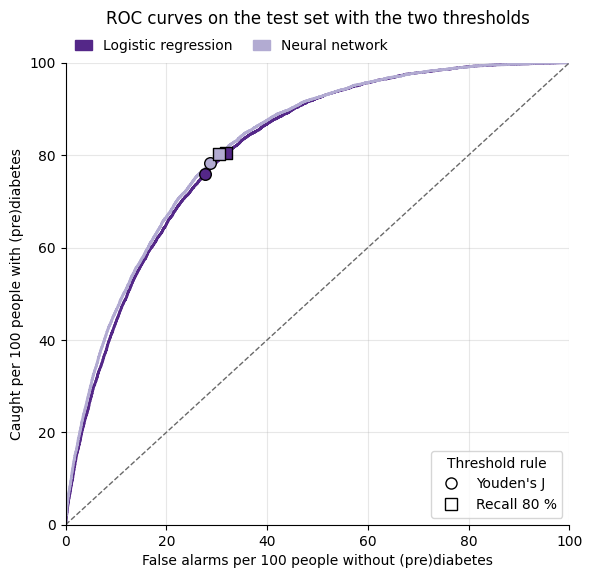

In [10]:
# ROC curves with the operating point of each rule marked (week 8: show the chosen threshold)
from sklearn.metrics import roc_curve
MARKERS = {"Youden's J": "o", "Recall 80 %": "s"}
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, m in models.items():
    p = xf.proba_fn(m)(X_test)
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr * 100, tpr * 100, color=MODEL_COLORS[name], lw=2)
    for rule, thr in THR_ALL.items():
        e = xf.evaluate(m, X_test, y_test, thr[name])
        ax.scatter(100 * (1 - e["Specificity"]), 100 * e["Recall (sensitivity)"], marker=MARKERS[rule], s=70,
                   color=MODEL_COLORS[name], edgecolor="black", zorder=3)
ax.plot([0, 100], [0, 100], color=COLORS["text2"], lw=1, ls="--")
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="False alarms per 100 people without (pre)diabetes",
       ylabel="Caught per 100 people with (pre)diabetes")
xf.micro_legend(ax, MODEL_COLORS, "ROC curves on the test set with the two thresholds")
ax.add_artist(ax.get_legend())
ax.legend(handles=[plt.Line2D([], [], marker=mk, ls="", markersize=8, color="white", markeredgecolor="black", label=rule)
                   for rule, mk in MARKERS.items()], loc="lower right", title="Threshold rule")
xf.savefig(fig, "data_scientist", "thresholds")
plt.show()

In [11]:
# Alternative to moving the threshold: class weights (a person with (pre)diabetes counts about 5x in the loss).
# Shown for the logistic regression; sklearn's MLP has no class weights.
lr_bal = xf.make_lr(**LR_PARAMS, class_weight="balanced").fit(X_train, y_train)
cal_bal = xf.calibration(lr_bal, X_test, y_test)
display(pd.DataFrame({"moved threshold (ours)": xf.evaluate(models["Logistic regression"], X_test, y_test, THR["Logistic regression"]),
                      "class weights, threshold 0.5": xf.evaluate(lr_bal, X_test, y_test, 0.5)}).T)
print(f"Mean predicted risk: unweighted {xf.proba_fn(models['Logistic regression'])(X_test).mean():.1%}, "
      f"class weights {xf.proba_fn(lr_bal)(X_test).mean():.1%}, observed {y_test.mean():.1%}")

,AUC,Average precision,Accuracy,Balanced accuracy,Recall (sensitivity),Specificity,Precision,F1
moved threshold (ours),0.815,0.428,0.728,0.741,0.759,0.723,0.339,0.468
"class weights, threshold 0.5",0.816,0.426,0.731,0.742,0.758,0.726,0.341,0.470


Mean predicted risk: unweighted 15.7%, class weights 39.4%, observed 15.8%


Class weights give the same AUC and almost the same recall and specificity at threshold 0.5 as our moved threshold,
but the mean predicted risk rises from 16 % to 39 % against 16 % observed: the score is no longer calibrated. Moving
the threshold keeps a score that can be read as a risk (4.3), which the patient and director figures rely on.

In [12]:
# Share flagged per class: the merged target hides how well prediabetes alone is caught
pd.DataFrame({name: xf.recall_per_class(m, X_test, y3_test, THR[name]) for name, m in models.items()}).T

,No diabetes,Prediabetes,Diabetes
Logistic regression,0.277,0.648,0.773
Neural network,0.287,0.678,0.796


In [13]:
# Is the network significantly better than the logistic regression? McNemar's test (paired: same test persons, chosen thresholds)
from scipy.stats import binomtest
correct = {name: ((xf.proba_fn(m)(X_test) >= THR[name]) == y_test).to_numpy() for name, m in models.items()}
only_lr = int((correct["Logistic regression"] & ~correct["Neural network"]).sum())
only_nn = int((~correct["Logistic regression"] & correct["Neural network"]).sum())
p_mcnemar = binomtest(only_lr, only_lr + only_nn, 0.5).pvalue
print(f"Only the logistic regression right: {only_lr} | only the network right: {only_nn} | McNemar (exact) p = {p_mcnemar:.1e}")

Only the logistic regression right: 1863 | only the network right: 1622 | McNemar (exact) p = 4.8e-05


### 4.3 Calibration
With the real prevalence the predicted risk could be read as a chance, but only if it is calibrated: among persons
given 20 %, about 20 % should have (pre)diabetes.

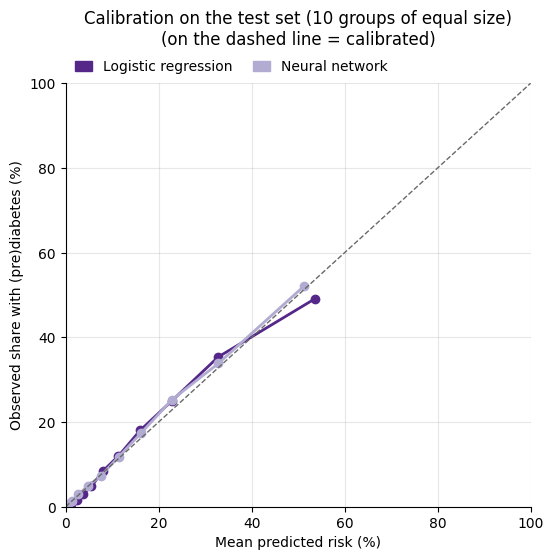

In [14]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for name, m in models.items():
    c = xf.calibration(m, X_test, y_test)
    ax.plot(c["mean predicted"] * 100, c["observed"] * 100, "o-", color=MODEL_COLORS[name], lw=2)
ax.plot([0, 100], [0, 100], color=COLORS["text2"], lw=1, ls="--")
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="Mean predicted risk (%)", ylabel="Observed share with (pre)diabetes (%)")
xf.micro_legend(ax, MODEL_COLORS, "Calibration on the test set (10 groups of equal size)\n(on the dashed line = calibrated)")
xf.savefig(fig, "data_scientist", "calibration")
plt.show()

### 4.4 The logistic regression explains itself
Each weight (coefficient) is a log-odds ratio: one unit more of the feature adds the weight to the log-odds of
(pre)diabetes for everyone, i.e. multiplies the odds by exp(weight). A person's exact contribution from a feature is
therefore weight × (value − background mean), in log-odds. These contributions, not the weights themselves, are the
ground truth in section 7. SHAP in probability units cannot match them exactly, because the sigmoid is not
additive; 7.3 therefore also computes SHAP in log-odds.

In [15]:
# One weight per feature, per unit (log-odds per BMI point, per yes, ...)
w = xf.lr_weights(models["Logistic regression"]).sort_values()
pd.DataFrame({"weight = log-odds ratio per unit": w, "odds ratio per unit": np.exp(w)}).round(3)

,weight = log-odds ratio per unit,odds ratio per unit
HvyAlcoholConsump,-0.686,0.504
Income,-0.057,0.944
PhysActivity,-0.047,0.954
Fruits,-0.046,0.955
Education,-0.039,0.962
Veggies,-0.030,0.970
PhysHlth,-0.007,0.993
MentHlth,-0.002,0.998
Smoker,0.003,1.003
BMI,0.062,1.064


## 5. Global explanations
SHAP works for any model, so we use it for both. It is computed for 1000 test persons with the same background sample,
in probability units. The mean absolute SHAP value gives a global ranking of the features.

In [16]:
X_explain = X_test.sample(1000, random_state=xf.SEED)
shap_expl = {name: xf.ShapExplainer(m, X_train) for name, m in models.items()}
shap_vals = {name: e(X_explain) for name, e in shap_expl.items()}   # neural network (permutation explainer) takes ~1 min

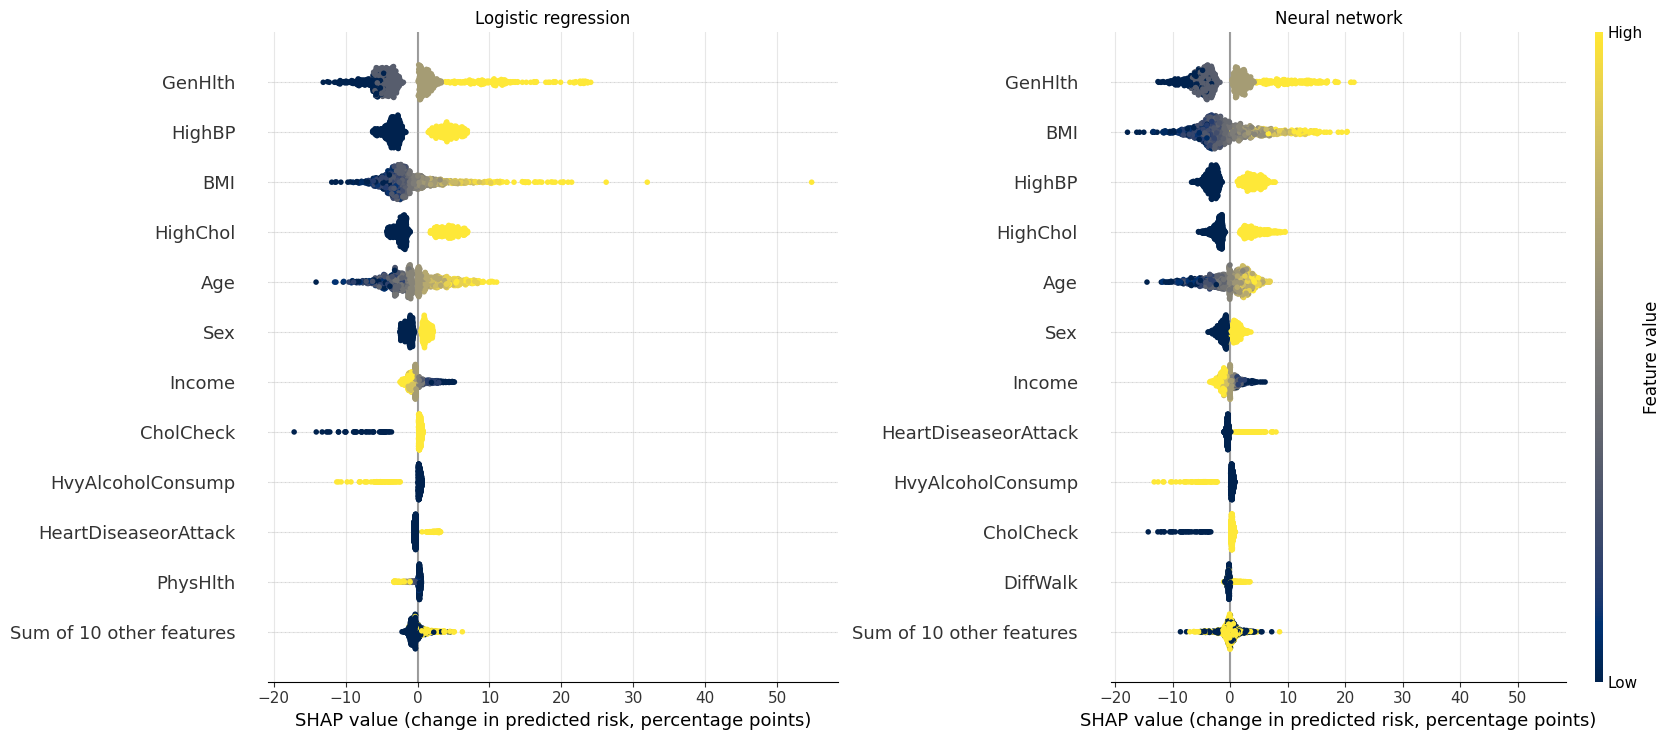

In [17]:
# SHAP summary (beeswarm) of both models, shared x-axis.
# Each dot is one person; colour = the feature's value (cividis: dark blue low, yellow high), position = how much it pushes the risk up or down.
fig = plt.figure(figsize=(17, 7.5))
axes = []
for k, name in enumerate(models):
    ax = fig.add_subplot(1, 2, k + 1)
    sv = shap_vals[name]
    sv_pp = shap.Explanation(sv.values * 100, base_values=sv.base_values * 100, data=sv.data, feature_names=sv.feature_names)
    shap.plots.beeswarm(sv_pp, max_display=12, show=False, ax=ax, plot_size=None, color_bar=(k == 1),
                        color=plt.get_cmap(xf.FEATURE_CMAP))
    ax.set_title(name)
    ax.set_xlabel("SHAP value (change in predicted risk, percentage points)")
    axes.append(ax)
xf.same_xlim(*axes)
plt.tight_layout()
xf.savefig(fig, "data_scientist", "shap_summary")
plt.show()

In [18]:
# Consistency across models: do the two models rely on the same features?
glob = pd.DataFrame({name: xf.ShapExplainer.global_importance(shap_vals[name]) for name in models}) * 100
top5 = {name: set(glob[name].nlargest(5).index) for name in models}
print("Top-5 features of both models:", sorted(top5["Logistic regression"] & top5["Neural network"]))
print("Only in one top-5:", sorted(top5["Logistic regression"] ^ top5["Neural network"]) or "none")
glob.round(2).sort_values("Neural network", ascending=False).head(10).rename(columns=lambda c: c + " (mean |SHAP|, pp)")

Top-5 features of both models: ['Age', 'BMI', 'GenHlth', 'HighBP', 'HighChol']
Only in one top-5: none


,"Logistic regression (mean |SHAP|, pp)","Neural network (mean |SHAP|, pp)"
GenHlth,5.09,5.15
BMI,3.61,4.38
HighBP,3.83,3.56
HighChol,3.20,3.10
Age,3.08,2.86
Sex,1.29,1.28
Income,1.13,1.21
HeartDiseaseorAttack,0.52,0.74
HvyAlcoholConsump,0.62,0.67
CholCheck,0.66,0.65


### 5.1 SHAP vs LIME on a global level
Averaging the absolute values over the same 100 test persons gives a global ranking for both methods. They use
different units, so each is shown as a share of its total. For the logistic regression we also show the exact
contributions.

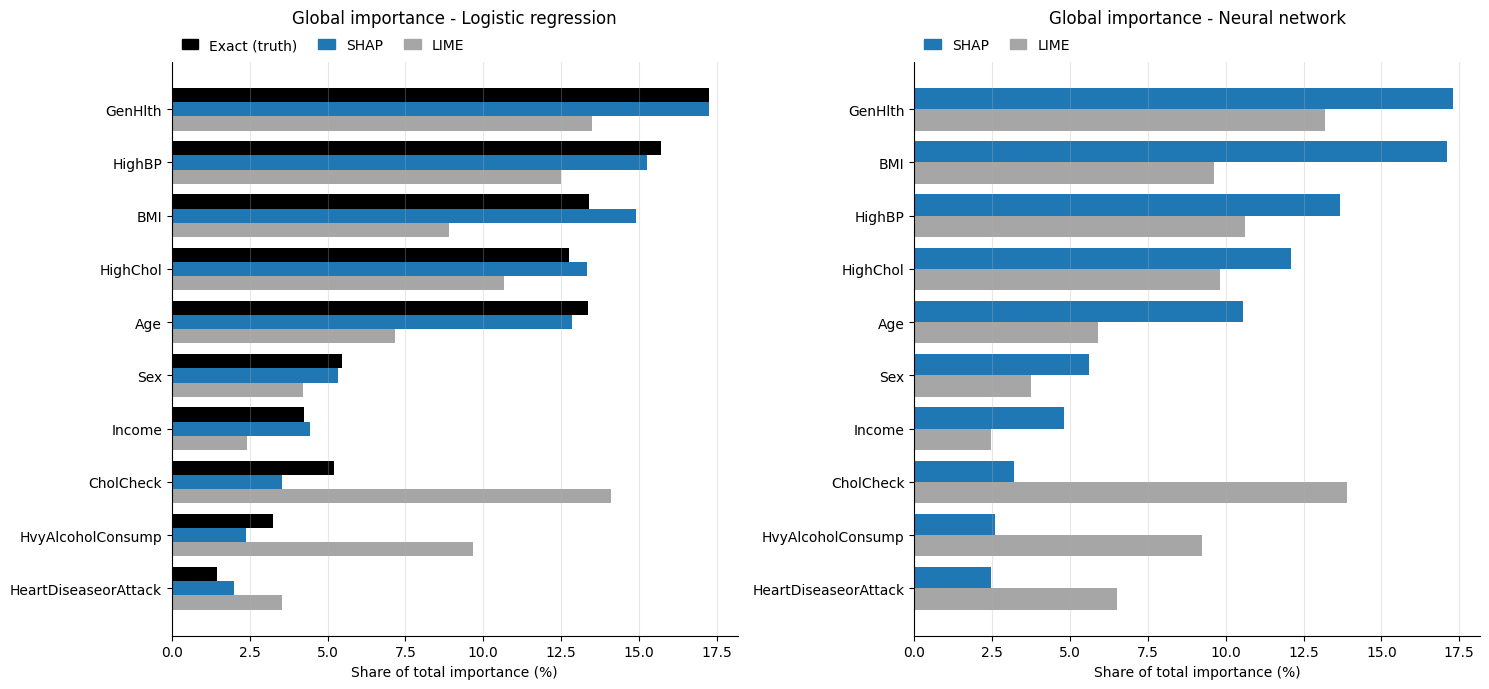

Logistic regression: global top-5 SHAP vs LIME 3/5 | SHAP vs exact 5/5 | LIME vs exact 3/5
Neural network: global top-5 SHAP vs LIME 4/5


In [19]:
lime_expl = {name: xf.LimeExplainer(m, X_train) for name, m in models.items()}
sub = X_explain.iloc[:100]
lime_W, lime_r2 = {}, {}
for name in models:
    lime_W[name], lime_r2[name] = lime_expl[name].explain_many(sub)
S = {name: pd.DataFrame(shap_vals[name].values[:100], index=sub.index, columns=FEATURES) for name in models}
LR_EXACT = xf.lr_contributions(models["Logistic regression"], sub, X_train)   # log-odds, same background as SHAP

share = lambda A: A.abs().mean() / A.abs().mean().sum() * 100
glob_cmp = {
    "Logistic regression": pd.DataFrame({"Exact (truth)": share(LR_EXACT), "SHAP": share(S["Logistic regression"]),
                                         "LIME": share(lime_W["Logistic regression"])}),
    "Neural network": pd.DataFrame({"SHAP": share(S["Neural network"]), "LIME": share(lime_W["Neural network"])}),
}
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
for ax, (name, g) in zip(axes, glob_cmp.items()):
    xf.plot_grouped_bars(ax, g.sort_values("SHAP").tail(10), title=f"Global importance - {name}",
                         xlabel="Share of total importance (%)", colors=METHOD_COLORS)
axes[1].tick_params(labelbottom=True)
plt.tight_layout()
xf.savefig(fig, "data_scientist", "global_shap_lime")
plt.show()
for name, g in glob_cmp.items():
    t5 = {col: set(g[col].nlargest(5).index) for col in g}
    line = f"{name}: global top-5 SHAP vs LIME {len(t5['SHAP'] & t5['LIME'])}/5"
    if "Exact (truth)" in t5:
        line += f" | SHAP vs exact {len(t5['SHAP'] & t5['Exact (truth)'])}/5 | LIME vs exact {len(t5['LIME'] & t5['Exact (truth)'])}/5"
    print(line)

## 6. Local explanations for one person
We use the same example person throughout (sections 6, 9 and 10.3): the first person in the sample who has
(pre)diabetes and is flagged by both models.

LIME's weights come from a local linear model on binned features, so only the signs and the ranking can be compared
with SHAP. Its R² shows how well that local model fits.

In [20]:
# Example person: true positive above the threshold in BOTH models
risk = pd.DataFrame({name: xf.proba_fn(m)(X_explain) for name, m in models.items()}, index=X_explain.index)
flagged_both = np.all([risk[n] >= THR[n] for n in models], axis=0)
pid = risk[flagged_both & (y_test.loc[X_explain.index] == 1).to_numpy()].index[0]
pos = X_explain.index.get_loc(pid)
x = X_test.loc[pid]
print(f"Person {pid}: true class {CLASS_NAMES[y3_test[pid]]} | " + " | ".join(f"{n}: {risk.loc[pid, n]:.0%}" for n in models))
pd.DataFrame({"value": x, "meaning": [xf.describe_value(f, v) for f, v in x.items()]})

Person 134330: true class Diabetes | Logistic regression: 30% | Neural network: 46%


,value,meaning
HighBP,1,Yes
HighChol,1,Yes
CholCheck,1,Yes
BMI,30,30
Smoker,0,No
Stroke,0,No
HeartDiseaseorAttack,0,No
PhysActivity,0,No
Fruits,0,No
Veggies,0,No


Logistic regression: LIME local fidelity (surrogate R^2) 0.26 | consistency, top-5 overlap SHAP vs LIME 0.25
Neural network: LIME local fidelity (surrogate R^2) 0.26 | consistency, top-5 overlap SHAP vs LIME 0.43


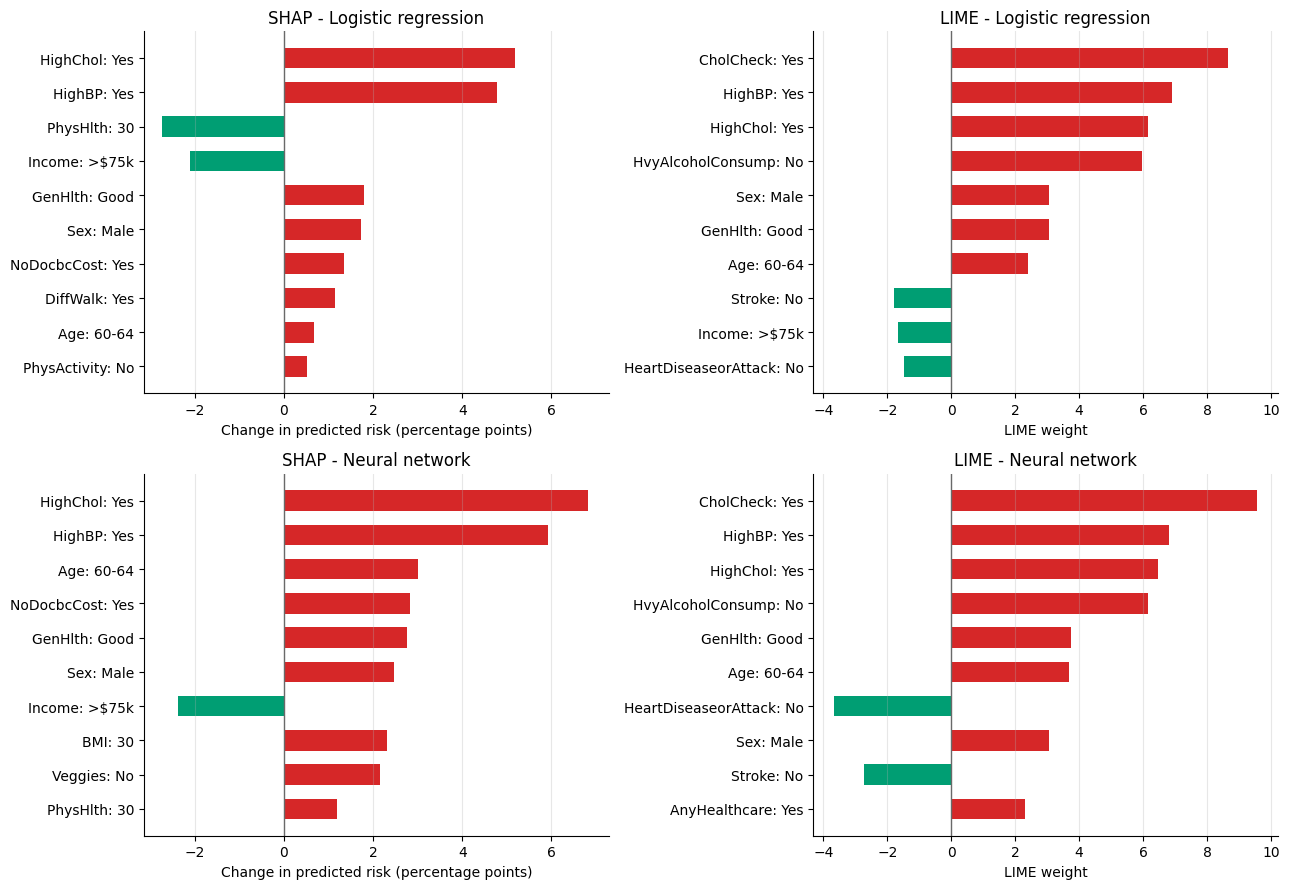

In [21]:
shap_local = {name: pd.Series(shap_vals[name].values[pos], index=FEATURES) for name in models}
lime_local = {}
# Labels show the person's own value (e.g. "HvyAlcoholConsump: No"): a bar is the effect of that value
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, name in zip(axes, models):
    lime_local[name], raw = lime_expl[name].explain(x)
    print(f"{name}: LIME local fidelity (surrogate R^2) {raw.score:.2f} | consistency, top-5 overlap SHAP vs LIME {xf.topk_overlap(shap_local[name], lime_local[name]):.2f}")
    xf.plot_contributions(row[0], shap_local[name], title=f"SHAP - {name}", plain_labels=False, min_abs=1e-4, values=x)
    xf.plot_contributions(row[1], lime_local[name], title=f"LIME - {name}", xlabel="LIME weight", plain_labels=False, values=x)
xf.same_xlim(axes[0, 0], axes[1, 0])
xf.same_xlim(axes[0, 1], axes[1, 1])
plt.tight_layout()
xf.savefig(fig, "data_scientist", "local_shap_lime")
plt.show()

## 7. Validating the explanations
We check five things:
1. Consistency: do SHAP and LIME agree on the top features?
2. Fidelity against the truth: do they match the exact contributions of the logistic regression? And how much of
   the difference comes from units (probability vs log-odds) and from LIME's bins?
3. Fidelity with a deletion test: does replacing the features an explanation calls important change the prediction
   more than replacing random features?
4. Stability: does LIME give the same answer when rerun, and does SHAP stay the same when BMI changes by one point?
5. Plausibility: does the healthy version of each habit actually lower the predicted risk?

In [22]:
# 7.1 Consistency between methods (SHAP vs LIME) and LIME's local fidelity, same 100 persons as §5.1
agreement = pd.DataFrame({name: {
    "consistency: top-5 Jaccard SHAP vs LIME": np.mean([xf.topk_overlap(S[name].loc[i], lime_W[name].loc[i]) for i in sub.index]),
    "LIME local fidelity R^2 (mean)": lime_r2[name].mean(),
    "LIME local fidelity R^2 (min)": lime_r2[name].min(),
} for name in models}).T
agreement

,consistency: top-5 Jaccard SHAP vs LIME,LIME local fidelity R^2 (mean),LIME local fidelity R^2 (min)
Logistic regression,0.526,0.473,0.254
Neural network,0.508,0.456,0.221


In [23]:
# 7.2 Fidelity against a ground truth: the logistic regression's exact contributions (LR_EXACT, §5.1).
# Same top-5 features per person, and the same direction for the features that matter (|exact| > 0.05 log-odds;
# smaller contributions are noise around zero, e.g. a BMI close to the average).
matter = (LR_EXACT.abs() > 0.05).to_numpy()
def fidelity(A):
    same_sign = np.sign(A.to_numpy()) == np.sign(LR_EXACT.to_numpy())
    return {"top-5 overlap with exact (Jaccard)": np.mean([xf.topk_overlap(A.loc[i], LR_EXACT.loc[i]) for i in sub.index]),
            "same direction as exact (features that matter)": same_sign[matter].mean()}
ground_truth = pd.DataFrame({"SHAP": fidelity(S["Logistic regression"]), "LIME": fidelity(lime_W["Logistic regression"])}).T
ground_truth

,top-5 overlap with exact (Jaccard),same direction as exact (features that matter)
SHAP,0.818,0.993
LIME,0.544,0.981


### 7.3 Units and bins: what the "exact" comparison really tests
Feedback on Project 1 asked whether "exact" meant the weights or the log-odds ratios, and why LIME binned BMI. The exact
contributions are in log-odds, SHAP was in probability, so part of the mismatch was the unit. LIME's bins are not part
of a linear surrogate as such: with `discretize_continuous=True` (LIME's default, our Project 1 setting) every
non-binary feature is replaced by "is the person in the same quartile bin", and the linear surrogate is fitted on these
indicators. We therefore compare four variants with the exact contributions for the same 100 persons: SHAP in
probability and in log-odds, and LIME with and without bins.

In [24]:
shap_lo = xf.ShapExplainer(models["Logistic regression"], X_train, output="log-odds")(sub)
S_LO = pd.DataFrame(shap_lo.values, index=sub.index, columns=FEATURES)
lime_nobin = {name: xf.LimeExplainer(m, X_train, discretize=False).explain_many(sub)[0] for name, m in models.items()}
variants = {"SHAP (probability)": S["Logistic regression"], "SHAP (log-odds)": S_LO,
            "LIME (quartile bins)": lime_W["Logistic regression"], "LIME (no bins)": lime_nobin["Logistic regression"]}
chol_rank = lambda A: A.abs().rank(axis=1, ascending=False)["CholCheck"].mean()
units = pd.DataFrame({k: {
    "top-5 overlap with exact (Jaccard)": np.mean([xf.topk_overlap(A.loc[i], LR_EXACT.loc[i]) for i in sub.index]),
    "correlation with exact (all persons x features)": np.corrcoef(A.to_numpy().ravel(), LR_EXACT.to_numpy().ravel())[0, 1],
    "mean rank of CholCheck (1 = most important)": chol_rank(A),
} for k, A in variants.items()}).T
units.loc["Exact (truth)"] = [1.0, 1.0, chol_rank(LR_EXACT)]
print(f"Largest |SHAP (log-odds) - exact|: {(S_LO - LR_EXACT).abs().max().max():.4f} log-odds")
units.round(3)

Largest |SHAP (log-odds) - exact|: 0.0000 log-odds


,top-5 overlap with exact (Jaccard),correlation with exact (all persons x features),mean rank of CholCheck (1 = most important)
SHAP (probability),0.818,0.921,9.60
SHAP (log-odds),1.000,1.000,7.83
LIME (quartile bins),0.544,0.782,1.97
LIME (no bins),0.451,0.771,1.29
Exact (truth),1.000,1.000,7.83


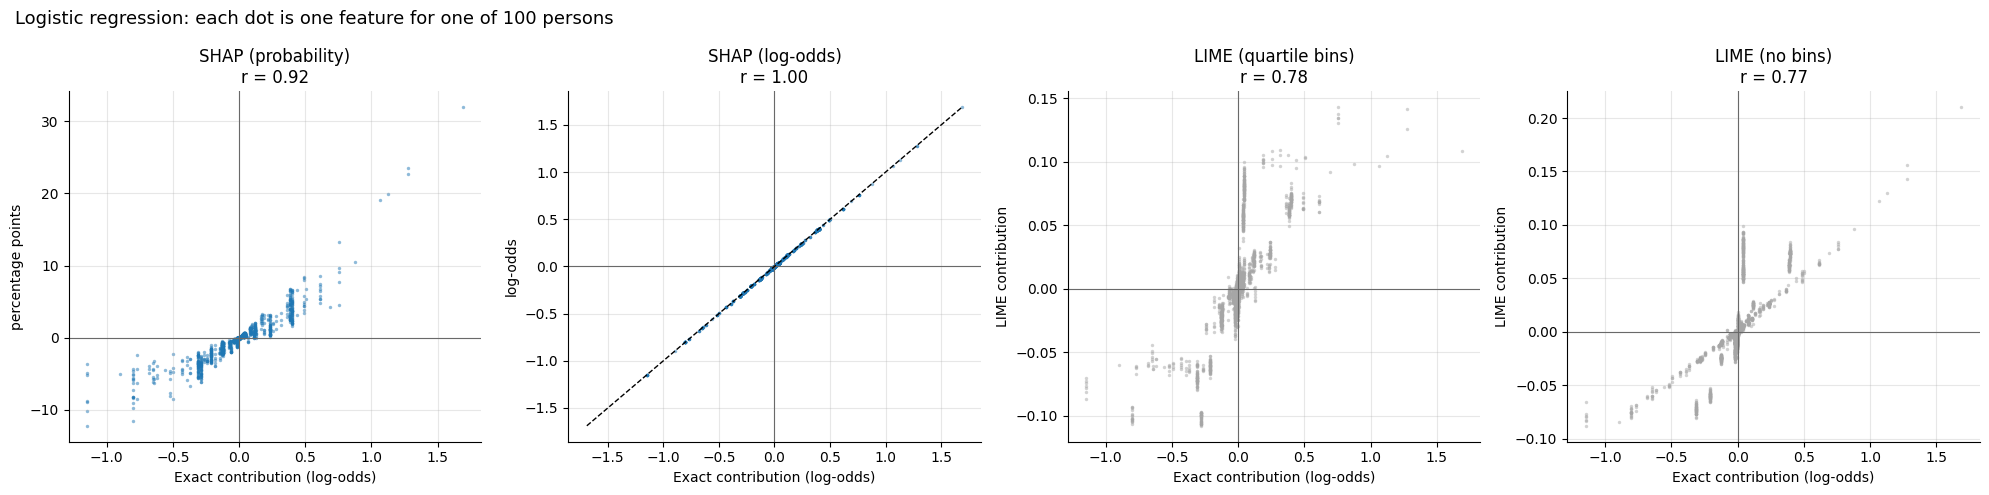

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (k, A) in zip(axes, variants.items()):
    color = METHOD_COLORS["SHAP"] if k.startswith("SHAP") else METHOD_COLORS["LIME"]
    ys = A.to_numpy().ravel() * (100 if k == "SHAP (probability)" else 1)
    ax.scatter(LR_EXACT.to_numpy().ravel(), ys, s=6, color=color, alpha=0.5, lw=0)
    ax.axhline(0, color=COLORS["text2"], lw=0.8); ax.axvline(0, color=COLORS["text2"], lw=0.8)
    if k == "SHAP (log-odds)":
        lim = np.abs(LR_EXACT.to_numpy()).max()
        ax.plot([-lim, lim], [-lim, lim], color="black", lw=1, ls="--")
    unit = "log-odds" if "log-odds" in k else "percentage points" if k.startswith("SHAP") else "LIME contribution"
    ax.set(title=f"{k}\nr = {units.loc[k, 'correlation with exact (all persons x features)']:.2f}",
           xlabel="Exact contribution (log-odds)", ylabel=unit)
fig.suptitle("Logistic regression: each dot is one feature for one of 100 persons", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
xf.savefig(fig, "data_scientist", "explanations_vs_exact")
plt.show()

In [26]:
# Consistency SHAP vs LIME without bins, both models (cf. 7.1 with bins)
pd.DataFrame({name: {"top-5 Jaccard SHAP vs LIME (bins)": agreement.loc[name, "consistency: top-5 Jaccard SHAP vs LIME"],
                     "top-5 Jaccard SHAP vs LIME (no bins)": np.mean([xf.topk_overlap(S[name].loc[i], lime_nobin[name].loc[i]) for i in sub.index])}
              for name in models}).T.round(3)

,top-5 Jaccard SHAP vs LIME (bins),top-5 Jaccard SHAP vs LIME (no bins)
Logistic regression,0.526,0.448
Neural network,0.508,0.399


**Result.** In log-odds, SHAP reproduces the exact contributions to four decimals (top-5 overlap 1.00), so the 0.82
overlap in probability units comes only from the sigmoid, not from SHAP. LIME stays further from the truth with or
without bins (overlap 0.54 and 0.45, correlation 0.78 and 0.77), so the bins are not the main problem. Both LIME
variants rank the cholesterol check close to first (mean rank 2.0 and 1.3), while it is 7.8 in the truth. LIME
samples every feature independently from the training data; since 96 % have had a cholesterol check, a sampled "no"
is a rare, large change in log-odds (weight 1.19, the largest of all), and the local surrogate gives it much weight.
SHAP averages over a background where almost everyone has a check, so it attributes little to it. We therefore trust
SHAP for both models and use LIME only as a check of the direction.

In [27]:
# 7.4 Fidelity (faithfulness), deletion test: SHAP ranking vs LIME ranking vs random ranking, same 100 persons.
# Mean |change in predicted risk| after replacing the k top features; a faithful explanation changes it fastest.
deletion = {}
for name, m in models.items():
    d_shap = xf.deletion_test(m, sub, S[name].to_numpy(), X_train)
    d_lime = xf.deletion_test(m, sub, lime_W[name].to_numpy(), X_train)
    deletion[name] = pd.DataFrame({"SHAP": d_shap["explanation"], "LIME": d_lime["explanation"], "Random": d_shap["random"]})
(pd.concat(deletion).loc[(slice(None), [1, 2, 3, 5]), :] * 100).round(2)   # percentage points

SHAP   LIME  Random
                    k                      
Logistic regression 1   6.66   4.67    1.30
                    2   9.18   6.30    2.89
                    3  11.09   8.67    3.58
                    5  13.67  12.31    5.34
Neural network      1   7.91   5.25    1.41
                    2  10.50   7.27    3.20
                    3  12.53   9.62    3.97
                    5  15.15  13.03    5.68

In [28]:
# 7.5 Stability of LIME: 5 re-runs with different seeds, for 5 persons per model
stability = pd.DataFrame({name: [xf.lime_stability(lime_expl[name], sub.iloc[i], n_runs=5)["mean_topk_jaccard"] for i in range(5)]
                          for name in models}, index=sub.index[:5])
stability.loc["mean"] = stability.mean()
stability

,Logistic regression,Neural network
2625,0.800,0.80
182660,0.800,0.80
7442,0.733,0.80
134330,1.000,1.00
137099,1.000,1.00
mean,0.867,0.88


In [29]:
# 7.5b Stability under a small input change (sensitivity): BMI + 1 for 50 persons.
# A stable explanation keeps (almost) the same top-5 when the person barely changes.
few = sub.iloc[:50]
nudged = few.assign(BMI=few["BMI"] + 1)
sensitivity = {}
for name, m in models.items():
    before = pd.DataFrame(shap_expl[name](few).values, index=few.index, columns=FEATURES)
    after = pd.DataFrame(shap_expl[name](nudged).values, index=few.index, columns=FEATURES)
    sensitivity[name] = {
        "SHAP top-5 overlap before/after": np.mean([xf.topk_overlap(before.loc[i], after.loc[i]) for i in few.index]),
        "share of persons with the same top-5": np.mean([xf.topk_overlap(before.loc[i], after.loc[i]) == 1 for i in few.index]),
        "mean |change in risk| (pp)": 100 * np.abs(xf.proba_fn(m)(nudged) - xf.proba_fn(m)(few)).mean(),
    }
pd.DataFrame(sensitivity).T

,SHAP top-5 overlap before/after,share of persons with the same top-5,mean |change in risk| (pp)
Logistic regression,0.953,0.86,0.706
Neural network,0.947,0.84,0.966


In [30]:
# 7.6 Plausibility of the advice (advice safety) on the full test set: does the healthy change lower risk?
safety = pd.concat({name: xf.advice_safety(m, X_test) for name, m in models.items()})
unsafe = {name: safety.loc[name].index[safety.loc[name]["flag"] == "UNSAFE"].tolist() for name in models}
print("Unsafe features:", unsafe)
safety.style.apply(lambda r: ["background-color: #fbd9d8" if r["flag"] == "UNSAFE" else "" for _ in r], axis=1)

Unsafe features: {'Logistic regression': ['HvyAlcoholConsump', 'MentHlth', 'PhysHlth'], 'Neural network': ['Veggies', 'HvyAlcoholConsump', 'MentHlth', 'PhysHlth']}


In [31]:
# What a wrong heavy-drinking effect costs: missed cases among heavy drinkers vs others (chosen thresholds)
heavy = (X_test["HvyAlcoholConsump"] == 1) & (y_test == 1)
others = (X_test["HvyAlcoholConsump"] == 0) & (y_test == 1)
pd.DataFrame({name: {"missed, heavy drinkers with (pre)diabetes": (xf.proba_fn(m)(X_test[heavy]) < THR[name]).mean(),
                     "missed, others with (pre)diabetes": (xf.proba_fn(m)(X_test[others]) < THR[name]).mean(),
                     "n heavy drinkers with (pre)diabetes": int(heavy.sum())} for name, m in models.items()}).T

,"missed, heavy drinkers with (pre)diabetes","missed, others with (pre)diabetes",n heavy drinkers with (pre)diabetes
Logistic regression,0.540,0.233,211.0
Neural network,0.493,0.210,211.0


In [32]:
# Fix attempt: retrain both models without heavy drinking and compare (each model gets its own validation threshold)
NO_HVY = [f for f in FEATURES if f != "HvyAlcoholConsump"]
no_hvy = xf.make_models(LR_PARAMS, NN_PARAMS)
for m in no_hvy.values():
    m.fit(X_train[NO_HVY], y_train)
heavy_all = X_test["HvyAlcoholConsump"] == 1
rows = {}
for name in models:
    for version, m in [("with heavy drinking", models[name]), ("without heavy drinking", no_hvy[name])]:
        t = xf.choose_threshold(m, X_val, y_val, **xf.THRESHOLD_RULES[THRESHOLD_RULE])
        p = xf.proba_fn(m)(X_test)
        s = xf.advice_safety(m, X_test, features=[f for f in ACTIONABLE + MEDICAL if f in xf.model_columns(m)])
        rows[(name, version)] = {
            "test AUC": xf.evaluate(m, X_test, y_test)["AUC"],
            "mean score of heavy drinkers": 100 * p[heavy_all.to_numpy()].mean(),
            "missed, heavy drinkers with (pre)diabetes": (p[heavy.to_numpy()] < t).mean(),
            "unsafe features": ", ".join(s.index[s["flag"] == "UNSAFE"]),
            "largest unsafe effect (pp)": s["mean Δ risk (pp)"].max(),
        }
pd.DataFrame(rows).T.round(3)

test AUC  \
Logistic regression with heavy drinking       0.815   
                    without heavy drinking    0.814   
Neural network      with heavy drinking       0.822   
                    without heavy drinking    0.821   

                                           mean score of heavy drinkers  \
Logistic regression with heavy drinking                           7.105   
                    without heavy drinking                       11.872   
Neural network      with heavy drinking                           6.758   
                    without heavy drinking                       12.236   

                                           missed, heavy drinkers with (pre)diabetes  \
Logistic regression with heavy drinking                                         0.54   
                    without heavy drinking                                     0.284   
Neural network      with heavy drinking                                        0.493   
                    without heavy drinking                                     0.299   

                                                                           unsafe features  \
Logistic regression with heavy drinking              HvyAlcoholConsump, MentHlth, PhysHlth   
                    without heavy drinking                              MentHlth, PhysHlth   
Neural network      with heavy drinking     Veggies, HvyAlcoholConsump, MentHlth, PhysHlth   
                    without heavy drinking                     Veggies, MentHlth, PhysHlth   

                                           largest unsafe effect (pp)  
Logistic regression with heavy drinking                         5.108  
                    without heavy drinking                      0.381  
Neural network      with heavy drinking                         5.239  
                    without heavy drinking                      0.333

**Heavy drinking.** The problem from Project 1 remains on the new data. In both models stopping heavy drinking raises
the predicted risk by about 5 percentage points, and about half of the heavy drinkers with (pre)diabetes are missed
(54 % and 49 %) against 21-23 % of everyone else. Heavy drinkers are probably people without diabetes so far (people
with diabetes are advised to drink less), so the survey links drinking with health. Retraining without heavy drinking
costs at most 0.001 in AUC, raises the mean score of heavy drinkers from about 7 to 12, and nearly halves their missed
cases (to 28-30 %). The remaining unsafe effects are below 0.4 percentage points. The network also rewards
vegetables slightly in the wrong direction. A deployed model should be the retrained one.

### 7.7 Summary of the validation
All checks are functionally grounded (no people involved), so they test whether the explanations match the models, not
whether people understand them. The table is filled in from the results above once the analysis is final.

| Property | Matters most for | How we measure it | Result | We stop trusting it if |
|---|---|---|---|---|
| Fidelity (ground truth) | All | Top-5 overlap with the exact contributions of the logistic regression, and same direction | | it ranks features differently from the model |
| Fidelity (global) | Data scientist | Global top-5 over 100 persons vs. the exact top-5 | | the global picture differs from the truth |
| Fidelity (deletion test) | All | Change in prediction when replacing the top-k features vs. k random ones | | important features matter no more than random ones |
| Consistency | Data scientist | Top-5 overlap SHAP vs. LIME | | they disagree and neither passes the fidelity tests |
| Stability (reruns) | Data scientist | LIME rerun with 5 seeds | | the explanation changes between runs |
| Stability (small change) | Data scientist, patient | SHAP top-5 before and after BMI + 1 | | a tiny change gives a different explanation |
| Accuracy per group | Data scientist, patient | Missed cases per sex, age and income (section 8) | | a group is often wrong without us saying so |
| Calibration | Director, patient | Reliability diagram (section 4.3) | | the score is read as a chance but is not one |
| Plausibility | Patient, director | Effect of the healthy change on the predicted risk | | a healthy change raises the risk |
| Understandability | Patient, director | Feedback from the role-play | | users draw the wrong conclusion |

## 8. Errors and bias
Sex, age, income and education are sensitive features. None of them can be changed, and income and education are
proxies for socio-economic status. Below we look at the errors per group at the chosen thresholds. Age is kept in the
model, since it is an established risk factor.

In [33]:
for f in SENSITIVE:
    print(f"\n=== {xf.label(f)} ===")
    reps = {name: xf.subgroup_report(m, X_test, y_test, f, THR[name]) for name, m in models.items()}
    first = next(iter(reps.values()))[["n", "prevalence"]]
    display(pd.concat({"": first} | {name: r[["AUC", "Specificity", "FNR (missed cases)"]] for name, r in reps.items()}, axis=1))


=== Sex ===


Logistic regression                                 \
            n prevalence                 AUC Specificity FNR (missed cases)   
group                                                                         
Female  28209      0.148               0.826       0.753              0.251   
Male    22527      0.169               0.800       0.684              0.231   

       Neural network                                 
                  AUC Specificity FNR (missed cases)  
group                                                 
Female          0.832       0.748              0.237  
Male            0.809       0.667              0.196


=== Age group ===


Logistic regression                                 \
          n prevalence                 AUC Specificity FNR (missed cases)   
group                                                                       
18-24  1095      0.020               0.695       0.983              0.955   
25-29  1575      0.022               0.783       0.964              0.629   
30-34  2170      0.035               0.808       0.951              0.605   
35-39  2811      0.059               0.805       0.929              0.584   
40-44  3275      0.070               0.832       0.893              0.474   
45-49  4059      0.101               0.834       0.855              0.401   
50-54  5172      0.137               0.816       0.802              0.346   
55-59  6205      0.148               0.814       0.731              0.241   
60-64  6693      0.197               0.805       0.674              0.210   
65-69  6509      0.227               0.778       0.615              0.199   
70-74  4564      0.251               0.752       0.529              0.170   
75-79  3157      0.246               0.730       0.439              0.165   
80+    3451      0.206               0.687       0.383              0.153   

      Neural network                                 
                 AUC Specificity FNR (missed cases)  
group                                                
18-24          0.698       0.992              0.909  
25-29          0.784       0.975              0.629  
30-34          0.822       0.961              0.592  
35-39          0.814       0.930              0.554  
40-44          0.836       0.887              0.465  
45-49          0.840       0.833              0.350  
50-54          0.819       0.769              0.312  
55-59          0.819       0.692              0.198  
60-64          0.808       0.640              0.169  
65-69          0.783       0.577              0.163  
70-74          0.765       0.528              0.148  
75-79          0.736       0.470              0.166  
80+            0.696       0.481              0.203


=== Education level ===


Logistic regression              \
                      n prevalence                 AUC Specificity   
group                                                                
Elementary          791      0.326               0.750       0.388   
Some high school   1899      0.287               0.743       0.460   
High school grad  12578      0.198               0.785       0.607   
Some college      13931      0.168               0.808       0.708   
College grad      21505      0.109               0.827       0.821   

                                    Neural network              \
                 FNR (missed cases)            AUC Specificity   
group                                                            
Elementary                    0.101          0.760       0.415   
Some high school              0.121          0.753       0.482   
High school grad              0.180          0.797       0.615   
Some college                  0.235          0.816       0.694   
College grad                  0.356          0.832       0.800   

                                     
                 FNR (missed cases)  
group                                
Elementary                    0.093  
Some high school              0.141  
High school grad              0.172  
Some college                  0.208  
College grad                  0.307


=== Income level ===


Logistic regression                                 \
             n prevalence                 AUC Specificity FNR (missed cases)   
group                                                                          
<$10k     1987      0.279               0.769       0.482              0.106   
$10-15k   2302      0.301               0.754       0.421              0.097   
$15-20k   3138      0.250               0.761       0.489              0.123   
$20-25k   4064      0.220               0.787       0.557              0.136   
$25-35k   5161      0.194               0.778       0.613              0.199   
$35-50k   7322      0.161               0.784       0.686              0.259   
$50-75k   8657      0.143               0.804       0.768              0.321   
>$75k    18105      0.091               0.830       0.860              0.414   

        Neural network                                 
                   AUC Specificity FNR (missed cases)  
group                                                  
<$10k            0.779       0.512              0.121  
$10-15k          0.762       0.449              0.101  
$15-20k          0.775       0.513              0.126  
$20-25k          0.800       0.569              0.142  
$25-35k          0.790       0.612              0.191  
$35-50k          0.792       0.664              0.217  
$50-75k          0.812       0.745              0.260  
>$75k            0.834       0.841              0.368

In [34]:
for name, m in models.items():
    fn, fp = xf.error_cases(m, X_test, y_test, THR[name], k=5)
    print(f"=== {name} ===\nMost confident FALSE NEGATIVES (diabetes, predicted low risk):")
    display(fn)
    print("Most confident FALSE POSITIVES (no diabetes, predicted high risk):")
    display(fp)

=== Logistic regression ===
Most confident FALSE NEGATIVES (diabetes, predicted low risk):


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,risk,y
115420,0,0,1,20,1,0,0,1,1,1,...,2,14,7,0,0,3,5,8,0.006,1
125155,0,0,1,21,0,0,0,1,1,1,...,1,0,0,0,0,3,5,7,0.008,1
220269,0,0,1,20,0,0,0,1,1,1,...,1,0,0,0,1,2,6,7,0.008,1
44787,0,0,1,23,0,0,0,1,1,1,...,1,0,0,0,0,2,6,5,0.009,1
87345,0,0,1,24,0,0,0,1,0,1,...,1,0,0,0,1,5,5,4,0.009,1


Most confident FALSE POSITIVES (no diabetes, predicted high risk):


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,risk,y
76383,1,1,1,87,1,0,0,0,0,0,...,5,30,3,1,0,7,4,1,0.977,0
79478,1,1,1,98,0,0,0,1,1,1,...,3,4,0,1,0,10,4,6,0.969,0
79501,1,1,1,87,0,0,0,0,1,1,...,4,6,3,1,0,10,5,5,0.968,0
76469,1,1,1,71,0,0,1,1,1,1,...,4,26,15,1,1,10,3,2,0.949,0
79349,1,1,1,92,1,0,0,1,0,0,...,3,30,0,0,0,9,3,6,0.948,0


=== Neural network ===
Most confident FALSE NEGATIVES (diabetes, predicted low risk):


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,risk,y
125155,0,0,1,21,0,0,0,1,1,1,...,1,0,0,0,0,3,5,7,0.002,1
220269,0,0,1,20,0,0,0,1,1,1,...,1,0,0,0,1,2,6,7,0.002,1
115420,0,0,1,20,1,0,0,1,1,1,...,2,14,7,0,0,3,5,8,0.003,1
44787,0,0,1,23,0,0,0,1,1,1,...,1,0,0,0,0,2,6,5,0.003,1
36431,0,0,1,20,0,0,0,1,1,0,...,2,4,0,0,0,2,6,8,0.003,1


Most confident FALSE POSITIVES (no diabetes, predicted high risk):


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,risk,y
4722,1,1,1,50,1,1,1,0,0,1,...,5,5,30,1,1,8,5,1,0.811,0
240097,1,1,1,64,1,0,1,0,0,1,...,5,0,30,1,0,12,5,4,0.780,0
26922,1,1,1,44,1,0,1,1,0,0,...,5,0,30,1,1,9,6,4,0.780,0
101859,1,1,1,58,0,0,1,0,1,1,...,5,0,20,1,0,10,5,2,0.777,0
113430,1,1,1,39,1,1,1,0,1,1,...,5,20,30,1,0,10,5,3,0.764,0


### 8.1 Removing sex, income and education
We retrain both models without these features and compare the missed cases per group.

In [35]:
NO_SENS = [f for f in FEATURES if f not in ["Sex", "Income", "Education"]]
no_sens = xf.make_models(LR_PARAMS, NN_PARAMS)
for m in no_sens.values():
    m.fit(X_train[NO_SENS], y_train)
rows = {}
for name in models:
    for version, m in [("all features", models[name]), ("without sex/income/education", no_sens[name])]:
        t = xf.choose_threshold(m, X_val, y_val, **xf.THRESHOLD_RULES[THRESHOLD_RULE])
        sex = xf.subgroup_report(m, X_test, y_test, "Sex", t)["FNR (missed cases)"]
        inc = xf.subgroup_report(m, X_test, y_test, "Income", t)["FNR (missed cases)"]
        rows[(name, version)] = {"test AUC": xf.evaluate(m, X_test, y_test)["AUC"],
                                 "missed, women": sex["Female"], "missed, men": sex["Male"],
                                 "missed, lowest income": inc.iloc[0], "missed, highest income": inc.iloc[-1]}
pd.DataFrame(rows).T.round(3)

test AUC  missed, women  \
Logistic regression all features                     0.815          0.251   
                    without sex/income/education     0.813          0.177   
Neural network      all features                     0.822          0.237   
                    without sex/income/education     0.820          0.225   

                                                  missed, men  \
Logistic regression all features                        0.231   
                    without sex/income/education        0.194   
Neural network      all features                        0.196   
                    without sex/income/education        0.249   

                                                  missed, lowest income  \
Logistic regression all features                                  0.106   
                    without sex/income/education                  0.105   
Neural network      all features                                  0.121   
                    without sex/income/education                  0.146   

                                                  missed, highest income  
Logistic regression all features                                   0.414  
                    without sex/income/education                   0.310  
Neural network      all features                                   0.368  
                    without sex/income/education                   0.378

## 9. What the patient can change
For the example person we search for healthy, realistic changes (BMI down to at least 22, start exercising, eat fruit
or vegetables, stop heavy drinking). Features flagged as unsafe in 7.6 are never suggested.

In [36]:
print("Actionable:", ACTIONABLE, "\nHealth status (managed with a doctor):", MEDICAL)
cf = {name: xf.counterfactual_search(m, x, max_changes=3, exclude=unsafe[name]) for name, m in models.items()}
pd.concat(cf)

Actionable: ['BMI', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump'] 
Health status (managed with a doctor): ['HighBP', 'HighChol', 'GenHlth', 'MentHlth', 'PhysHlth']


step   risk
Logistic regression 0                          current  0.304
                    1  Body mass index (BMI): 30 -> 25  0.243
                    2  Body mass index (BMI): 25 -> 22  0.210
                    3     Physically active: No -> Yes  0.202
Neural network      0                          current  0.457
                    1  Body mass index (BMI): 30 -> 25  0.372
                    2  Body mass index (BMI): 25 -> 22  0.289
                    3     Physically active: No -> Yes  0.252

## 10. Stakeholder figures
The figures used in the presentation and the report, saved in `figures/<stakeholder>/`. Colours follow one system in
every figure (red/green = raises/lowers the risk, dark/light purple = logistic regression/neural network, black/blue/grey
= exact/SHAP/LIME, grey = neutral), with a one-line legend above each plot.

### 10.1 Head of data science
Needs high fidelity, global importance, error analysis and edge cases. The SHAP summary, the SHAP/LIME comparisons and
the calibration are made in sections 4-6; here we add where the models fail and whether the advice is safe.

In [37]:
def plot_missed_by_age(ax):
    fnr = pd.DataFrame({name: xf.subgroup_report(m, X_test, y_test, "Age", THR[name])["FNR (missed cases)"]
                        for name, m in models.items()}) * 100
    w = 0.4
    for i, name in enumerate(models):
        ax.bar(np.arange(len(fnr)) + (i - 0.5) * w, fnr[name], width=w, color=MODEL_COLORS[name])
    # n = persons WITH (pre)diabetes per age group - the youngest groups have few, so their rates are uncertain
    age = xf.subgroup_report(models["Logistic regression"], X_test, y_test, "Age", THR["Logistic regression"])
    n_pos = (age["n"] * age["prevalence"]).round().astype(int)
    ax.set_xticks(np.arange(len(fnr)), [f"{g}\n{k}" for g, k in n_pos.items()], fontsize=8)
    ax.set(ylim=(0, 105), ylabel="Missed cases (%)")
    ax.grid(axis="x", visible=False)
    xf.micro_legend(ax, MODEL_COLORS, "Missed cases by age group\n(number under each group = persons with (pre)diabetes)")

def plot_advice_safety(ax):
    eff = safety["mean Δ risk (pp)"].unstack(0)[list(models)].sort_values("Neural network")
    xf.plot_grouped_bars(ax, eff, xlabel="Mean change in predicted risk (percentage points)",
                         title="Effect of the healthy change on the predicted risk\n(right of 0 = the model punishes a healthy change)")
    hi = max(eff.max().max(), 0) * 1.1 + 0.5
    ax.axvspan(0, hi, color=COLORS["increase"], alpha=0.08)
    ax.text(hi - 0.1, 0.2, "unsafe", ha="right", va="center", color=COLORS["increase"], fontsize=10, fontweight="bold")
    ax.axvline(0, color=COLORS["text2"], lw=1)

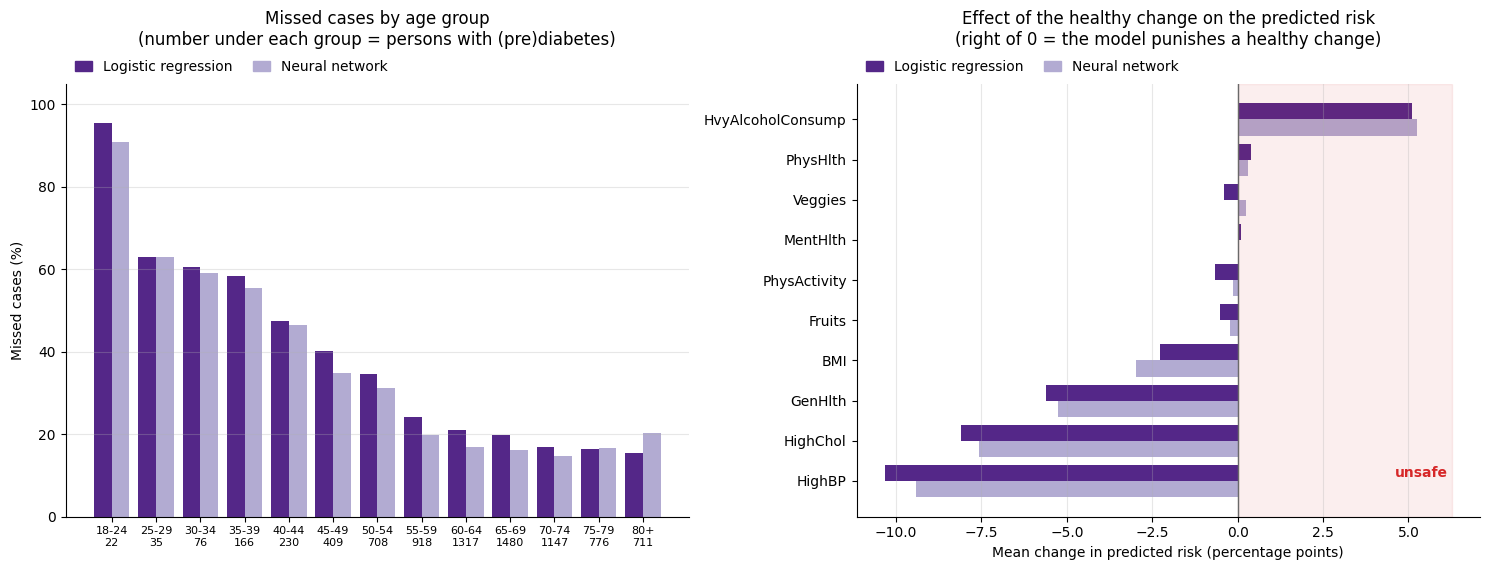

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
plot_missed_by_age(axes[0])
plot_advice_safety(axes[1])
plt.tight_layout()
xf.savefig(fig, "data_scientist", "where_models_fail")
plt.show()

### 10.2 Director of the patient organisation
Needs to know whether the tool can be trusted, without technical terms. We show what the models look at, how often
they are right per 100 people, and the logistic regression as a points table.

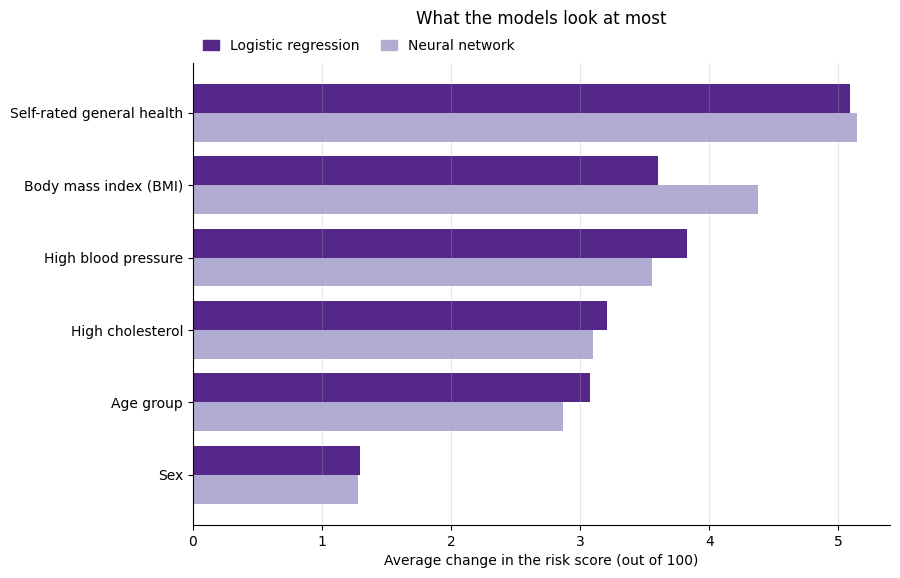

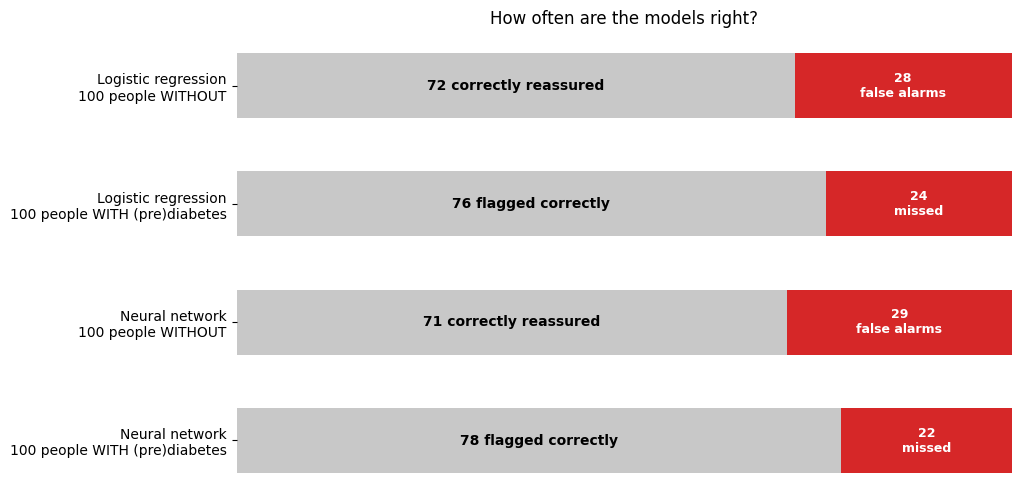

In [39]:
def plot_look_at(ax):
    top6 = glob.sort_values("Neural network", ascending=False).head(6)[::-1]
    top6.index = [xf.label(f) for f in top6.index]
    xf.plot_grouped_bars(ax, top6, title="What the models look at most",
                         xlabel="Average change in the risk score (out of 100)")

def plot_how_often_right(ax):
    rows, good, bad, texts = [], [], [], []
    for name in models:
        r = test_results.loc[name]
        caught, cleared = round(100 * r["Recall (sensitivity)"]), round(100 * r["Specificity"])
        rows += [f"{name}\n100 people WITHOUT", f"{name}\n100 people WITH (pre)diabetes"]
        good += [cleared, caught]; bad += [100 - cleared, 100 - caught]
        texts += [("correctly reassured", "false alarms"), ("flagged correctly", "missed")]
    rows, good, bad, texts = rows[::-1], good[::-1], bad[::-1], texts[::-1]   # barh draws bottom-up
    ax.barh(rows, good, color=COLORS["neutral"], height=0.55)
    ax.barh(rows, bad, left=good, color=COLORS["increase"], height=0.55)
    for i, (g, b, (tg, tb)) in enumerate(zip(good, bad, texts)):
        ax.text(g / 2, i, f"{g} {tg}", ha="center", va="center", color="black", fontweight="bold")
        ax.text(g + b / 2, i, f"{b}\n{tb}", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    ax.set(xlim=(0, 100), title="How often are the models right?", xticks=[])
    ax.grid(False)
    ax.spines[["left", "bottom"]].set_visible(False)

for fname, plot, size in [("look_at", plot_look_at, (9, 6)), ("how_often_right", plot_how_often_right, (10, 6))]:
    fig, ax = plt.subplots(figsize=size)
    plot(ax)
    xf.savefig(fig, "director", fname)
    plt.show()

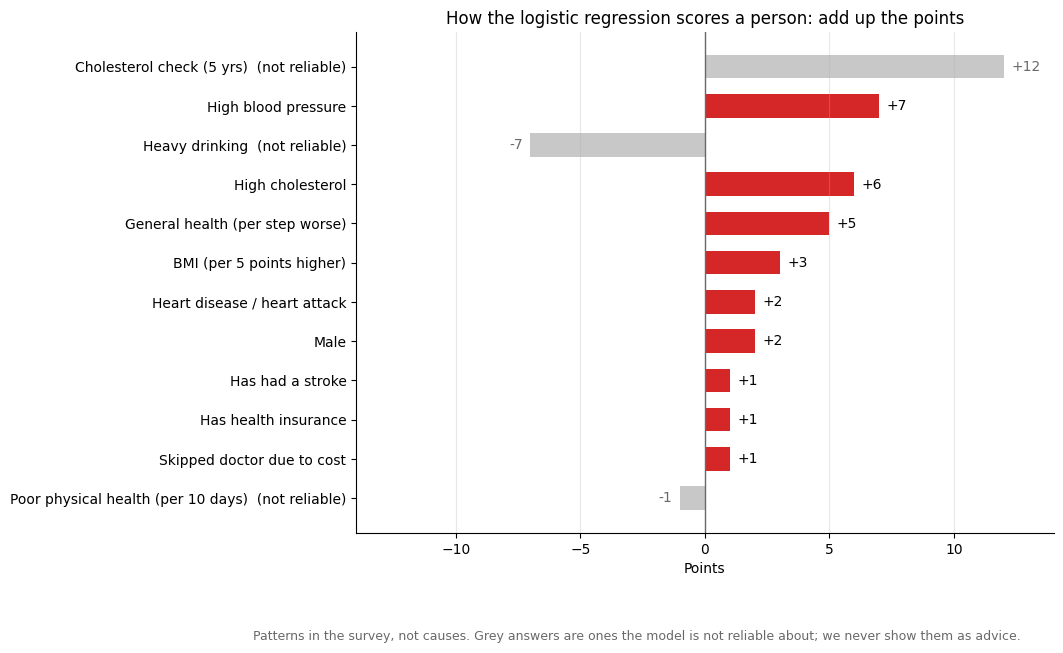

In [40]:
# Points table; features the model is not reliable about (unsafe advice, plus the cholesterol check, which
# almost everyone has had) are greyed out
UNRELIABLE = sorted(set(unsafe["Logistic regression"]) | {"CholCheck"})
fig, ax = plt.subplots(figsize=(9, 6.5))
xf.plot_points(ax, xf.lr_points(models["Logistic regression"]), unreliable=UNRELIABLE,
               title="How the logistic regression scores a person: add up the points")
fig.text(0.01, -0.04, "Patterns in the survey, not causes. Grey answers are ones the model is not reliable about; we never show them as advice.",
         ha="left", va="top", color=COLORS["text2"], fontsize=9)
xf.savefig(fig, "director", "points_table")
plt.show()

### 10.3 Patient
Needs to know why their score is high and what they can change. The design choices from Project 1 are kept:
- a score out of 100 compared with the average person;
- only habits under "things you can change"; blood pressure and cholesterol are "ever told you have" answers and go
  under health;
- sex, income and education summed into one background bar;
- the person's own answer in every label, so a red bar is not misread;
- no advice based on unsafe features, and a note saying so;
- at most 5 bars per panel, and a note that the score is not a diagnosis.

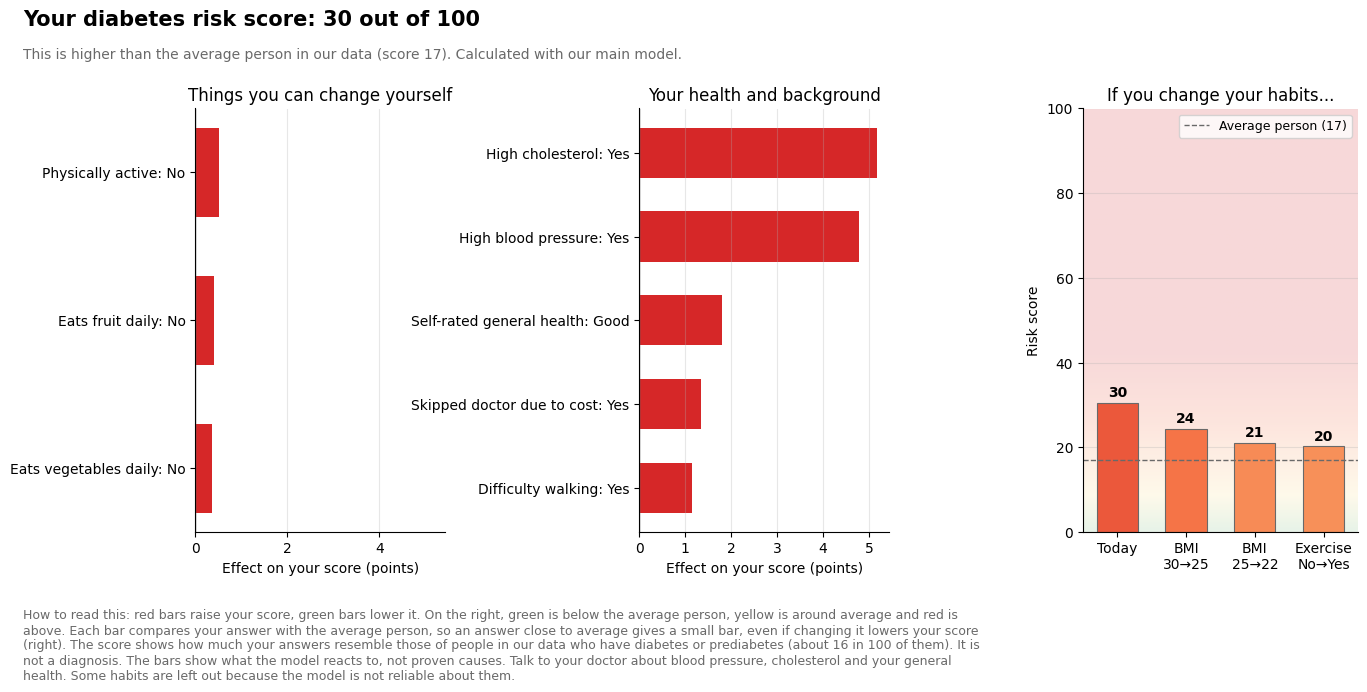

In [41]:
# Patient figure from the main model, no model name shown to the patient
name = "Logistic regression"
fig = xf.patient_figure(shap_local[name], x, cf[name], risk.loc[pid, name], average=shap_vals[name].base_values[pos],
                        prevalence=prevalence, hide=unsafe[name], subtitle="Calculated with our main model.")
xf.savefig(fig, "patient", f"patient_{pid}_logistic_regression")
plt.show()

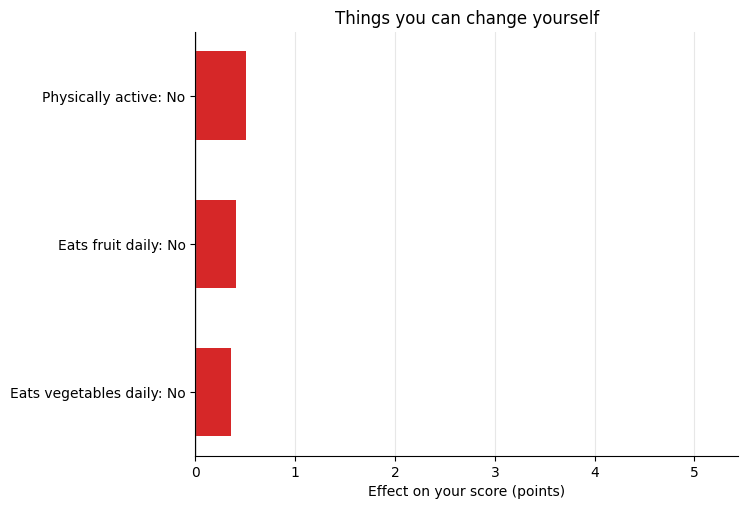

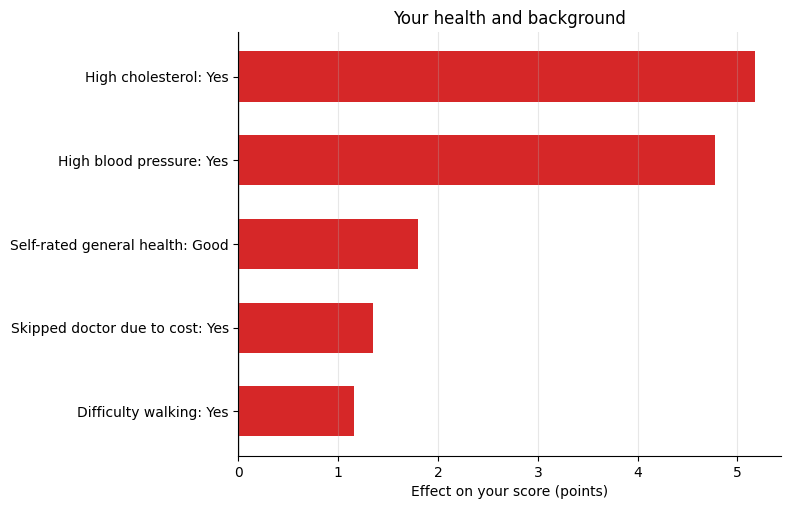

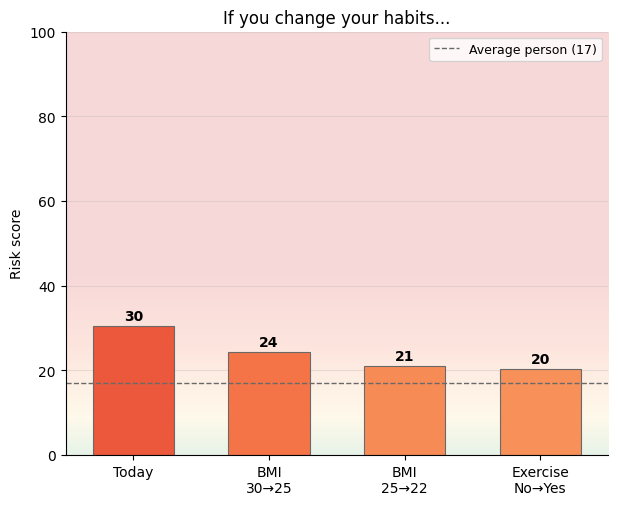

In [42]:
# The same figure split into one panel per slide: habits, health and background, and what the patient can change
fig_h, ax_h = plt.subplots(figsize=(7, 5.5))
fig_o, ax_o = plt.subplots(figsize=(7, 5.5))
xf.plot_patient_factors(ax_h, ax_o, shap_local[name], x, hide=unsafe[name])
xf.savefig(fig_h, "patient", f"patient_{pid}_habits")
xf.savefig(fig_o, "patient", f"patient_{pid}_health")
fig_c, ax_c = plt.subplots(figsize=(7, 5.5))
xf.plot_patient_changes(ax_c, cf[name], shap_vals[name].base_values[pos])
xf.savefig(fig_c, "patient", f"patient_{pid}_changes")
plt.show()

## 11. Recommendation
Generated from the results above; the written recommendation follows once the analysis is final.

In [43]:
rec = pd.DataFrame({name: {
    "Test AUC": test_results.loc[name, "AUC"],
    "Average precision": test_results.loc[name, "Average precision"],
    "Missed per 100 with (pre)diabetes": round(100 * (1 - test_results.loc[name, "Recall (sensitivity)"])),
    "False alarms per 100 without": round(100 * (1 - test_results.loc[name, "Specificity"])),
    "Prediabetes flagged per 100": round(100 * xf.recall_per_class(models[name], X_test, y3_test, THR[name])["Prediabetes"]),
    "Correct where the other is wrong": only_lr if name == "Logistic regression" else only_nn,
    "Healthy changes that raise the risk": ", ".join(unsafe[name]) or "none",
} for name in models})
print(f"McNemar p = {p_mcnemar:.1e}")
rec

McNemar p = 4.8e-05


,Logistic regression,Neural network
Test AUC,0.815,0.822
Average precision,0.428,0.455
Missed per 100 with (pre)diabetes,24,22
False alarms per 100 without,28,29
Prediabetes flagged per 100,65,68
Correct where the other is wrong,1863,1622
Healthy changes that raise the risk,"HvyAlcoholConsump, MentHlth, PhysHlth","Veggies, HvyAlcoholConsump, MentHlth, PhysHlth"


## 12. Technical audit: what has the network learned?
Two of the three audit methods from the description, on 4000 random test persons (real class shares, so prediabetes
is about 70 persons):
1. Latent space (week 9): the inputs and both hidden layers in 2-D with PCA, random projection, t-SNE and UMAP.
2. Concepts (week 11): probes, concept activation vectors (CAVs) and TCAV, for medical, lifestyle and social concepts
   (12.2) and for the sensitive attributes we removed in section 8.1 (12.3).

Two additions of our own, beyond the description: removing concepts inside the network to measure how much of the
score they carry (ablation, 12.4), and a deeper network to follow the concepts from layer to layer (12.5).

Representational alignment (CKA) is not used. For a network this small it would mainly confirm what the latent space
and the AUC already show: the network's output orders persons almost like the logistic regression's.

### 12.1 Latent space
Limits from the lecture: PCA and random projections are linear and can put separate groups on top of each other;
in t-SNE and UMAP the distances between clusters and the cluster sizes mean little, and both can make clusters out of
noise. Each picture is therefore checked with trustworthiness (how many of each person's 15 nearest neighbours are
also neighbours in the picture).

In [44]:
LATENT_N = 4000
X_lat = X_test.sample(LATENT_N, random_state=xf.SEED)
y3_lat = y3_test.loc[X_lat.index].to_numpy()
nn = models["Neural network"]
reps = xf.layer_representations(nn, X_lat)
SPACES = {"Inputs (21, standardised)": reps["Inputs"], "Hidden layer 1 (128)": reps["Hidden 1"],
          "Hidden layer 2 (64)": reps["Hidden 2"]}
METHODS = ["PCA", "Random projection", "t-SNE", "UMAP"]
emb, tw_rows = {}, {}
for space, Z in SPACES.items():
    for meth in METHODS:
        E, info = xf.embed(Z, meth)
        emb[(space, meth)] = E
        tw_rows[(space, meth)] = {"trustworthiness (k=15)": xf.trustworthiness(Z, E), **info}
for k in ["Hidden 1", "Hidden 2"]:
    print(f"{k}: dead units (never active) {int((reps[k].max(0) == 0).sum())} of {reps[k].shape[1]}")
pd.DataFrame(tw_rows).T.round(3)

Hidden 1: dead units (never active) 0 of 128
Hidden 2: dead units (never active) 4 of 64


trustworthiness (k=15)  \
Inputs (21, standardised) PCA                                 0.727   
                          Random projection                   0.671   
                          t-SNE                               0.985   
                          UMAP                                0.975   
Hidden layer 1 (128)      PCA                                 0.768   
                          Random projection                   0.632   
                          t-SNE                               0.972   
                          UMAP                                0.953   
Hidden layer 2 (64)       PCA                                 0.892   
                          Random projection                   0.634   
                          t-SNE                               0.979   
                          UMAP                                0.958   

                                             explained variance  
Inputs (21, standardised) PCA                             0.258  
                          Random projection                 NaN  
                          t-SNE                             NaN  
                          UMAP                              NaN  
Hidden layer 1 (128)      PCA                             0.286  
                          Random projection                 NaN  
                          t-SNE                             NaN  
                          UMAP                              NaN  
Hidden layer 2 (64)       PCA                             0.671  
                          Random projection                 NaN  
                          t-SNE                             NaN  
                          UMAP                              NaN

**Main figure.** One picture for the report and the data scientist: UMAP of the inputs next to UMAP of hidden layer 2,
coloured by class, with the two groups that the network sets apart outlined. It shows in one contrast what the network
does with the answers. PCA would be simpler, but it projects these two groups on top of the low-risk persons (a limit
from the lecture), so they cannot be seen. The other figures below are the checks behind it.

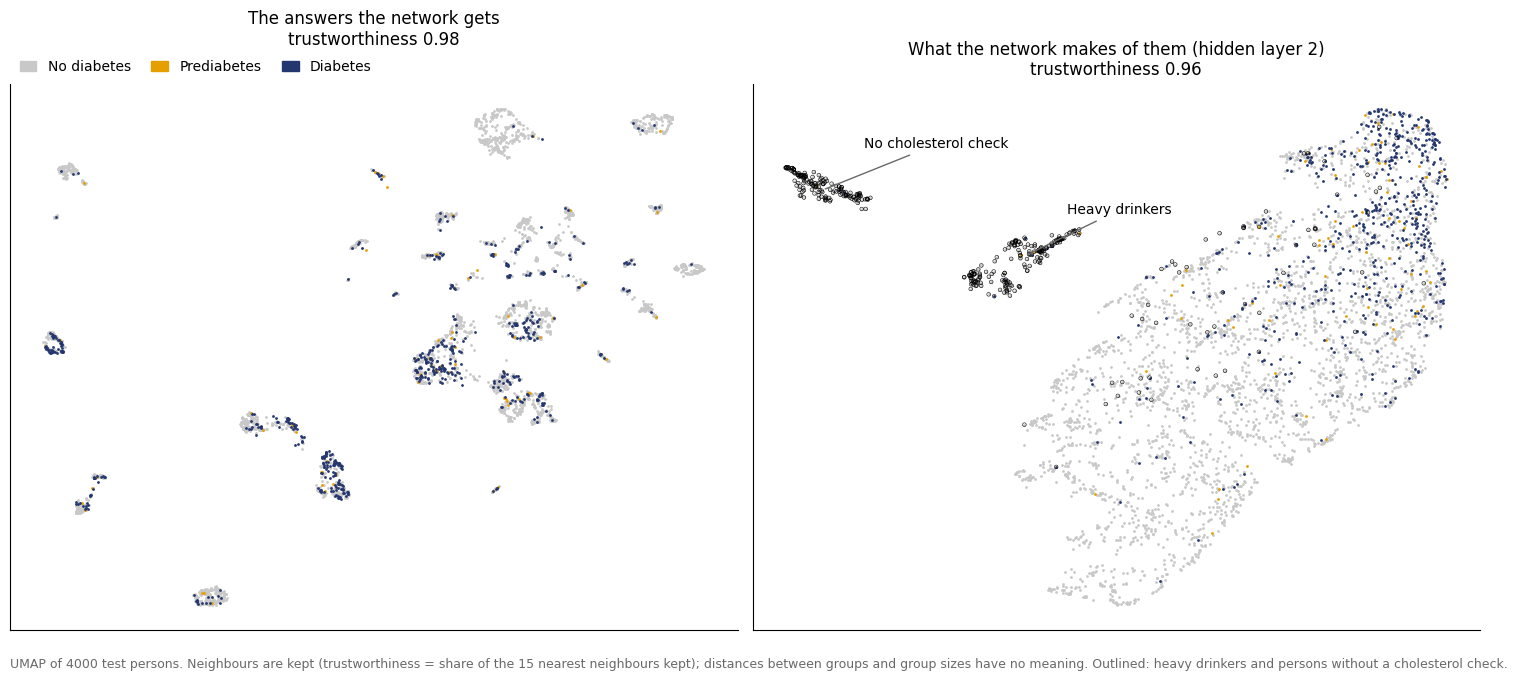

,persons,mean predicted risk (%),observed share with (pre)diabetes (%)
Heavy drinkers,233.0,7.2,10.7
No cholesterol check,168.0,2.7,3.0
Everyone else,3610.0,16.4,17.5


In [45]:
SET_APART = {"Heavy drinkers": (X_lat["HvyAlcoholConsump"] == 1).to_numpy(),
             "No cholesterol check": (X_lat["CholCheck"] == 0).to_numpy()}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
panels = [("Inputs (21, standardised)", "The answers the network gets"), ("Hidden layer 2 (64)", "What the network makes of them (hidden layer 2)")]
for ax, (space, title) in zip(axes, panels):
    E = emb[(space, "UMAP")]
    xf.plot_embedding(ax, E, classes=y3_lat, title=f"{title}\ntrustworthiness {tw_rows[(space, 'UMAP')]['trustworthiness (k=15)']:.2f}")
E = emb[("Hidden layer 2 (64)", "UMAP")]
for g, m in SET_APART.items():
    axes[1].scatter(E[m, 0], E[m, 1], s=7, facecolor="none", edgecolor="black", lw=0.4)
    axes[1].annotate(g,
                     (np.median(E[m, 0]), np.median(E[m, 1])), xytext=(30, 30), textcoords="offset points",
                     fontsize=10, arrowprops=dict(arrowstyle="-", color=COLORS["text2"]))
xf.micro_legend(axes[0], CLASS_COLORS, axes[0].get_title())
fig.text(0.01, -0.02, "UMAP of 4000 test persons. Neighbours are kept (trustworthiness = share of the 15 nearest neighbours kept); "
         "distances between groups and group sizes have no meaning. Outlined: heavy drinkers and persons without a cholesterol check.",
         ha="left", va="top", color=COLORS["text2"], fontsize=9)
plt.tight_layout()
xf.savefig(fig, "data_scientist", "latent_main")
plt.show()
p_lat_all = xf.proba_fn(nn)(X_lat) * 100
pd.DataFrame({g: {"persons": int(m.sum()), "mean predicted risk (%)": p_lat_all[m].mean(),
                  "observed share with (pre)diabetes (%)": 100 * (y3_lat[m] > 0).mean()} for g, m in SET_APART.items()}
             | {"Everyone else": {"persons": int((~(SET_APART["Heavy drinkers"] | SET_APART["No cholesterol check"])).sum()),
                                  "mean predicted risk (%)": p_lat_all[~(SET_APART["Heavy drinkers"] | SET_APART["No cholesterol check"])].mean(),
                                  "observed share with (pre)diabetes (%)": 100 * (y3_lat[~(SET_APART["Heavy drinkers"] | SET_APART["No cholesterol check"])] > 0).mean()}}).T.round(1)

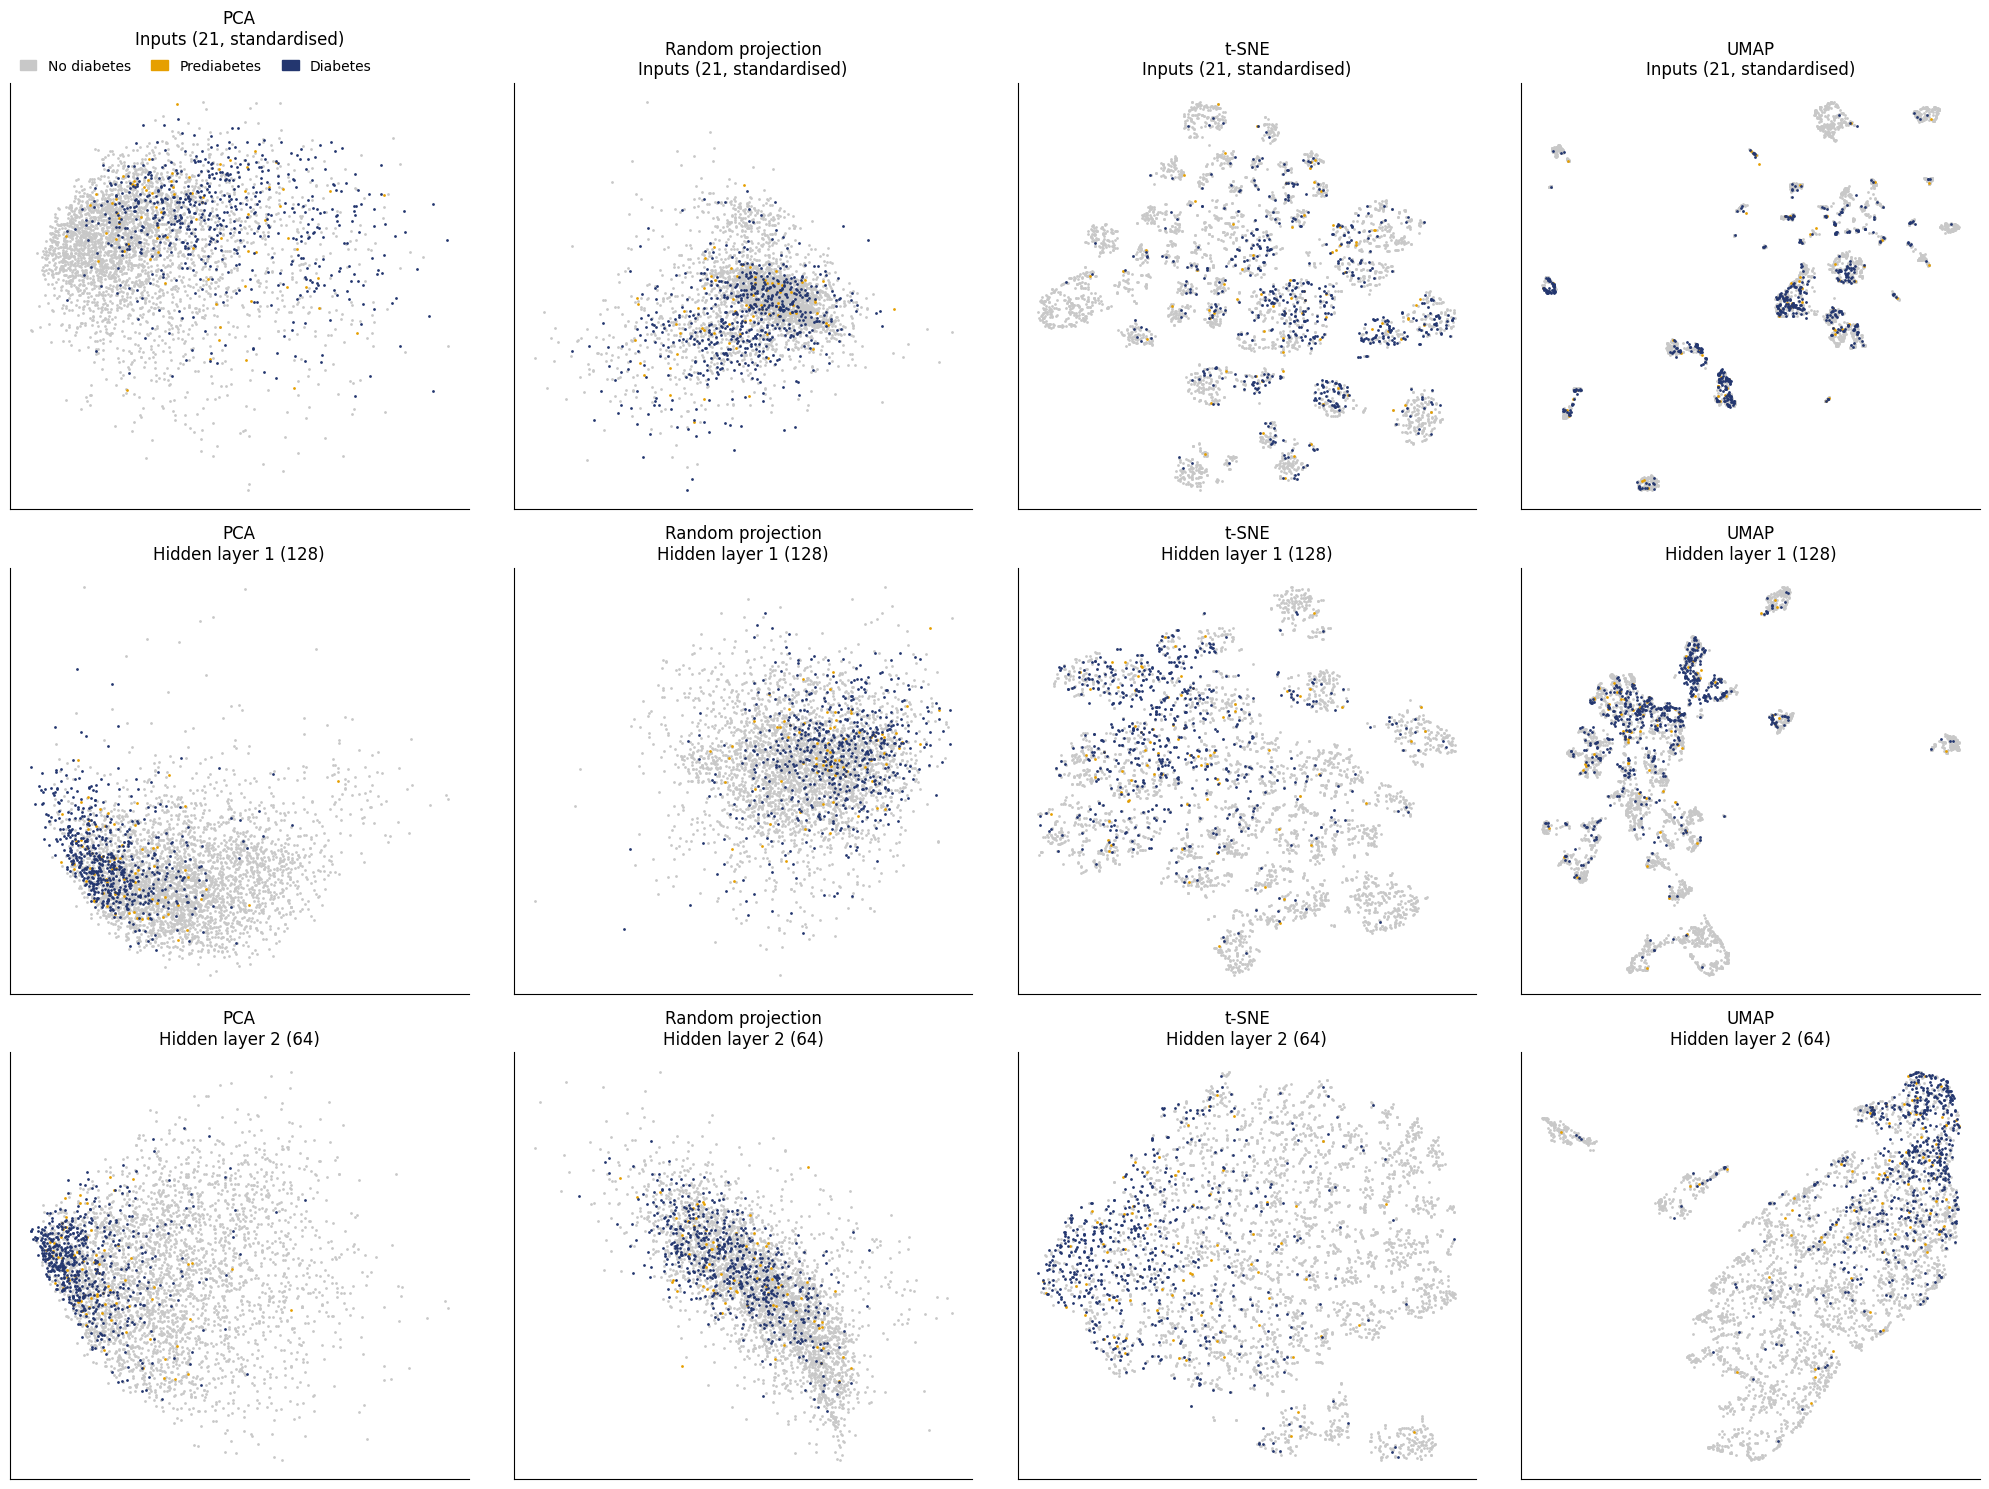

In [46]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
for r, space in enumerate(SPACES):
    for c, meth in enumerate(METHODS):
        xf.plot_embedding(axes[r, c], emb[(space, meth)], classes=y3_lat, title=f"{meth}\n{space}")
xf.micro_legend(axes[0, 0], CLASS_COLORS, axes[0, 0].get_title())
plt.tight_layout()
xf.savefig(fig, "data_scientist", "latent_by_class")
plt.show()

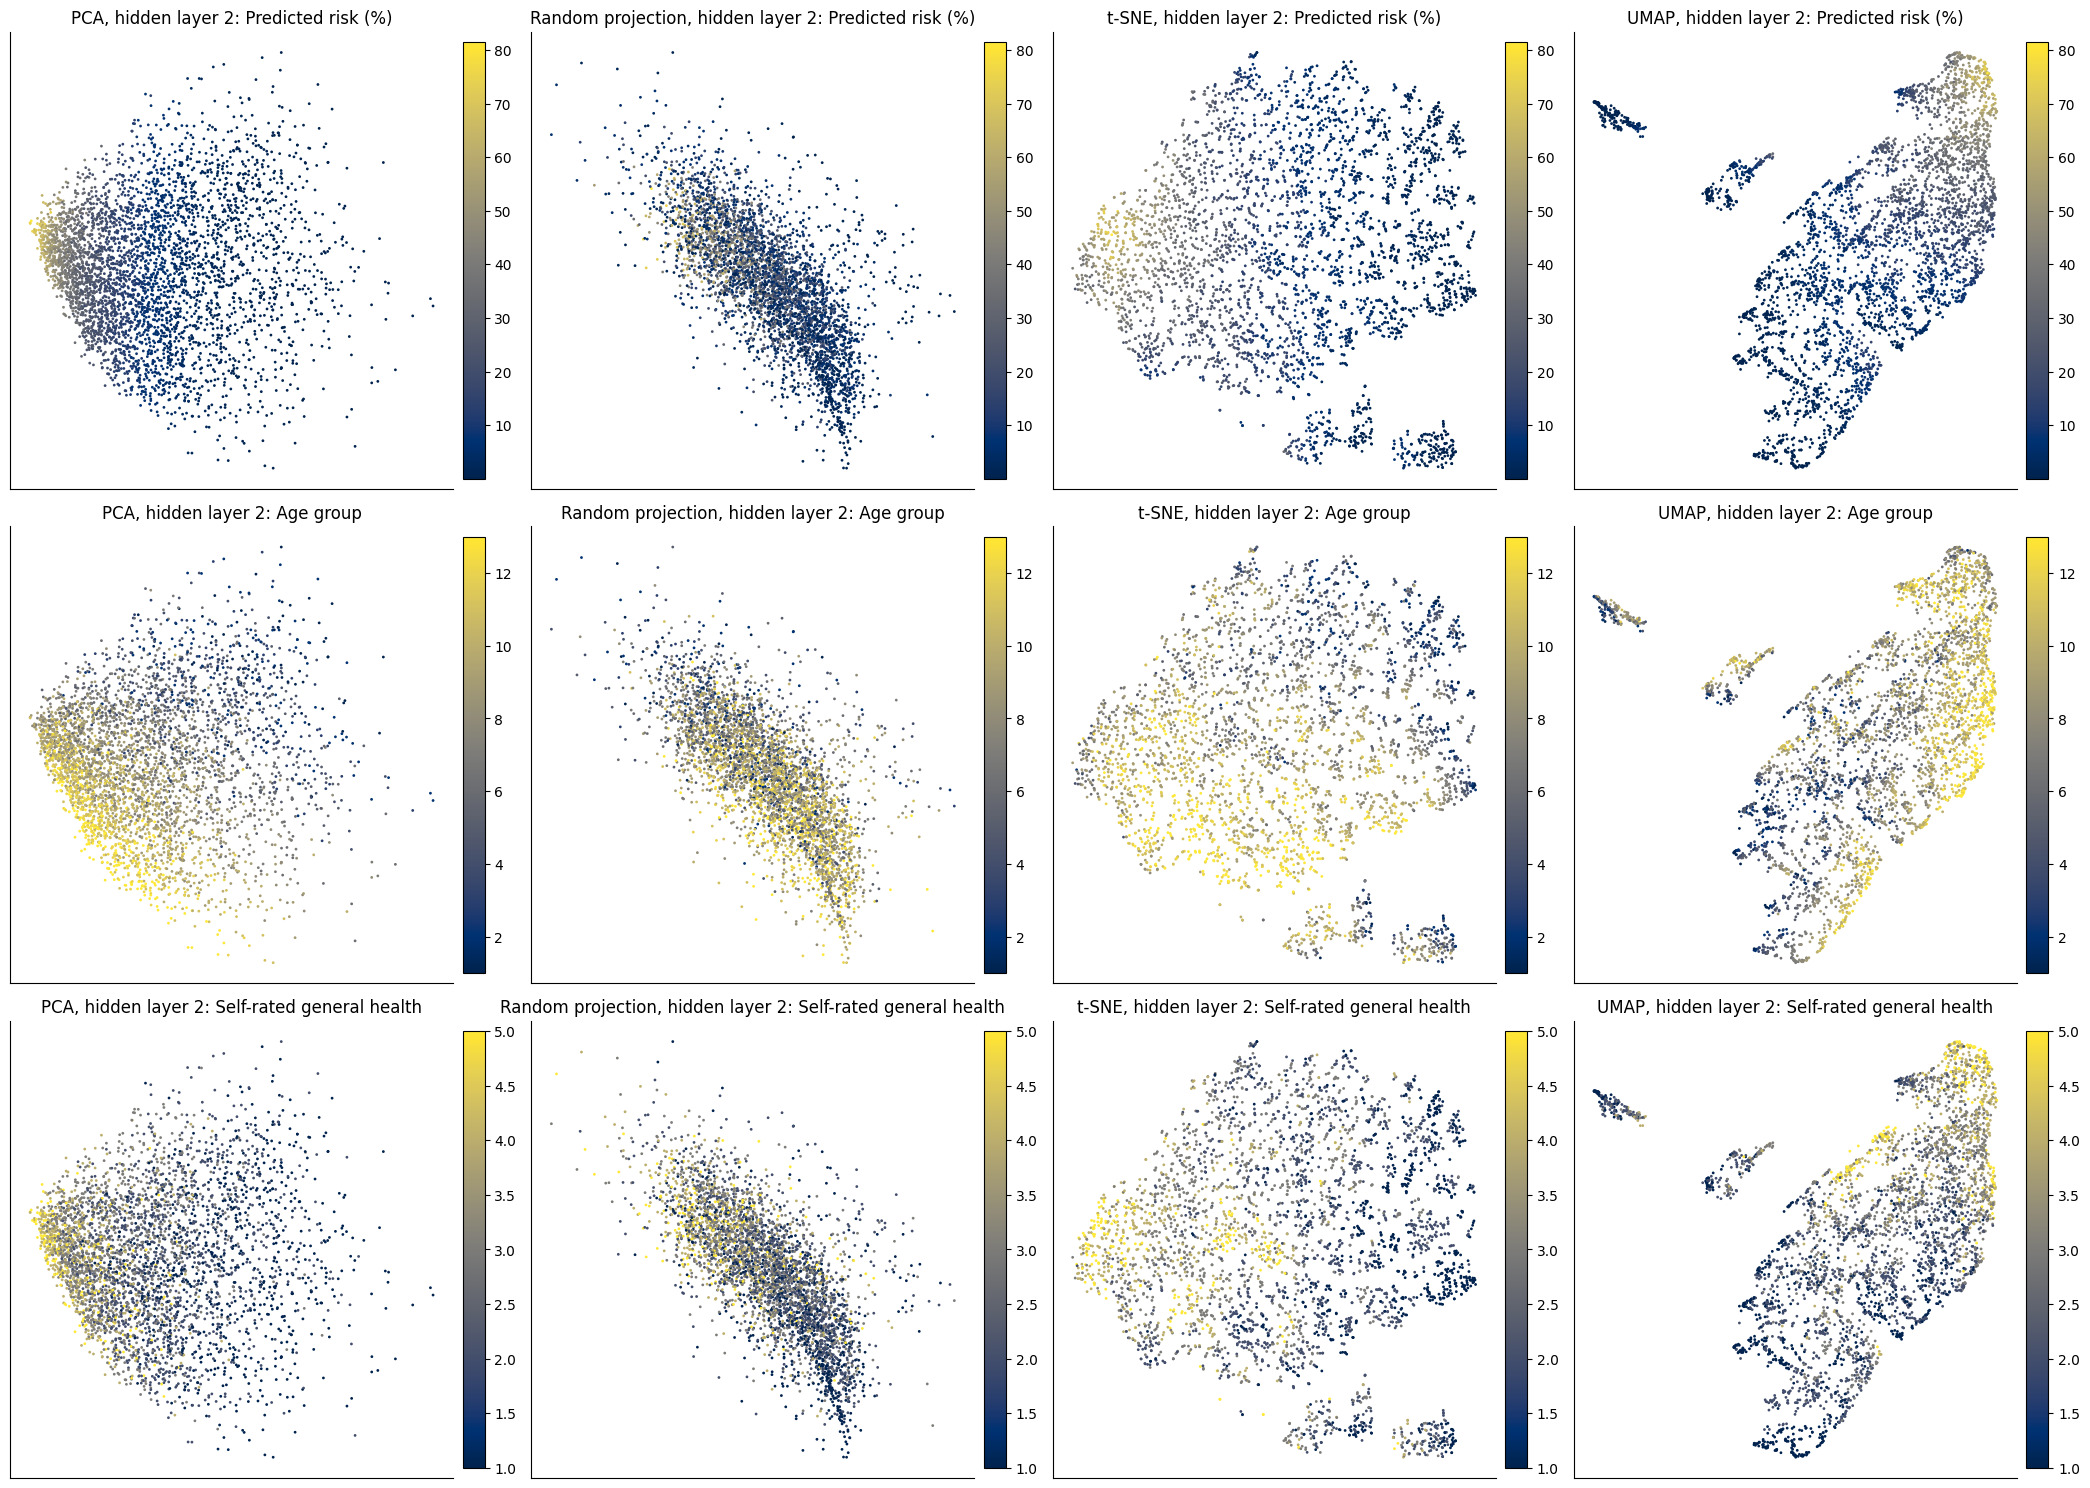

In [47]:
# The last hidden layer coloured by the network's predicted risk and by two inputs: what orders the space?
p_lat = xf.proba_fn(nn)(X_lat) * 100
colourings = {"Predicted risk (%)": p_lat, "Age group": X_lat["Age"].to_numpy(), "Self-rated general health": X_lat["GenHlth"].to_numpy()}
fig, axes = plt.subplots(3, 4, figsize=(21, 15))
for r, (what, vals) in enumerate(colourings.items()):
    for ax, meth in zip(axes[r], METHODS):
        xf.plot_embedding(ax, emb[("Hidden layer 2 (64)", meth)], values=vals, title=f"{meth}, hidden layer 2: {what}")
plt.tight_layout()
xf.savefig(fig, "data_scientist", "latent_by_risk")
plt.show()

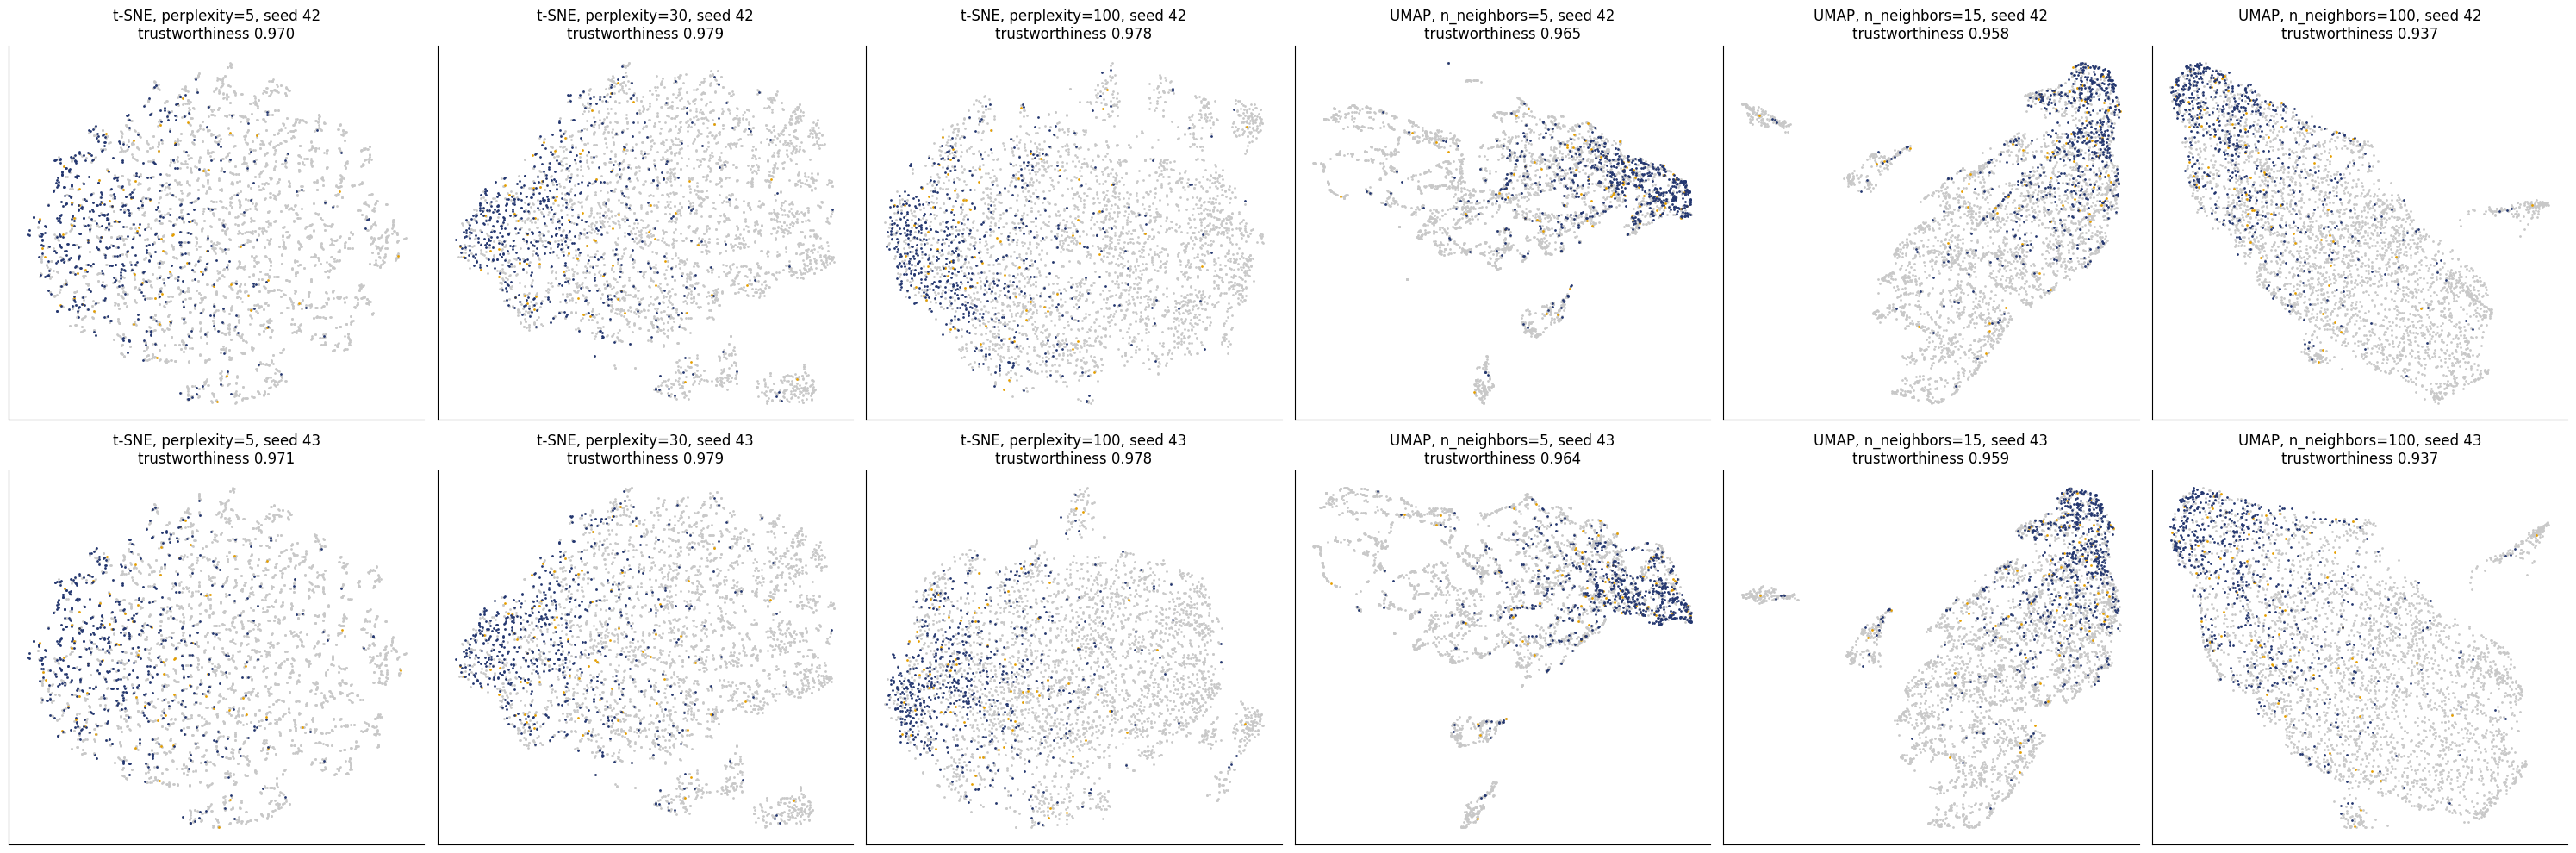

In [48]:
# Limits: t-SNE perplexity and UMAP n_neighbors change the picture, and so does the seed
Z = reps["Hidden 2"]
settings = [("t-SNE", dict(perplexity=p)) for p in (5, 30, 100)] + [("UMAP", dict(n_neighbors=k)) for k in (5, 15, 100)]
fig, axes = plt.subplots(2, 6, figsize=(30, 10))
for c, (meth, kw) in enumerate(settings):
    for r, seed in enumerate((xf.SEED, xf.SEED + 1)):
        E, _ = xf.embed(Z, meth, seed=seed, **kw)
        (k, v), = kw.items()
        xf.plot_embedding(axes[r, c], E, classes=y3_lat,
                          title=f"{meth}, {k}={v}, seed {seed}\ntrustworthiness {xf.trustworthiness(Z, E):.3f}")
plt.tight_layout()
xf.savefig(fig, "data_scientist", "latent_settings")
plt.show()

**What the latent space shows.**
- In the inputs, t-SNE and UMAP show many small clusters. They are combinations of the yes/no answers (sex, blood
  pressure, cholesterol, heart disease, ...; checked by clustering the UMAP picture and comparing the groups), not
  groups of patients: the share with (pre)diabetes differs between them (1-37 %), but no cluster separates the classes.
- In the hidden layers the clusters dissolve into one continuum ordered by predicted risk, with older age and worse
  general health on the same side. PCA keeps 67 % of the variance of layer 2 in two axes (26 % for the inputs), so
  the last layer is close to one-dimensional: the network has mainly learned one risk direction. This fits the small
  AUC gain over the logistic regression (0.822 vs 0.815).
- Two groups are placed apart from the continuum in layer 2 (main figure): most heavy drinkers (all heavy drinkers in
  the sample: predicted 7 %, observed 11 %) and persons without a cholesterol check (predicted 3 %, observed 3 %). Heavy
  drinkers with other risk factors stay in the main continuum. These are the two features we already flagged as
  unreliable (7.6, 10.2); the network has given them their own low-risk region.
- Prediabetes does not form its own region. It lies spread between no diabetes and diabetes, which fits the merged
  target and its lower recall (65-68 per 100).
- t-SNE and UMAP keep 95-99 % of the nearest neighbours, random projections only 63-67 %. The risk ordering survives every
  perplexity, n_neighbors and seed. Small separate groups appear in most settings, but their number and position change
  (at n_neighbors = 100 only one remains), so we identified them by clustering the default UMAP picture and checking who
  is in them, rather than by their shape. Distances between groups are not interpreted.

### 12.2 Concepts: probes, CAVs and TCAV
A concept is a group of persons defined in words. None of the concepts below is a single input; they combine inputs
into groups a doctor or the patient organisation would talk about. For each concept we ask three questions:
- **Is it encoded?** A probe (logistic regression) predicts the concept from a hidden layer, on equal numbers of
  persons with and without the concept. Its held-out accuracy is compared with the same probe trained on shuffled
  labels (random-label baseline, about 0.5).
- **Does the network use it?** TCAV (Kim et al. 2018): the CAV is the direction in hidden layer 1 from persons without
  the concept towards persons with it. The TCAV score is the share of test persons with (pre)diabetes whose predicted
  log-odds rise when their activations move a little in that direction. Each CAV is built 20 times on different
  persons and compared with 20 CAVs of random "concepts" (random vs random persons); a t-test says whether the score
  differs from that null range. Kim et al. use random examples as counterexamples; for groups of persons this mixes
  concept members into them (6 % of random persons are heavy drinkers) and made the heavy-drinker CAVs unstable
  (sd 0.26 vs 0.06), so we use persons without the concept.
- **Does it depend on how the CAV is built?** The week 11 exercise gives five ways: mean difference, logistic
  regression, linear SVM (Kim et al.), PCA and contrastive PCA. We use logistic regression and check the other four.

As a sanity check, the table also gives the difference in mean predicted risk between the concept group and everyone
else.

In [49]:
CONCEPTS = {
    "Metabolic profile":    ("high blood pressure + high cholesterol + BMI 30 or more",
                             lambda X: (X.HighBP == 1) & (X.HighChol == 1) & (X.BMI >= 30)),
    "Poor general health":  ("self-rated health fair or poor", lambda X: X.GenHlth >= 4),
    "Cardiovascular history": ("has had a stroke or heart disease", lambda X: (X.Stroke == 1) | (X.HeartDiseaseorAttack == 1)),
    "Healthy lifestyle":    ("active + fruit + vegetables daily + never smoked", lambda X: (X.PhysActivity == 1) & (X.Fruits == 1) & (X.Veggies == 1) & (X.Smoker == 0)),
    "Heavy drinker":        ("heavy drinking", lambda X: X.HvyAlcoholConsump == 1),
    "Young adult":          ("aged 18-34", lambda X: X.Age <= 3),
    "Low socio-economic status": ("income below $20k and no college", lambda X: (X.Income <= 3) & (X.Education <= 4)),
    "Barriers to care":     ("no health insurance or skipped the doctor due to cost", lambda X: (X.AnyHealthcare == 0) | (X.NoDocbcCost == 1)),
}
pool = X_train.sample(20000, random_state=xf.SEED)
target = X_test[y_test == 1].sample(2000, random_state=xf.SEED)
rows, tcav_runs = {}, {}
for cname, (definition, rule) in CONCEPTS.items():
    c_lat = rule(X_lat).to_numpy().astype(int)
    r = xf.tcav(nn, X_train[rule(X_train)], pool[~rule(pool)], target, layer=0, n_runs=20, n=300)
    in_c = rule(X_test).to_numpy()
    p_test = xf.proba_fn(nn)(X_test)
    tcav_runs[cname] = r
    rows[cname] = {"definition": definition, "share of persons": rule(X_train).mean(),
                   "risk difference vs others (pp)": 100 * (p_test[in_c].mean() - p_test[~in_c].mean()),
                   **{f"probe accuracy, {k}": xf.probe_report(reps[k], c_lat)["probe accuracy"] for k in ["Hidden 1", "Hidden 2"]},
                   "random-label accuracy": xf.probe_report(reps["Hidden 1"], c_lat)["random-label accuracy"],
                   "CAV accuracy": r["CAV accuracy"], "TCAV score": r["TCAV score"], "TCAV sd": r["TCAV sd"],
                   "random score": r["random score"], "random sd": r["random sd"], "p-value": r["p-value"]}
concepts = pd.DataFrame(rows).T
concepts.drop(columns="definition").astype(float).round(3)

,share of persons,risk difference vs others (pp),"probe accuracy, Hidden 1","probe accuracy, Hidden 2",random-label accuracy,CAV accuracy,TCAV score,TCAV sd,random score,random sd,p-value
Metabolic profile,0.119,30.512,0.950,0.916,0.495,0.952,1.000,0.000,0.483,0.298,0.000
Poor general health,0.172,22.809,0.989,0.902,0.494,0.976,1.000,0.000,0.531,0.314,0.000
Cardiovascular history,0.119,18.792,1.000,0.968,0.498,1.000,1.000,0.000,0.505,0.367,0.000
Healthy lifestyle,0.279,-7.315,0.993,0.923,0.511,0.991,0.718,0.111,0.432,0.306,0.000
Heavy drinker,0.056,-8.918,1.000,1.000,0.466,1.000,0.200,0.060,0.588,0.336,0.000
Young adult,0.096,-13.339,0.952,0.922,0.510,0.972,0.185,0.058,0.451,0.306,0.001
Low socio-economic status,0.087,13.253,0.927,0.850,0.502,0.941,0.980,0.021,0.426,0.309,0.000
Barriers to care,0.115,2.513,1.000,0.959,0.500,1.000,0.950,0.025,0.484,0.383,0.000


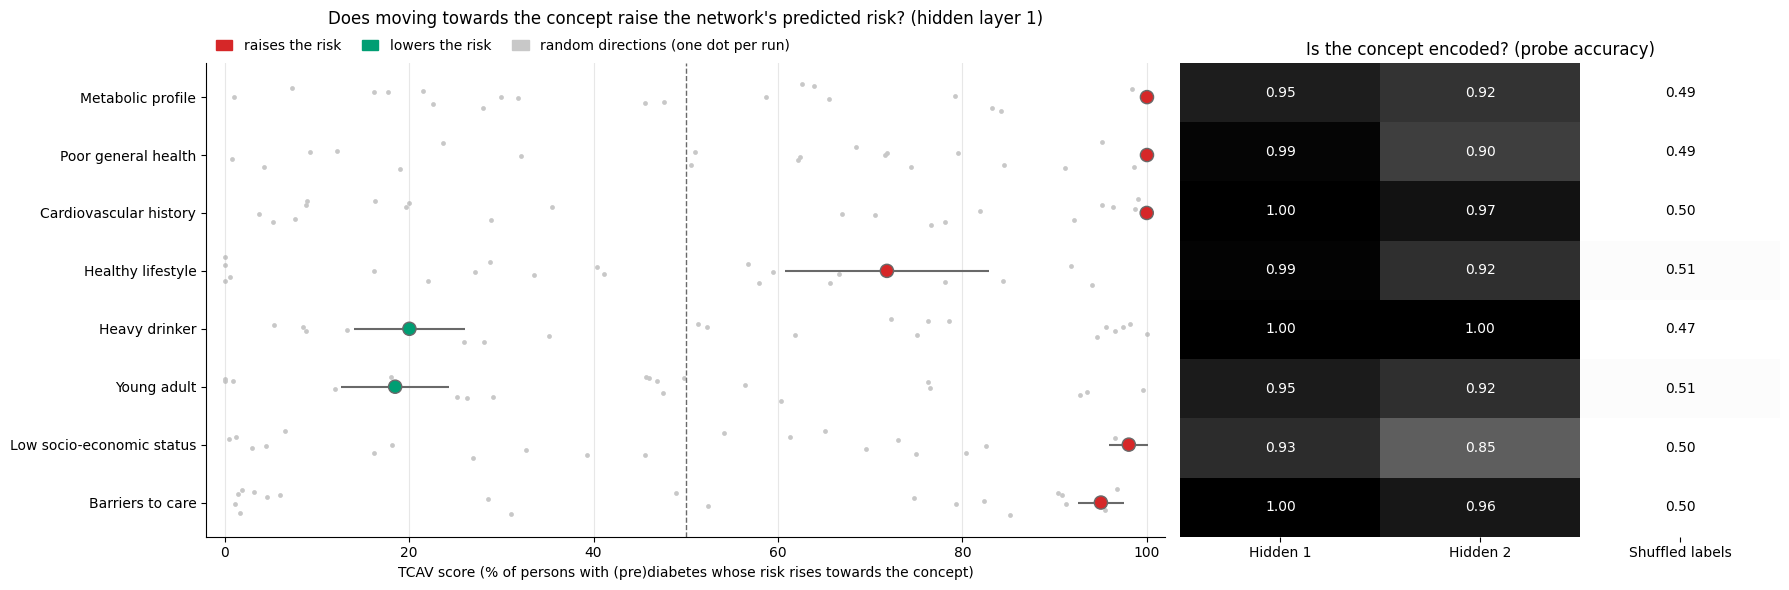

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.6, 1]})
xf.plot_tcav(axes[0], concepts.astype({c: float for c in concepts.columns if c != "definition"}), tcav_runs,
             title="Does moving towards the concept raise the network's predicted risk? (hidden layer 1)")
xf.micro_legend(axes[0], {"raises the risk": COLORS["increase"], "lowers the risk": COLORS["decrease"],
                          "random directions (one dot per run)": COLORS["neutral"]}, axes[0].get_title())
probe_tab = concepts[["probe accuracy, Hidden 1", "probe accuracy, Hidden 2", "random-label accuracy"]].astype(float)
probe_tab.columns = ["Hidden 1", "Hidden 2", "Shuffled labels"]
xf.plot_heatmap(axes[1], probe_tab, vmin=0.5, vmax=1.0, title="Is the concept encoded? (probe accuracy)")
axes[1].set_yticks([])
plt.tight_layout()
xf.savefig(fig, "data_scientist", "concepts_tcav")
plt.show()

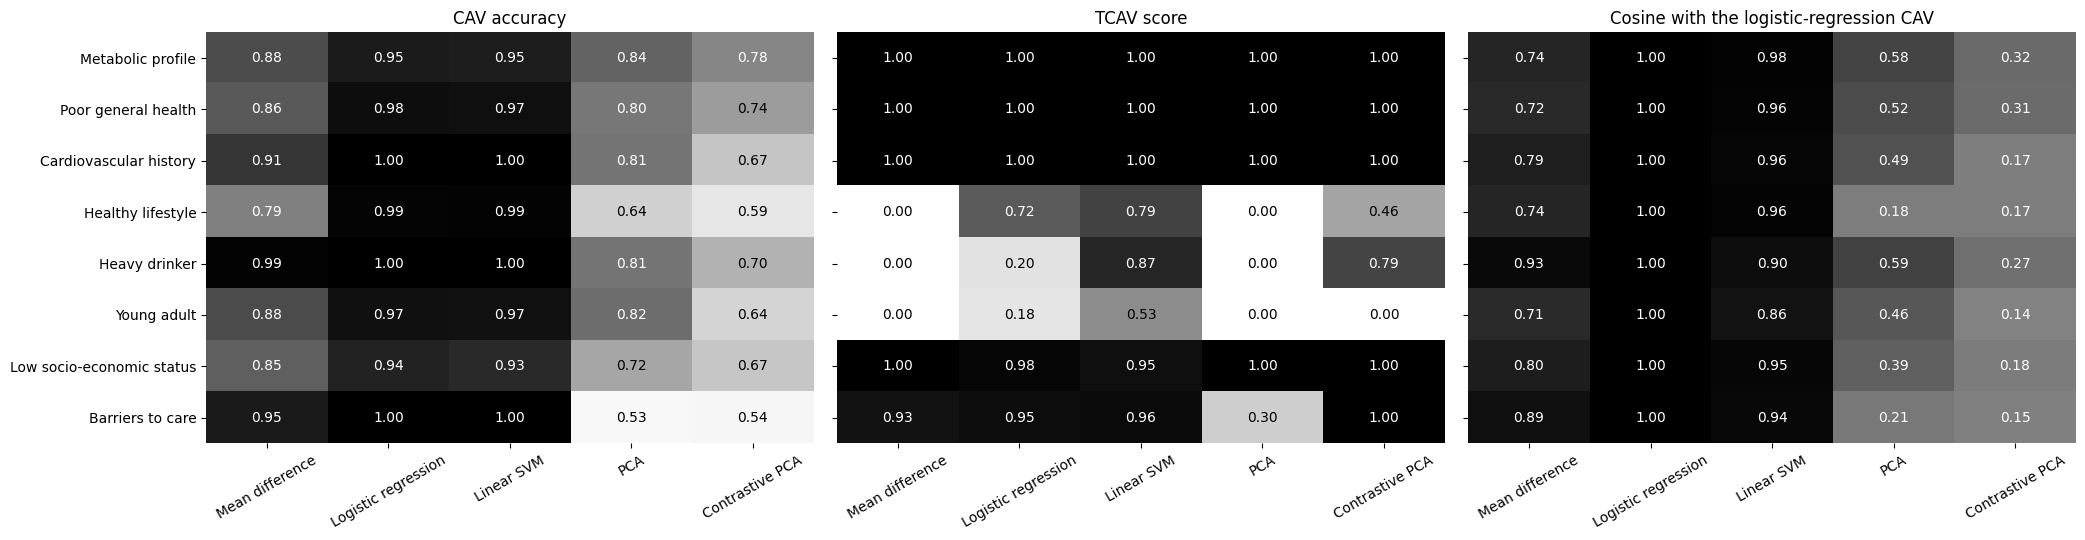

CAV accuracy                                 \
                          Mean difference Logistic regression Linear SVM   
Metabolic profile                    0.88                0.95       0.95   
Poor general health                  0.86                0.98       0.97   
Cardiovascular history               0.91                1.00       1.00   
Healthy lifestyle                    0.79                0.99       0.99   
Heavy drinker                        0.99                1.00       1.00   
Young adult                          0.88                0.97       0.97   
Low socio-economic status            0.85                0.94       0.93   
Barriers to care                     0.95                1.00       1.00   

                                                     TCAV score  \
                            PCA Contrastive PCA Mean difference   
Metabolic profile          0.84            0.78            1.00   
Poor general health        0.80            0.74            1.00   
Cardiovascular history     0.81            0.67            1.00   
Healthy lifestyle          0.64            0.59            0.00   
Heavy drinker              0.81            0.70            0.00   
Young adult                0.82            0.64            0.00   
Low socio-economic status  0.72            0.67            1.00   
Barriers to care           0.53            0.54            0.93   

                                                                               \
                          Logistic regression Linear SVM  PCA Contrastive PCA   
Metabolic profile                        1.00       1.00  1.0            1.00   
Poor general health                      1.00       1.00  1.0            1.00   
Cardiovascular history                   1.00       1.00  1.0            1.00   
Healthy lifestyle                        0.72       0.79  0.0            0.46   
Heavy drinker                            0.20       0.87  0.0            0.79   
Young adult                              0.18       0.53  0.0            0.00   
Low socio-economic status                0.98       0.95  1.0            1.00   
Barriers to care                         0.95       0.96  0.3            1.00   

                          significant (p < 0.05)                      \
                                 Mean difference Logistic regression   
Metabolic profile                            1.0                 1.0   
Poor general health                          1.0                 1.0   
Cardiovascular history                       1.0                 1.0   
Healthy lifestyle                            1.0                 1.0   
Heavy drinker                                1.0                 1.0   
Young adult                                  1.0                 1.0   
Low socio-economic status                    1.0                 1.0   
Barriers to care                             1.0                 1.0   

                                                           \
                          Linear SVM  PCA Contrastive PCA   
Metabolic profile                1.0  1.0             1.0   
Poor general health              1.0  1.0             1.0   
Cardiovascular history           1.0  1.0             1.0   
Healthy lifestyle                1.0  1.0             0.0   
Heavy drinker                    1.0  1.0             0.0   
Young adult                      0.0  1.0             1.0   
Low socio-economic status        1.0  1.0             1.0   
Barriers to care                 1.0  0.0             1.0   

                          Cosine with the logistic-regression CAV  \
                                                  Mean difference   
Metabolic profile                                            0.74   
Poor general health                                          0.72   
Cardiovascular history                                       0.79   
Healthy lifestyle                                            0.74   
Heavy drinker                           

In [51]:
# Does the result depend on how the CAV is built? The five methods from the week 11 exercise, same persons and runs
method_runs = {m: {cname: (tcav_runs[cname] if m == "Logistic regression" else
                           xf.tcav(nn, X_train[rule(X_train)], pool[~rule(pool)], target, layer=0, n_runs=20, n=300, method=m))
                   for cname, (_, rule) in CONCEPTS.items()} for m in xf.CAV_METHODS}
unit = lambda V: V.mean(0) / np.linalg.norm(V.mean(0))
cav_cmp = {k: pd.DataFrame({m: {c: f(m, c) for c in CONCEPTS} for m in xf.CAV_METHODS}) for k, f in {
    "CAV accuracy": lambda m, c: method_runs[m][c]["CAV accuracy"],
    "TCAV score": lambda m, c: method_runs[m][c]["TCAV score"],
    "significant (p < 0.05)": lambda m, c: float(method_runs[m][c]["p-value"] < 0.05),
    "Cosine with the logistic-regression CAV": lambda m, c: float(unit(method_runs[m][c]["cavs"]) @ unit(method_runs["Logistic regression"][c]["cavs"])),
}.items()}
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5), sharey=True)
for ax, k, (lo, hi) in zip(axes, ["CAV accuracy", "TCAV score", "Cosine with the logistic-regression CAV"], [(0.5, 1), (0, 1), (-1, 1)]):
    xf.plot_heatmap(ax, cav_cmp[k], vmin=lo, vmax=hi, title=k)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
xf.savefig(fig, "data_scientist", "cav_methods")
plt.show()
pd.concat(cav_cmp, axis=1).round(2)

In [52]:
# Cross-checks at the input level: give the target persons the concept directly and measure the change in risk
f_nn = xf.proba_fn(nn)
healthy = target.assign(PhysActivity=1, Fruits=1, Veggies=1, Smoker=0)
d_healthy = f_nn(healthy) - f_nn(target)
d_heavy = f_nn(target.assign(HvyAlcoholConsump=1)) - f_nn(target)
pd.DataFrame({"Healthy lifestyle (active, fruit, vegetables, non-smoker)": {"TCAV score": tcav_runs["Healthy lifestyle"]["TCAV score"],
                  "mean change in risk (pp)": 100 * d_healthy.mean(), "share whose risk rises": (d_healthy > 0).mean()},
              "Heavy drinker": {"TCAV score": tcav_runs["Heavy drinker"]["TCAV score"],
                  "mean change in risk (pp)": 100 * d_heavy.mean(), "share whose risk rises": (d_heavy > 0).mean()}}).T.round(3)

,TCAV score,mean change in risk (pp),share whose risk rises
"Healthy lifestyle (active, fruit, vegetables, non-smoker)",0.718,-0.671,0.300
Heavy drinker,0.200,-11.203,0.002


#### Concepts nobody defined: NMF
The eight concepts above are our choice, so they can only find what we looked for. NMF (week 11, exercise 3) finds
concepts without labels. Hidden layer 1 uses ReLU, so the activations of the 20,000 training persons in `pool` are
non-negative and can be split into k concept directions (W) and how strongly each person expresses each concept (U).
A concept is described by the 5 % of persons who express it most and the answers that set them apart. Checks:
- **How many concepts?** The share of the layer that k = 4, 8 and 16 concepts cannot reconstruct, and whether each
  concept is found again from five random starts (cosine with its best match, 1 = the same direction).
- **Is it one of ours?** How well a person's NMF score picks out the members of our own concepts (AUC; 0.5 = unrelated,
  below 0.5 = the opposite group).
- **Does the network use it?** TCAV as above, with the top 5 % as concept persons and the rest as counterexamples.

In [53]:
H_pool = xf.hidden_activations(nn, pool, layer=0)
nmf_k = {}
for k in (4, 8, 16):
    _, W_k, err = xf.nmf_concepts(H_pool, k)
    stab = xf.nmf_stability(H_pool, W_k)
    nmf_k[k] = {"share of the layer not reconstructed": err, "mean stability (cosine)": stab.mean(),
                "least stable concept (cosine)": stab.min()}
pd.DataFrame(nmf_k).T.rename_axis("k concepts").round(3)

,share of the layer not reconstructed,mean stability (cosine),least stable concept (cosine)
k concepts,,,
4,0.655,1.000,1.000
8,0.582,0.858,0.286
16,0.488,0.984,0.820


In [54]:
NMF_K = 8
U_nmf, W_nmf, _ = xf.nmf_concepts(H_pool, NMF_K)
stab_nmf = xf.nmf_stability(H_pool, W_nmf)
# Names given after reading the profiles. They are keyed by the answer that sets the group apart most, so if the
# solution changes, a concept falls back to "NMF j" instead of getting a wrong name.
NMF_NAMES = {("GenHlth", -1): "Good health, no high BP or cholesterol", ("PhysHlth", 1): "Poor physical and mental health",
             ("Age", 1): "Older, lean women", ("Fruits", -1): "Smoking, no fruit, cost barriers",
             ("CholCheck", -1): "No cholesterol check", ("Age", -1): "Young men", ("BMI", 1): "High BMI",
             ("AnyHealthcare", -1): "No health insurance"}
p_pool = xf.proba_fn(nn)(pool)
y_pool = y_train.loc[pool.index].to_numpy()
nmf_rows, nmf_runs, nmf_scores = {}, {}, {}
for j in range(NMF_K):
    top = U_nmf[:, j] >= np.quantile(U_nmf[:, j], 0.95)
    name = NMF_NAMES.get(xf.leading_feature(pool, top), f"NMF {j + 1}")
    name = name if name not in nmf_rows else f"{name} ({j + 1})"
    r = xf.tcav(nn, pool[top], pool[~top], target, layer=0, n_runs=20, n=300)
    nmf_runs[name], nmf_scores[name] = r, U_nmf[:, j]
    nmf_rows[name] = {"who (top 5 %)": xf.concept_profile(pool, top), "stability (cosine)": stab_nmf[j],
                      "mean predicted risk (%)": 100 * p_pool[top].mean(), "observed (pre)diabetes (%)": 100 * y_pool[top].mean(),
                      "TCAV score": r["TCAV score"], "TCAV sd": r["TCAV sd"], "random score": r["random score"],
                      "p-value": r["p-value"]}
nmf_tab = pd.DataFrame(nmf_rows).T.sort_values("mean predicted risk (%)", ascending=False)
num = nmf_tab.columns.drop("who (top 5 %)")
nmf_tab[num] = nmf_tab[num].astype(float)
with pd.option_context("display.max_colwidth", None):
    display(nmf_tab.round(2))

,who (top 5 %),stability (cosine),mean predicted risk (%),observed (pre)diabetes (%),TCAV score,TCAV sd,random score,p-value
Poor physical and mental health,Days of poor physical health 22.1 (all 4.3); Difficulty walking 92 % (all 17 %); Self-rated general health Fair (all Very good),0.90,49.95,52.80,1.00,0.00,0.45,0.00
High BMI,Body mass index (BMI) 44.6 (all 28.4); High blood pressure 59 % (all 43 %); Physically active 63 % (all 76 %),0.29,26.36,26.30,0.98,0.02,0.40,0.00
No health insurance,Has health insurance 8 % (all 95 %); Skipped doctor due to cost 34 % (all 9 %); Age group 45-49 (all 55-59),1.00,9.79,10.10,0.43,0.14,0.41,0.76
"Smoking, no fruit, cost barriers",Eats fruit daily 17 % (all 63 %); Has smoked (100+ cigarettes) 91 % (all 45 %); Skipped doctor due to cost 32 % (all 9 %),0.93,8.70,9.20,0.01,0.01,0.63,0.00
"Older, lean women",Age group 75-79 (all 55-59); Body mass index (BMI) 23.0 (all 28.4); Men 4 % (all 44 %),0.94,7.67,8.99,0.02,0.02,0.41,0.00
No cholesterol check,Cholesterol check (5 yrs) 24 % (all 96 %); Heavy drinking 26 % (all 6 %); Age group 45-49 (all 55-59),0.99,2.82,3.20,0.01,0.02,0.48,0.00
Young men,Age group 30-34 (all 55-59); Men 100 % (all 44 %); High blood pressure 6 % (all 43 %),0.98,1.83,1.30,0.04,0.04,0.33,0.00
"Good health, no high BP or cholesterol",Self-rated general health Excellent (all Very good); Men 0 % (all 44 %); High cholesterol 0 % (all 43 %),0.85,0.56,0.30,0.00,0.00,0.55,0.00


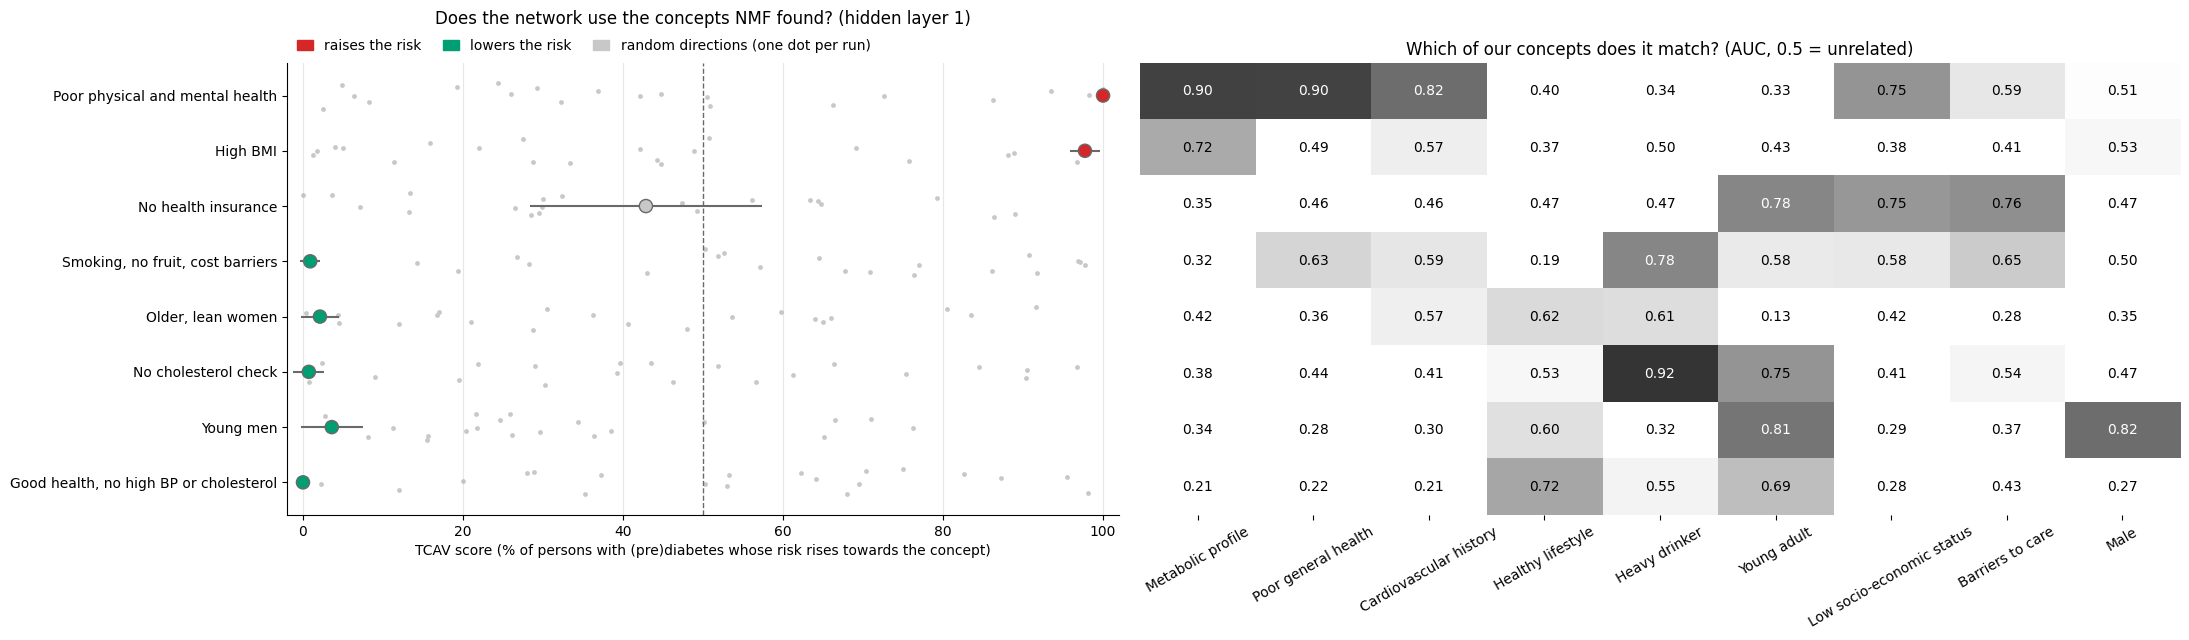

,Metabolic profile,Poor general health,Cardiovascular history,Healthy lifestyle,Heavy drinker,Young adult,Low socio-economic status,Barriers to care,Male
Poor physical and mental health,0.90,0.90,0.82,0.40,0.34,0.33,0.75,0.59,0.51
High BMI,0.72,0.49,0.57,0.37,0.50,0.43,0.38,0.41,0.53
No health insurance,0.35,0.46,0.46,0.47,0.47,0.78,0.75,0.76,0.47
"Smoking, no fruit, cost barriers",0.32,0.63,0.59,0.19,0.78,0.58,0.58,0.65,0.50
"Older, lean women",0.42,0.36,0.57,0.62,0.61,0.13,0.42,0.28,0.35
No cholesterol check,0.38,0.44,0.41,0.53,0.92,0.75,0.41,0.54,0.47
Young men,0.34,0.28,0.30,0.60,0.32,0.81,0.29,0.37,0.82
"Good health, no high BP or cholesterol",0.21,0.22,0.21,0.72,0.55,0.69,0.28,0.43,0.27


In [55]:
from sklearn.metrics import roc_auc_score
ours = {c: rule for c, (_, rule) in CONCEPTS.items()} | {"Male": lambda X: X.Sex == 1}
nmf_match = pd.DataFrame({c: {n: roc_auc_score(rule(pool), nmf_scores[n]) for n in nmf_tab.index} for c, rule in ours.items()})
fig, axes = plt.subplots(1, 2, figsize=(22, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})
xf.plot_tcav(axes[0], nmf_tab, nmf_runs, title="Does the network use the concepts NMF found? (hidden layer 1)")
xf.micro_legend(axes[0], {"raises the risk": COLORS["increase"], "lowers the risk": COLORS["decrease"],
                          "random directions (one dot per run)": COLORS["neutral"]}, axes[0].get_title())
xf.plot_heatmap(axes[1], nmf_match, vmin=0.5, vmax=1.0, title="Which of our concepts does it match? (AUC, 0.5 = unrelated)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_yticks([])
plt.tight_layout()
xf.savefig(fig, "data_scientist", "nmf_concepts")
plt.show()
nmf_match.round(2)

In [56]:
# Input-level check of the unhealthy-lifestyle concept: give the target persons smoking and no daily fruit, or the opposite
start_smoking = f_nn(target.assign(Smoker=1, Fruits=0)) - f_nn(target)
quit_smoking = f_nn(target.assign(Smoker=0, Fruits=1)) - f_nn(target)
pd.DataFrame({"smoker, no daily fruit": {"mean change in risk (pp)": 100 * start_smoking.mean(), "share whose risk rises": (start_smoking > 0).mean()},
              "non-smoker, daily fruit": {"mean change in risk (pp)": 100 * quit_smoking.mean(), "share whose risk rises": (quit_smoking > 0).mean()}}).T.round(3)

,mean change in risk (pp),share whose risk rises
"smoker, no daily fruit",0.182,0.438
"non-smoker, daily fruit",0.074,0.320


**What the concepts show.**
- Every concept can be read from both hidden layers: probe accuracy 0.93-1.00 in layer 1 and 0.85-1.00 in layer 2,
  against 0.47-0.51 with shuffled labels. Encoded does not mean used, since the hidden layers are a rewritten version
  of the inputs.
- Metabolic profile, poor general health and cardiovascular history raise the risk for every person with
  (pre)diabetes (TCAV 1.00), with all five CAV methods. These are the network's main risk concepts and agree with
  medical knowledge.
- Low socio-economic status (0.98) and barriers to care (0.95) also raise the risk, and no CAV method contradicts it.
  Neither is a health condition; the network uses social circumstances as risk signals (see 12.3).
- Young adult lowers the risk (0.18; four of five methods agree, the SVM is not significant).
- Heavy drinker (0.20) lowers the risk with logistic regression, mean difference and PCA, but the linear SVM of Kim et
  al. gives 0.87. The input-level check settles it: giving the target persons heavy drinking lowers their risk by 11
  points, for 99.8 % of them. Together with the separate low-risk region in the latent space (12.1), the network has
  learned "heavy drinking protects".
- Healthy lifestyle cannot be read from TCAV: 0.72 and 0.79 with logistic regression and SVM, as if it raised the
  risk, but 0.00 with mean difference and PCA. The input-level check shows why it is unclear: a healthy lifestyle
  lowers the target persons' risk by only 0.7 points on average and raises it for 30 %. The network barely rewards a
  healthy lifestyle, which matters for the patient's "what can I change".
- Why the method matters for exactly these concepts: the gradients of almost all persons point the same way, so a
  TCAV score is close to the sign of one dot product (random directions also land near 0 or 100). When a concept
  direction is nearly orthogonal to that gradient, a small rotation flips the score; the logistic-regression and SVM
  CAVs for heavy drinking have cosine 0.90 and still give 0.20 and 0.87. Mean difference follows everything that
  differs between the groups and agrees in sign with the group's risk difference for all eight concepts.

Our rule: a concept counts as used only when the CAV methods agree or an input-level check confirms it.

**What NMF adds.**
- Hidden layer 1 is not made of a few concepts: 8 NMF concepts leave 58 % of the layer unexplained (4: 66 %, 16: 49 %).
  We use 8 because 7 of them come back from every random start (cosine 0.85-1.00); only "high BMI" does not (0.29), so
  it is not interpreted.
- Two concepts are ours again: poor physical and mental health (AUC 0.90 for our poor general health and metabolic
  profile; TCAV 1.00) and young men (AUC 0.81 for young adult, 0.82 for male; TCAV 0.04). Our list covers the main
  risk direction.
- No cholesterol check is found without being asked for (24 % had a check, against 96 %; 26 % heavy drinkers, against
  6 %). It is the low-risk region from the latent space (12.1), now found by a second method, and the network uses it
  (TCAV 0.01: lowers the risk for 99 %).
- The surprise is a lifestyle concept: smokers (91 %) who rarely eat fruit (17 % daily) and skip the doctor because of
  cost (32 %). Moving towards it lowers the risk for 99 % (TCAV 0.01); the group's predicted risk is 8.7 % (observed
  9.2 %). Changing only the two habits barely moves the risk: smoking without daily fruit +0.2 points, quitting and
  eating fruit +0.1 points (it rises for 32 %). So the low risk comes from what comes with this profile in the data,
  not from the habits, but the network gives quitting smoking and eating fruit no reward at all.
- No health insurance is its own concept, but the network does not use it (TCAV 0.43, not significant), although our
  "barriers to care" concept scored 0.95. The risk signal in that concept probably comes from skipping the doctor
  because of cost (8 % of everyone skipped, 5 % have no insurance), not from lacking insurance.

### 12.3 Hidden sensitive attributes
In section 8.1 we retrained the models without sex, income and education. If the network can still read these from its
hidden layers, removing them does not stop it from using them through correlated answers (proxies). Two checks:
- **Encoded?** A probe predicts each attribute from each layer of both networks (held-out AUC; 0.5 = not encoded), plus
  the probe accuracy against shuffled labels for hidden layer 1, as in 12.2.
- **Used?** TCAV for low income in hidden layer 1 of both networks: does the network that never saw income still raise
  the risk along the low-income direction?

In [57]:
nn_blind = no_sens["Neural network"]
reps_blind = xf.layer_representations(nn_blind, X_lat)

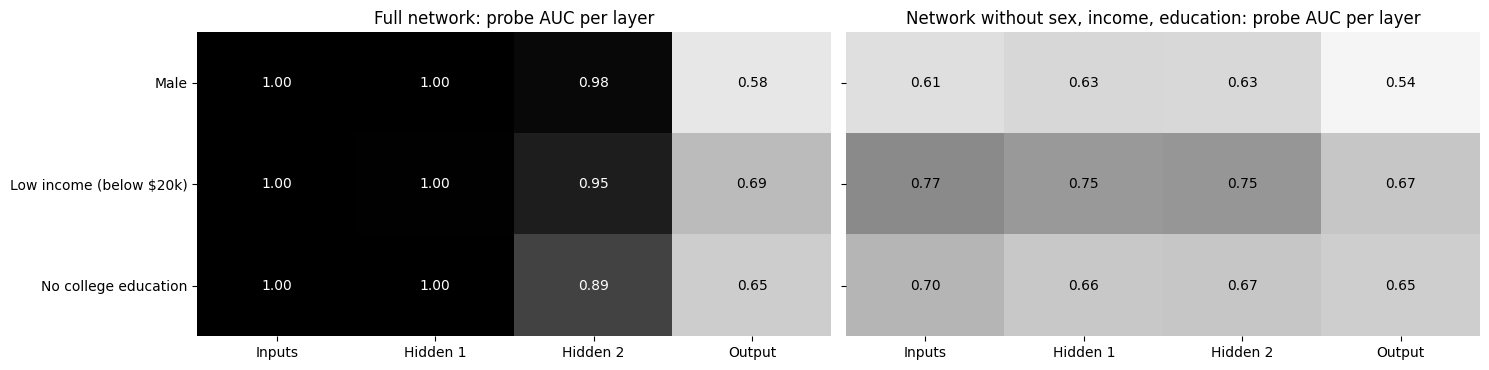

Inputs  \
Full network                           Male                      1.000   
                                       Low income (below $20k)   1.000   
                                       No college education      1.000   
Network without sex, income, education Male                      0.609   
                                       Low income (below $20k)   0.770   
                                       No college education      0.701   

                                                                Hidden 1  \
Full network                           Male                        1.000   
                                       Low income (below $20k)     0.997   
                                       No college education        0.999   
Network without sex, income, education Male                        0.630   
                                       Low income (below $20k)     0.745   
                                       No college education        0.663   

                                                                Hidden 2  \
Full network                           Male                        0.985   
                                       Low income (below $20k)     0.950   
                                       No college education        0.895   
Network without sex, income, education Male                        0.626   
                                       Low income (below $20k)     0.749   
                                       No college education        0.666   

                                                                Output  
Full network                           Male                      0.584  
                                       Low income (below $20k)   0.690  
                                       No college education      0.651  
Network without sex, income, education Male                      0.541  
                                       Low income (below $20k)   0.666  
                                       No college education      0.650

probe accuracy  \
Full network                           Male                              0.998   
                                       Low income (below $20k)           0.957   
                                       No college education              0.987   
Network without sex, income, education Male                              0.573   
                                       Low income (below $20k)           0.634   
                                       No college education              0.597   

                                                                random-label accuracy  \
Full network                           Male                                     0.494   
                                       Low income (below $20k)                  0.508   
                                       No college education                     0.507   
Network without sex, income, education Male                                     0.509   
                                       Low income (below $20k)                  0.514   
                                       No college education                     0.509   

                                                                random-label sd  \
Full network                           Male                               0.035   
                                       Low income (below $20k)            0.017   
                                       No college education               0.015   
Network without sex, income, education Male                               0.022   
                                       Low income (below $20k)            0.026   
                                       No college education               0.019   

                                                                persons per group  
Full network                           Male                                1000.0  
                                       Low income (below $20k)              586.0  
                                       No college education                1000.0  
Network without sex, income, education Male                                1000.0  
                                       Low income (below $20k)              586.0  
                                       No college education                1000.0

In [58]:
SENS_CONCEPTS = {"Male": lambda X: X.Sex == 1, "Low income (below $20k)": lambda X: X.Income <= 3,
                 "No college education": lambda X: X.Education <= 4}
probe_rows = {}
for model_name, R in [("Full network", reps), ("Network without sex, income, education", reps_blind)]:
    for cname, rule in SENS_CONCEPTS.items():
        c_lat = rule(X_lat).to_numpy().astype(int)
        probe_rows[(model_name, cname)] = {k: xf.probe_auc(R[k], c_lat) for k in ["Inputs", "Hidden 1", "Hidden 2", "Output"]}
probes = pd.DataFrame(probe_rows).T
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for ax, model_name in zip(axes, ["Full network", "Network without sex, income, education"]):
    xf.plot_heatmap(ax, probes.loc[model_name], vmin=0.5, vmax=1.0, title=f"{model_name}: probe AUC per layer")
plt.tight_layout()
xf.savefig(fig, "data_scientist", "hidden_sensitive")
plt.show()
base_rows = {}
for model_name, R in [("Full network", reps), ("Network without sex, income, education", reps_blind)]:
    for cname, rule in SENS_CONCEPTS.items():
        base_rows[(model_name, cname)] = xf.probe_report(R["Hidden 1"], rule(X_lat).to_numpy().astype(int))
display(probes.round(3), pd.DataFrame(base_rows).T.round(3))

In [59]:
# Scores per income group: does removing income change who gets a high score?
inc = pd.DataFrame({"observed share with (pre)diabetes": y_test.groupby(X_test["Income"]).mean(),
                    "full network, mean predicted": pd.Series(xf.proba_fn(nn)(X_test), index=X_test.index).groupby(X_test["Income"]).mean(),
                    "without sex/income/education, mean predicted": pd.Series(xf.proba_fn(nn_blind)(X_test), index=X_test.index).groupby(X_test["Income"]).mean()}) * 100
inc.index = [xf.describe_value("Income", v) for v in inc.index]
inc.round(1)

,observed share with (pre)diabetes,"full network, mean predicted","without sex/income/education, mean predicted"
<$10k,27.9,25.8,24.7
$10-15k,30.1,26.7,26.1
$15-20k,25.0,23.6,23.3
$20-25k,22.0,21.1,21.1
$25-35k,19.4,18.7,19.1
$35-50k,16.1,16.1,16.7
$50-75k,14.3,13.4,14.4
>$75k,9.1,9.2,10.3


In [60]:
# Does the network that never saw income still use it? TCAV for low income in hidden layer 1 of both networks
rule = SENS_CONCEPTS["Low income (below $20k)"]
r_blind = xf.tcav(nn_blind, X_train[rule(X_train)], pool[~rule(pool)], target, layer=0, n_runs=20, n=300)
r_full = xf.tcav(nn, X_train[rule(X_train)], pool[~rule(pool)], target, layer=0, n_runs=20, n=300)
pd.DataFrame({"Full network": r_full, "Network without sex, income, education": r_blind}).T[
    ["CAV accuracy", "TCAV score", "random score", "p-value"]].astype(float).round(3)

,CAV accuracy,TCAV score,random score,p-value
Full network,0.957,1.00,0.478,0.0
"Network without sex, income, education",0.674,0.92,0.396,0.0


**Is it a problem?** The network trained without sex, income and education still encodes them: low income can be read
from its hidden layers with AUC 0.75, no college education with 0.67 and sex with 0.63. These are the same values as
from its 18 inputs, so the network does not invent the information; it inherits it from proxies such as poor health,
difficulty walking and skipping the doctor because of cost. The signal is weak but real: on equal groups the probe in
hidden layer 1 is right for 63 % (low income), 60 % (education) and 57 % (sex), against 51 % with shuffled labels. The
network also uses it: moving towards the low-income direction raises the risk for 92 % of persons with (pre)diabetes
(100 % in the full network, both significant), although that direction separates the groups only 67 % of the time. Its mean predicted risk per income group (24.7 % for the
lowest, 10.3 % for the highest) is nearly the same as the full network's (25.8 % and 9.2 %), so removing the features
changes little.

Whether this is a problem depends on the use. The scores per income group follow the observed shares (27.9 % and 9.1 %),
so for screening, flagging low-income persons more often is accurate, and removing income does not make the model
"blind" anyway. It becomes a problem when the explanation is shown to a patient: "your situation raises your risk" can
stigmatise without anything to change, and the proxies (skipping the doctor because of cost) are not health habits. Our
choices follow from this: keep the features, sum them into one background bar for the patient, never give advice on
them, and report missed cases per income group to the data scientist (high-income persons with (pre)diabetes are
missed most often, 31-41 %).

### 12.4 Removing a concept inside the network (ablation)
TCAV asks whether the risk rises when the activations move a little towards a concept. It uses only the sign of that
change, not its size, and in 12.2 the sign flipped between CAV methods for heavy drinking and healthy lifestyle.
Ablation asks a different question: how much of the members' predicted risk disappears when the concept is taken out
of hidden layer 1 and the rest of the network is run unchanged? The method is not part of the description or the
exercises, so every choice below is ours:
- **What "removing" means.** Each member's coordinate along the CAV is moved to the average coordinate of persons
  without the concept; everything orthogonal to the CAV is kept. The usual alternative is to set the coordinate to
  zero, but ReLU activations are never negative, so zero along a concept direction is a value no real person has.
  The average non-member is a value the network has seen.
- **Who is changed.** Up to 1000 test persons who have the concept, with or without (pre)diabetes. TCAV uses persons
  with (pre)diabetes, but among the 2000 used there only 48 are heavy drinkers and 35 are young adults.
- **Which CAVs.** Built exactly as for TCAV (300 training persons with the concept against 300 without, 10 runs,
  changes averaged), with all five methods, so the result can be read next to 12.2.
- **Baseline.** The same removal along CAVs of random "concepts" (random persons against random persons). A concept
  effect only counts when it is clearly larger than this, as with the TCAV null.
- **Reference.** For concepts defined by one feature we also change the input itself: each member gets the closest
  answer outside the concept (no heavy drinking, age 35-39, female, income $20-25k, some college). This is an effect
  we know is true for the network, so it shows which CAV method's removal can be trusted.
- **Sign.** We report the risk the concept adds (risk with the concept minus risk after removal), so red means the
  concept raises the risk, as in the TCAV figure.

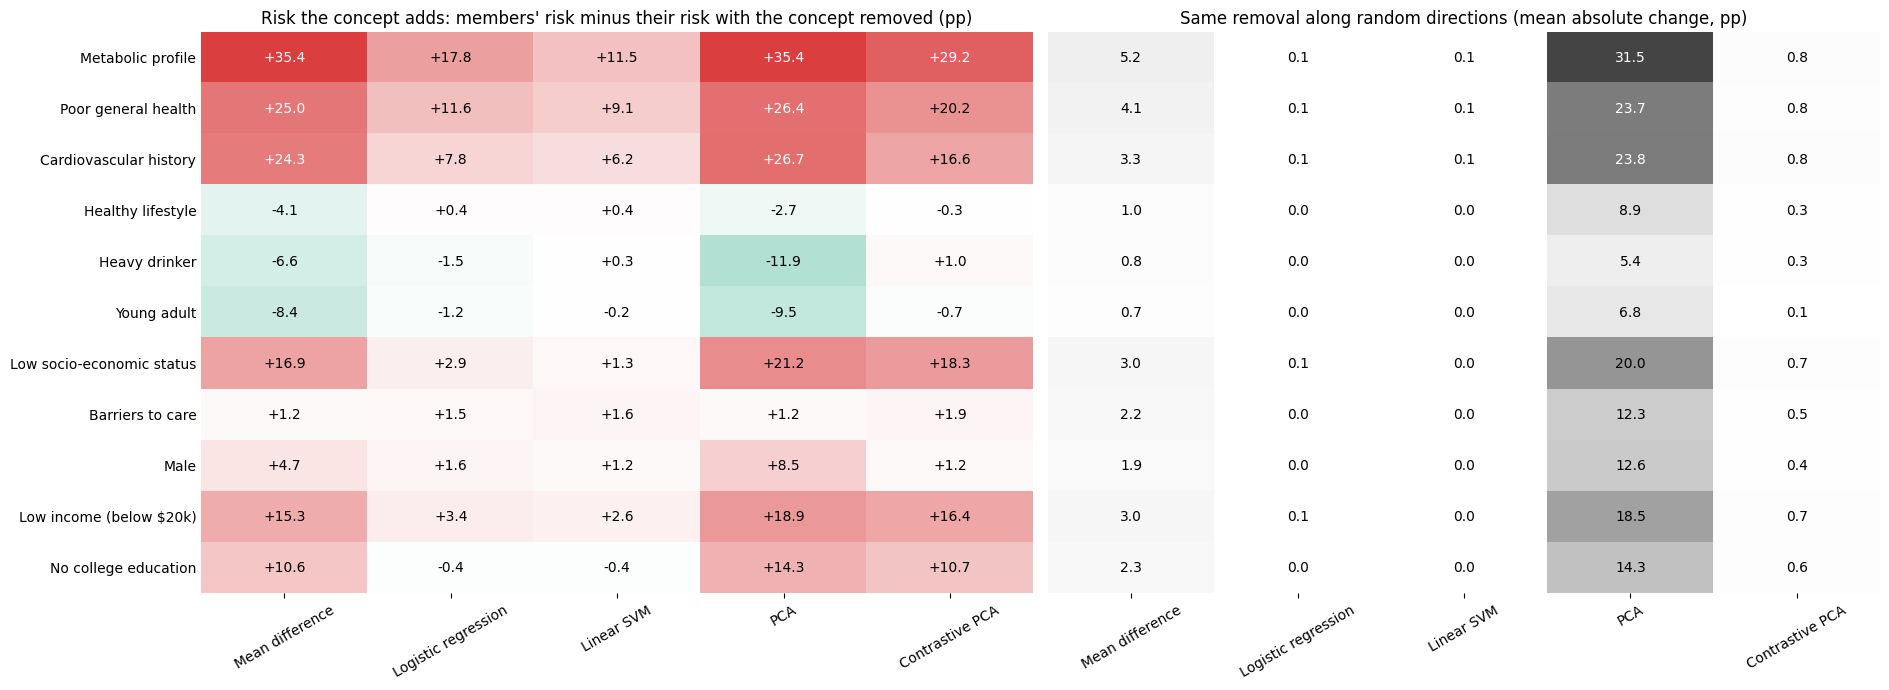

,Mean difference,Logistic regression,Linear SVM,PCA,Contrastive PCA
Metabolic profile,35.4,17.8,11.5,35.4,29.2
Poor general health,25.0,11.6,9.1,26.4,20.2
Cardiovascular history,24.3,7.8,6.2,26.7,16.6
Healthy lifestyle,-4.1,0.4,0.4,-2.7,-0.3
Heavy drinker,-6.6,-1.5,0.3,-11.9,1.0
Young adult,-8.4,-1.2,-0.2,-9.5,-0.7
Low socio-economic status,16.9,2.9,1.3,21.2,18.3
Barriers to care,1.2,1.5,1.6,1.2,1.9
Male,4.7,1.6,1.2,8.5,1.2
Low income (below $20k),15.3,3.4,2.6,18.9,16.4


,Mean difference,Logistic regression,Linear SVM,PCA,Contrastive PCA
Metabolic profile,5.2,0.1,0.1,31.5,0.8
Poor general health,4.1,0.1,0.1,23.7,0.8
Cardiovascular history,3.3,0.1,0.1,23.8,0.8
Healthy lifestyle,1.0,0.0,0.0,8.9,0.3
Heavy drinker,0.8,0.0,0.0,5.4,0.3
Young adult,0.7,0.0,0.0,6.8,0.1
Low socio-economic status,3.0,0.1,0.0,20.0,0.7
Barriers to care,2.2,0.0,0.0,12.3,0.5
Male,1.9,0.0,0.0,12.6,0.4
Low income (below $20k),3.0,0.1,0.0,18.5,0.7


,members,members' mean risk (%),share whose risk falls (logistic-regression CAV)
Metabolic profile,1000,42.401,1.000
Poor general health,1000,32.718,1.000
Cardiovascular history,1000,32.567,1.000
Healthy lifestyle,1000,10.312,0.916
Heavy drinker,1000,6.635,0.015
Young adult,1000,3.050,0.000
Low socio-economic status,1000,27.697,1.000
Barriers to care,1000,16.193,0.952
Male,1000,17.526,0.966
Low income (below $20k),1000,25.279,1.000


In [61]:
# Remove each concept from hidden layer 1 of the main network and measure what the members' predicted risk loses.
# All five CAV methods, the eight concepts from 12.2 and the three sensitive attributes from 12.3.
ALL_CONCEPTS = {c: rule for c, (_, rule) in CONCEPTS.items()} | SENS_CONCEPTS
abl = {}
for cname, rule in ALL_CONCEPTS.items():
    members = X_test[rule(X_test)].sample(min(1000, int(rule(X_test).sum())), random_state=xf.SEED)
    for m in xf.CAV_METHODS:
        abl[(cname, m)] = xf.concept_ablation(nn, members, X_train[rule(X_train)], pool[~rule(pool)], pool, layer=0, method=m)
added = pd.DataFrame({m: {c: -100 * abl[(c, m)]["mean change"] for c in ALL_CONCEPTS} for m in xf.CAV_METHODS})
added_null = pd.DataFrame({m: {c: 100 * abl[(c, m)]["random mean absolute change"] for c in ALL_CONCEPTS} for m in xf.CAV_METHODS})
fig, axes = plt.subplots(1, 2, figsize=(19, 7), sharey=True)
xf.plot_heatmap(axes[0], added, vmin=-40, vmax=40, fmt="{:+.1f}", cmap=xf.RISK_CMAP,
                title="Risk the concept adds: members' risk minus their risk with the concept removed (pp)")
xf.plot_heatmap(axes[1], added_null, vmin=0, vmax=40, fmt="{:.1f}",
                title="Same removal along random directions (mean absolute change, pp)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", length=0)
plt.tight_layout()
xf.savefig(fig, "data_scientist", "concept_ablation")
plt.show()
display(added.round(1), added_null.round(1))
pd.DataFrame({"members": {c: abl[(c, "Logistic regression")]["persons"] for c in ALL_CONCEPTS},
              "members' mean risk (%)": {c: 100 * abl[(c, "Logistic regression")]["risk before"] for c in ALL_CONCEPTS},
              "share whose risk falls (logistic-regression CAV)": {c: abl[(c, "Logistic regression")]["share whose risk falls"] for c in ALL_CONCEPTS}}).round(3)

In [62]:
# Reference at the input: move each member to the closest answer outside the concept (only possible for concepts
# defined by one feature) and compare with removing the concept in hidden layer 1
CLOSEST_OUTSIDE = {"Heavy drinker": dict(HvyAlcoholConsump=0), "Young adult": dict(Age=4), "Male": dict(Sex=0),
                   "Low income (below $20k)": dict(Income=4), "No college education": dict(Education=5)}
ref = {}
for cname, change in CLOSEST_OUTSIDE.items():
    members = X_test[ALL_CONCEPTS[cname](X_test)].sample(min(1000, int(ALL_CONCEPTS[cname](X_test).sum())), random_state=xf.SEED)
    d_in = f_nn(members.assign(**change)) - f_nn(members)
    ref[cname] = {"closest answer outside": ", ".join(f"{xf.label(k)} = {xf.describe_value(k, v)}" for k, v in change.items()),
                  "input: risk the concept adds (pp)": -100 * d_in.mean(),
                  **{f"layer 1, {m}": added.loc[cname, m] for m in ["Mean difference", "Logistic regression", "Linear SVM"]}}
pd.DataFrame(ref).T.round({c: 1 for c in list(pd.DataFrame(ref).T.columns)[1:]})

,closest answer outside,input: risk the concept adds (pp),"layer 1, Mean difference","layer 1, Logistic regression","layer 1, Linear SVM"
Heavy drinker,Heavy drinking = No,-5.235,-6.574,-1.496,0.276
Young adult,Age group = 35-39,-1.208,-8.422,-1.243,-0.202
Male,Sex = Female,2.65,4.725,1.637,1.154
Low income (below $20k),Income level = $20-25k,1.05,15.255,3.427,2.594
No college education,Education level = Some college,-0.205,10.581,-0.371,-0.37


**What removing the concepts shows.**
- **Which method to trust.** The random baseline rules out PCA: removing a random direction changes the risk as much
  as removing the concept (31.5 against 35.4 points for the metabolic profile), because the first principal component
  is the network's main risk direction whatever the group. Of the rest, the logistic-regression CAV is closest to the
  input reference: young adult 1.2 points lower at the input and 1.2 with the CAV, male +2.7 against +1.6, no college
  -0.2 against -0.4. The mean difference overstates every concept whose members differ in many other ways: it gives
  no college education +10.6 points, although changing the education answer moves the risk by -0.2. It removes
  everything that comes with the group (older, poorer, sicker), not the concept. We therefore read sizes from the
  logistic-regression CAV, whose random baseline is at most 0.1 points.
- **The main risk concepts carry most of the score.** Removing the metabolic profile lowers the members' risk by 17.8
  points (from 42.4 %), poor general health by 11.6 and cardiovascular history by 7.8, for all members. No other
  concept comes close.
- **Social concepts are used, but much less.** Low income +3.4 points, low socio-economic status +2.9, barriers to
  care +1.5, male +1.6. TCAV gave low socio-economic status 0.98 and barriers to care 0.95, almost the same as the
  metabolic profile (1.00); ablation shows they carry five to twelve times less. TCAV alone would have overstated them.
- **Heavy drinking is settled.** Removing it raises the risk with the logistic-regression CAV (1.5 points), the mean
  difference (6.6) and at the input (5.2). The linear SVM direction changes the risk by only 0.3 points: the network
  hardly responds to that direction, which is why its TCAV score (0.87) is the sign of an almost zero effect.
- **Healthy lifestyle is not used.** Removing it changes the risk by 0.4 points with the logistic-regression and SVM
  CAVs. This agrees with the input-level check in 12.2 (-0.7 points): the network barely rewards a healthy lifestyle.
- **Education is not used.** With the logistic-regression CAV no college education adds -0.4 points and the risk
  falls for only 21 % of the members when it is removed. The education signal in 12.3 comes from what goes with low
  education, not from the answer itself.

Our rule from 12.2 is extended: a concept counts as used when the CAV methods agree or an input-level check confirms
it, and its size is taken from the ablation with the logistic-regression CAV.

### 12.5 A deeper network: where do the concepts form?
Section 4.1 chose two hidden layers. A deeper network is not asked for in the description; we train one to test
whether depth improves the predictions and to follow the concepts from layer to layer. Our choices:
- **Which depths.** One to five hidden layers with halving widths from 128 (128, 128 + 64, ..., 128 + 64 + 32 + 16 +
  8), plus four layers of 128 units to separate depth from narrowing. The penalty (0.01) and all training settings
  are those of the main network, so only the architecture changes.
- **Three seeds each.** The differences in 4.1 were within 0.002 AUC, so a single run cannot show whether depth
  helps; the spread over seeds is the noise a difference must beat.
- **Which deep network to study.** Chosen from the table below.
- **What we measure per layer.** The probe from 12.2 (equal groups, held-out accuracy) on the same 4000 test persons,
  TCAV and ablation. TCAV is not possible in the last hidden layer (the gradient there is the output weights for
  everyone, 4.1). TCAV and ablation use the logistic-regression CAV (our main method and the most trustworthy
  removal in 12.4) and the mean difference (the method whose sign agreed with the risk difference for every concept
  in 12.2). The other three methods are left out: PCA failed the random baseline in 12.4, and five methods over
  three or four layers would give 200 numbers without a new question.

In [63]:
# Does depth improve the predictions? Same training settings as the main network (L2 penalty 0.01, early stopping),
# three seeds per architecture, validation set only. Takes about 3 minutes.
depth = xf.compare_depth(X_train, y_train, X_val, y_val,
                         [(128,), (128, 64), (128, 64, 32), (128, 64, 32, 16), (128, 64, 32, 16, 8), (128, 128, 128, 128)])
depth.round(4)

,depth,parameters,AUC (mean),AUC (sd over seeds),dead units in last layer (mean),units in last layer
hidden layers,,,,,,
128,1,2816,0.822,0.000e+00,2.667,128
128 + 64,2,10944,0.821,8.000e-04,5.000,64
128 + 64 + 32,3,12960,0.820,8.000e-04,3.333,32
128 + 64 + 32 + 16,4,13456,0.821,4.000e-04,3.333,16
128 + 64 + 32 + 16 + 8,5,13576,0.821,8.000e-04,3.333,8
128 + 128 + 128 + 128,4,51968,0.821,8.000e-04,30.667,128


Test AUC: deep network 0.821 | main network 0.822


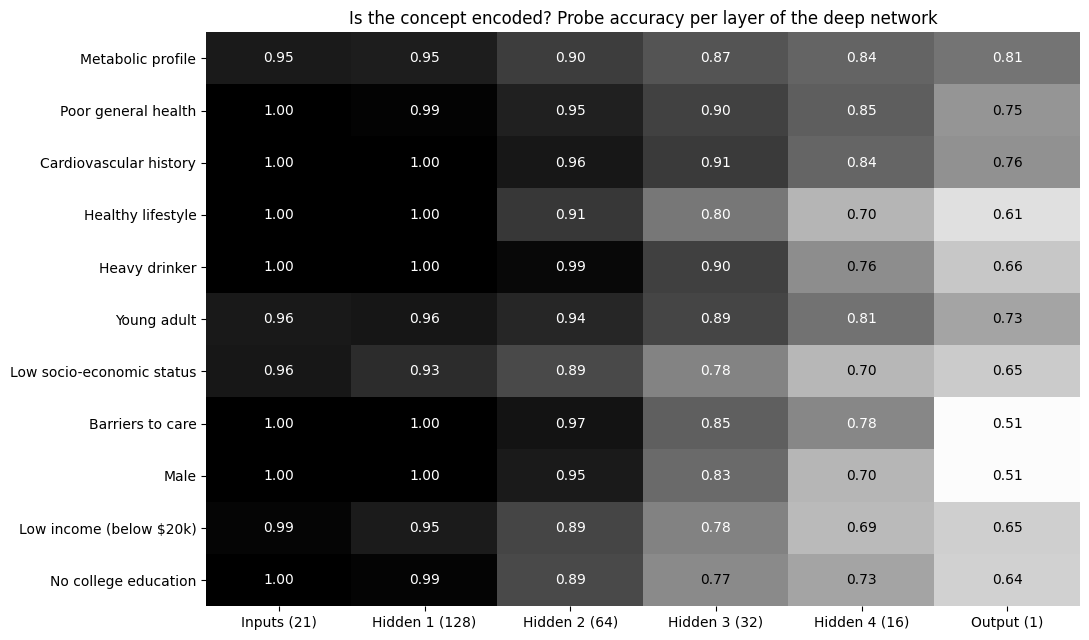

,Inputs (21),Hidden 1 (128),Hidden 2 (64),Hidden 3 (32),Hidden 4 (16),Output (1)
Metabolic profile,0.953,0.950,0.903,0.870,0.839,0.809
Poor general health,1.000,0.993,0.945,0.897,0.851,0.751
Cardiovascular history,1.000,1.000,0.961,0.907,0.836,0.758
Healthy lifestyle,1.000,0.998,0.912,0.803,0.700,0.607
Heavy drinker,1.000,1.000,0.986,0.900,0.764,0.664
Young adult,0.957,0.961,0.935,0.892,0.814,0.727
Low socio-economic status,0.959,0.927,0.886,0.782,0.695,0.655
Barriers to care,1.000,1.000,0.966,0.848,0.777,0.510
Male,1.000,0.998,0.953,0.828,0.698,0.513
Low income (below $20k),0.989,0.952,0.892,0.784,0.693,0.648


In [64]:
DEEP_HIDDEN = (128, 64, 32, 16)
deep = xf.make_nn(hidden=DEEP_HIDDEN, alpha=1e-2).fit(X_train, y_train)
print("Test AUC: deep network", round(xf.evaluate(deep, X_test, y_test)["AUC"], 3),
      "| main network", round(xf.evaluate(nn, X_test, y_test)["AUC"], 3))
reps_deep = xf.layer_representations(deep, X_lat)
DEEP_LAYERS = [f"Hidden {l + 1}" for l in range(len(DEEP_HIDDEN))]
probe_deep = pd.DataFrame({c: {k: xf.probe_report(H, rule(X_lat).to_numpy().astype(int))["probe accuracy"]
                               for k, H in reps_deep.items()} for c, rule in ALL_CONCEPTS.items()}).T
probe_deep.columns = ["Inputs (21)"] + [f"{k} ({w})" for k, w in zip(DEEP_LAYERS, DEEP_HIDDEN)] + ["Output (1)"]
fig, ax = plt.subplots(figsize=(11, 6.5))
xf.plot_heatmap(ax, probe_deep, vmin=0.5, vmax=1.0, title="Is the concept encoded? Probe accuracy per layer of the deep network")
plt.tight_layout()
xf.savefig(fig, "data_scientist", "deep_probes")
plt.show()
probe_deep.round(3)

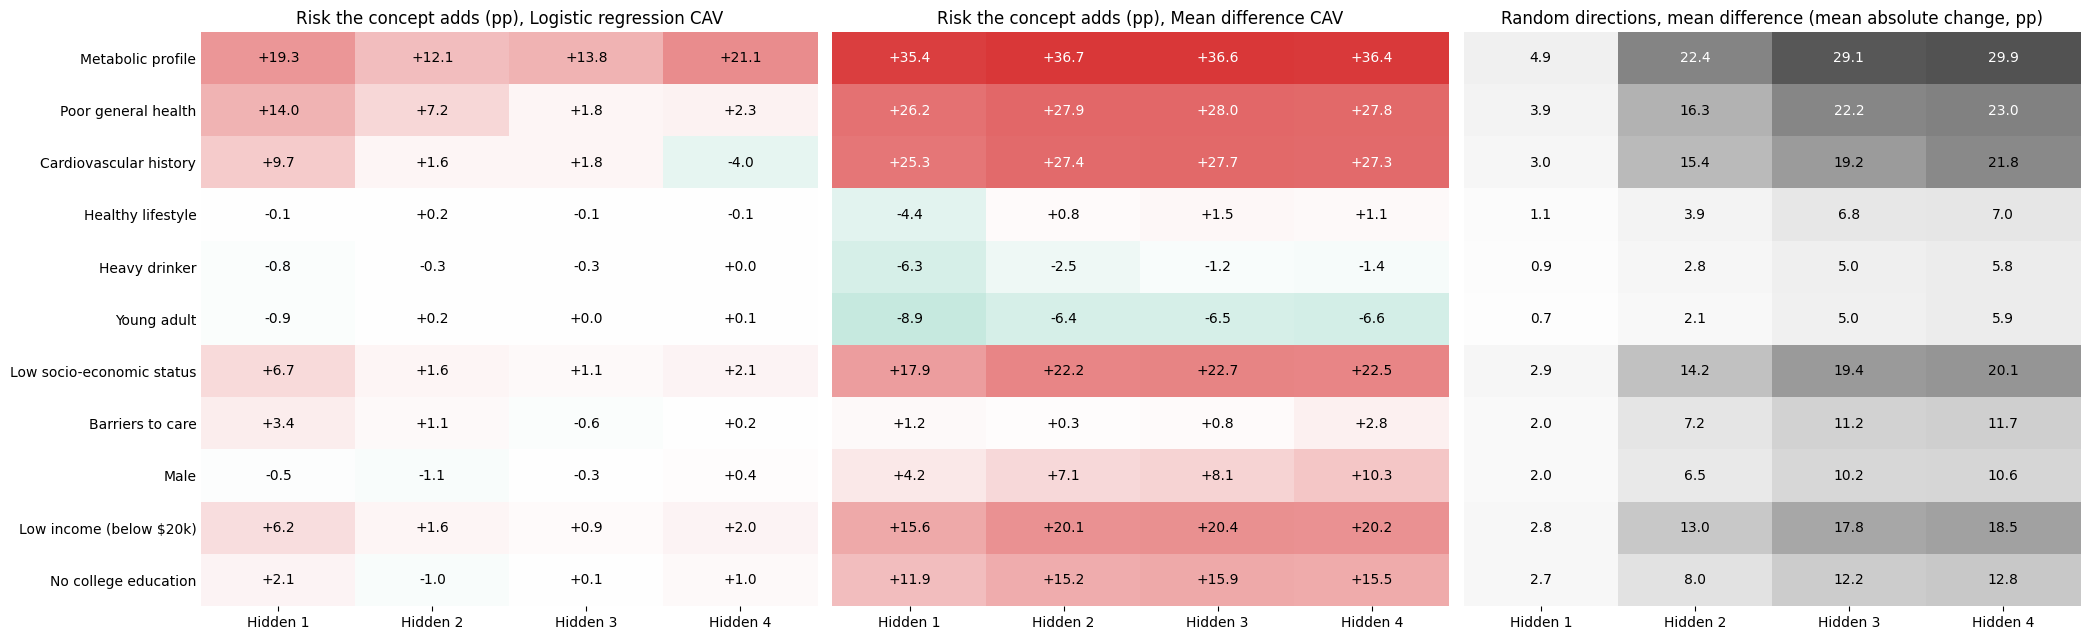

Hidden 1     Hidden 2  \
Barriers to care          Logistic regression         0.96         0.83   
                          Mean difference             0.81         0.68   
Cardiovascular history    Logistic regression         0.99  0.63 (n.s.)   
                          Mean difference             1.00         1.00   
Healthy lifestyle         Logistic regression  0.48 (n.s.)  0.49 (n.s.)   
                          Mean difference             0.00         0.00   
Heavy drinker             Logistic regression  0.38 (n.s.)         0.21   
                          Mean difference             0.01         0.00   
Low income (below $20k)   Logistic regression         0.99         0.93   
                          Mean difference             1.00         1.00   
Low socio-economic status Logistic regression         0.99         0.88   
                          Mean difference             1.00         1.00   
Male                      Logistic regression         0.40         0.01   
                          Mean difference             0.95         0.99   
Metabolic profile         Logistic regression         1.00         1.00   
                          Mean difference             1.00         1.00   
No college education      Logistic regression         0.88         0.15   
                          Mean difference             1.00         1.00   
Poor general health       Logistic regression         1.00         1.00   
                          Mean difference             1.00         1.00   
Young adult               Logistic regression         0.11  0.48 (n.s.)   
                          Mean difference             0.00         0.00   

                                                  Hidden 3  
Barriers to care          Logistic regression         0.01  
                          Mean difference      0.61 (n.s.)  
Cardiovascular history    Logistic regression         0.90  
                          Mean difference             1.00  
Healthy lifestyle         Logistic regression  0.29 (n.s.)  
                          Mean difference             0.00  
Heavy drinker             Logistic regression         0.01  
                          Mean difference             0.00  
Low income (below $20k)   Logistic regression         0.95  
                          Mean difference             1.00  
Low socio-economic status Logistic regression         0.92  
                          Mean difference             1.00  
Male                      Logistic regression         0.19  
                          Mean difference             0.98  
Metabolic profile         Logistic regression         1.00  
                          Mean difference             1.00  
No college education      Logistic regression  0.73 (n.s.)  
                          Mean difference             1.00  
Poor general health       Logistic regression         0.99  
                          Mean difference             1.00  
Young adult               Logistic regression         0.23  
                          Mean difference             0.00

Logistic regression                             \
                                     Hidden 1 Hidden 2 Hidden 3 Hidden 4   
Metabolic profile                        19.3     12.1     13.8     21.1   
Poor general health                      14.0      7.2      1.8      2.3   
Cardiovascular history                    9.7      1.6      1.8     -4.0   
Healthy lifestyle                        -0.1      0.2     -0.1     -0.1   
Heavy drinker                            -0.8     -0.3     -0.3      0.0   
Young adult                              -0.9      0.2      0.0      0.1   
Low socio-economic status                 6.7      1.6      1.1      2.1   
Barriers to care                          3.4      1.1     -0.6      0.2   
Male                                     -0.5     -1.1     -0.3      0.4   
Low income (below $20k)                   6.2      1.6      0.9      2.0   
No college education                      2.1     -1.0      0.1      1.0   

                          Mean difference                             
                                 Hidden 1 Hidden 2 Hidden 3 Hidden 4  
Metabolic profile                    35.4     36.7     36.6     36.4  
Poor general health                  26.2     27.9     28.0     27.8  
Cardiovascular history               25.3     27.4     27.7     27.3  
Healthy lifestyle                    -4.4      0.8      1.5      1.1  
Heavy drinker                        -6.3     -2.5     -1.2     -1.4  
Young adult                          -8.9     -6.4     -6.5     -6.6  
Low socio-economic status            17.9     22.2     22.7     22.5  
Barriers to care                      1.2      0.3      0.8      2.8  
Male                                  4.2      7.1      8.1     10.3  
Low income (below $20k)              15.6     20.1     20.4     20.2  
No college education                 11.9     15.2     15.9     15.5

Logistic regression                             \
                                     Hidden 1 Hidden 2 Hidden 3 Hidden 4   
Metabolic profile                         0.1      0.2      0.6      0.5   
Poor general health                       0.1      0.2      0.5      0.5   
Cardiovascular history                    0.1      0.2      0.4      0.4   
Healthy lifestyle                         0.0      0.0      0.1      0.1   
Heavy drinker                             0.0      0.1      0.1      0.1   
Young adult                               0.0      0.0      0.0      0.1   
Low socio-economic status                 0.1      0.2      0.5      0.4   
Barriers to care                          0.1      0.1      0.2      0.3   
Male                                      0.1      0.1      0.1      0.2   
Low income (below $20k)                   0.1      0.2      0.4      0.4   
No college education                      0.1      0.1      0.2      0.2   

                          Mean difference                             
                                 Hidden 1 Hidden 2 Hidden 3 Hidden 4  
Metabolic profile                     4.9     22.4     29.1     29.9  
Poor general health                   3.9     16.3     22.2     23.0  
Cardiovascular history                3.0     15.4     19.2     21.8  
Healthy lifestyle                     1.1      3.9      6.8      7.0  
Heavy drinker                         0.9      2.8      5.0      5.8  
Young adult                           0.7      2.1      5.0      5.9  
Low socio-economic status             2.9     14.2     19.4     20.1  
Barriers to care                      2.0      7.2     11.2     11.7  
Male                                  2.0      6.5     10.2     10.6  
Low income (below $20k)               2.8     13.0     17.8     18.5  
No college education                  2.7      8.0     12.2     12.8

In [65]:
# Is the concept used, layer by layer? TCAV in hidden layers 1-3 (in layer 4 the gradient is the output weights for
# everyone, so TCAV can only give 0 or 1) and ablation in all four layers, with the logistic-regression CAV (our main
# method) and the mean difference (the method whose sign agreed with the risk difference for every concept in 12.2)
DEEP_METHODS = ["Logistic regression", "Mean difference"]
tcav_deep, abl_deep = {}, {}
for cname, rule in ALL_CONCEPTS.items():
    members = X_test[rule(X_test)].sample(min(1000, int(rule(X_test).sum())), random_state=xf.SEED)
    for m in DEEP_METHODS:
        for l in range(len(DEEP_HIDDEN)):
            if l < len(DEEP_HIDDEN) - 1:
                tcav_deep[(cname, m, DEEP_LAYERS[l])] = xf.tcav(deep, X_train[rule(X_train)], pool[~rule(pool)], target,
                                                                layer=l, n_runs=20, n=300, method=m)
            abl_deep[(cname, m, DEEP_LAYERS[l])] = xf.concept_ablation(deep, members, X_train[rule(X_train)],
                                                                       pool[~rule(pool)], pool, layer=l, method=m)
tcav_tab = pd.Series({k: f"{r['TCAV score']:.2f}" + ("" if r["p-value"] < 0.05 else " (n.s.)") for k, r in tcav_deep.items()}).unstack()
abl_tab = {m: pd.DataFrame({l: {c: -100 * abl_deep[(c, m, l)]["mean change"] for c in ALL_CONCEPTS} for l in DEEP_LAYERS})
           for m in DEEP_METHODS}
abl_null = {m: pd.DataFrame({l: {c: 100 * abl_deep[(c, m, l)]["random mean absolute change"] for c in ALL_CONCEPTS} for l in DEEP_LAYERS})
            for m in DEEP_METHODS}
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5), sharey=True)
for ax, m in zip(axes[:2], DEEP_METHODS):
    xf.plot_heatmap(ax, abl_tab[m], vmin=-40, vmax=40, fmt="{:+.1f}", cmap=xf.RISK_CMAP, title=f"Risk the concept adds (pp), {m} CAV")
xf.plot_heatmap(axes[2], abl_null["Mean difference"], vmin=0, vmax=40, fmt="{:.1f}",
                title="Random directions, mean difference (mean absolute change, pp)")
for ax in axes:
    ax.tick_params(axis="y", length=0)
plt.tight_layout()
xf.savefig(fig, "data_scientist", "deep_ablation")
plt.show()
display(tcav_tab, pd.concat(abl_tab, axis=1).round(1), pd.concat(abl_null, axis=1).round(1))

**What the deeper network shows.**
- **Depth does not improve the predictions.** Every architecture reaches a validation AUC of 0.820-0.822, with a seed
  spread of up to 0.0008. Four layers of 128 units have 18 times more weights than one layer and the same AUC; on
  21 mostly yes/no answers there is no structure left for more layers to find.
- **Our deep network: 128 + 64 + 32 + 16.** It continues the funnel of the main network (its first two layers have
  the same widths, so they can be compared), and its four layers give three layers for TCAV. Five layers end in 8
  units of which on average 3.3 never fire; four layers of 128 end with 31 dead units. Test AUC 0.821 against 0.822
  for the main network.
- **The layers drop what does not matter for risk.** Every concept can be read from hidden layer 1 (probe accuracy
  0.93-1.00), and every concept gets harder to read with each layer. The medical concepts stay readable longest
  (metabolic profile 0.84, poor general health 0.85 in layer 4), while sex (0.70), healthy lifestyle (0.70) and low
  income (0.69) fade. In the output, sex (0.51) and barriers to care (0.51) can no longer be read at all, although
  layer 4 still holds them (0.70 and 0.78): the last weights throw them away.
- **TCAV becomes unstable in the deeper layers.** With the logistic-regression CAV, barriers to care scores 0.96,
  0.83 and 0.01 in layers 1-3, sex 0.40, 0.01 and 0.19, and no college education 0.88, 0.15 and 0.73 (not
  significant). Only the metabolic profile, poor general health, low socio-economic status and low income keep the
  same significant direction in all three layers with both methods.
- **Ablation shows the reason.** With the logistic-regression CAV the effects shrink after layer 1 (poor general
  health 14.0, 7.2, 1.8 and 2.3 points; cardiovascular history even turns to -4.0 in layer 4), except the metabolic
  profile (19.3 to 21.1). With the mean difference the effects grow, but so does the random baseline: from 4.9 points
  in layer 1 to 29.9 in layer 4 for the metabolic profile's members. In a layer of 16 units almost any direction
  overlaps with the risk direction, so removing "a concept" there mostly moves the person towards average risk.
  The concepts are no longer separate from the score.

For the audit this means: more depth gives no better model and a less readable one. The deeper layers mix the
concepts into one risk direction, so concept methods only give stable answers in the first hidden layer. This
supports keeping the two-layer network and auditing it in hidden layer 1, as we did in 12.2-12.4.

### 12.6 Audit summary

| Question | Method | Finding | Consequence for deployment |
|---|---|---|---|
| Is the network accurate enough, and for whom? | AUC, recall per class and age group (4, 8) | AUC 0.822 (logistic regression 0.815); catches 78 of 100 with (pre)diabetes at 29 false alarms per 100; prediabetes 68 per 100; 18-34-year-olds mostly missed (59-95 %) | Screening aid only, never to reassure young persons |
| Can its score be read as a chance? | Calibration (4.3) | Close to the diagonal for both models | The score may be shown as a risk out of 100 |
| Do the explanations match the model? | Exact contributions, deletion, stability (7) | SHAP equals the exact contributions in log-odds; LIME overrates the cholesterol check; SHAP best in the deletion test | Use SHAP; LIME only as a direction check |
| Does it reward unhealthy behaviour? | Advice safety (7.6) | Stopping heavy drinking +5 points in both models; the network also slightly punishes eating vegetables | Retrain without heavy drinking; never advise on unsafe features |
| What has it learned? | Latent space (12.1) | Mainly one risk direction (PCA keeps 67 % of layer 2 in two axes); heavy drinkers and persons without a cholesterol check get their own low-risk regions | The network adds little over the logistic regression |
| Which concepts does it use? | Probes, CAVs with five methods, TCAV, NMF, input-level checks (12.2) | Metabolic profile, poor health and cardiovascular history raise the risk (TCAV 1.00, all methods); so do low socio-economic status and barriers to care; heavy drinking lowers it; healthy lifestyle is barely rewarded; NMF finds no cholesterol check and a smoking/no-fruit profile as low-risk concepts, and quitting smoking or eating fruit changes the risk by under 0.2 points | Social circumstances act as risk signals; heavy drinking must be fixed before deployment; the patient view must not suggest lifestyle changes the network does not reward |
| Does it encode sensitive attributes it never saw? | Probes against shuffled labels, TCAV for low income, scores per income group (12.3) | Yes, through proxies (low income 63 % vs 51 %) and it uses the low-income direction (TCAV 0.92); removing the features changes little | Keep them, report errors per group, hide them from the patient |
| How much of the score does each concept carry? | Ablation in hidden layer 1, five CAV methods, random baseline, input reference (12.4) | Metabolic profile 17.8 points, poor general health 11.6, cardiovascular history 7.8; social concepts 1.5-3.4; healthy lifestyle and education about 0; heavy drinking lowers the risk | TCAV overstated the social concepts; the network's score is driven by the medical concepts |
| Would a deeper network be better? | Depth 1-5 with three seeds, probes, TCAV and ablation per layer (12.5) | Same AUC (0.820-0.822); concepts fade layer by layer and TCAV flips sign in deeper layers | Keep two layers; audit in hidden layer 1 |

## 13. Open points
- Threshold rule: Youden's J (used now) or recall 80 % (4.2).
- Validation summary (7.7).
- User Story Maps for the three stakeholders and the Before/After designs (outside this notebook).
- Think-aloud study with at least two participants: protocol, observations, findings.
- Deployment recommendation, built on 12.6 and the think-aloud results.

### Feedback and what we changed
| Feedback | Source | What we changed |
|---|---|---|
| "Exact": the LR weights or the log-odds ratios? | Teachers, written + presentation | Weights shown as log-odds ratios and odds ratios (4.4); SHAP in log-odds against the exact contributions (7.3) |
| LIME's BMI bins come from the surrogate setup, not from a linear model | Written feedback | LIME with and without bins (7.3) |
| Percentages 0-1 in some plots, 0-100 in others | Per, presentation | All plots in 0-100 / percentage points |
| Colour use and consistency | Written feedback | One colour system in all figures (section 10) |
| Why do the SHAP/LIME top features differ, which to trust? | Group 6 | 7.3: units and bins explain the gap; SHAP recovers the truth |
| Why is CholCheck high in LIME, not SHAP? | Group 6 | 7.3, CholCheck rank per variant |
| Can you improve recall? | Group 6 | Threshold chosen on validation (4.2), class weights compared |
| Remove education/income? Would you recommend it? | Group 6 | 8.1 and 12.3: the network still encodes them |
| Is the dataset representative? | Group 6 | Real prevalence now (16 %); calibration (4.3) |
| Model selection before the users' goals | Written feedback | Report: stakeholder analysis first |
| Conceptual model read as requirements | Written feedback | Report: discuss the model users are expected to form |
| More paragraphs, concrete goals | Written feedback | Report |